# Proyecto Centinela — Nivel del río Cauca + Sentinel-1
**Profundización I: Deep Learning · Maestría en Ciencia de Datos · USTA** · Fases 1 y 2

Un solo cuaderno, ejecutable de arriba hacia abajo.

| Parte | Contenido |
|---|---|
| **0. Configuración** | Rutas, constantes y credenciales (sin claves en el código; se leen de los Secretos de Colab o se piden con `getpass`) |
| **Fase 1** | Serie IDEAM (La Virginia – AUT., 26177030) → regresión del nivel a +12 h con MLP (V1 y V2) frente a persistencia; MLP binario y experimento de regularización |
| **Fase 2** | Sentinel-1 (COG de Copernicus S3) → Sigma0 VV/VH por distancia al cauce → modelo multimodal (GRU + CNN) frente a la línea base; controles; ramas A (CNN), B (recurrentes) y C (fusión) |

**Reglas del cuaderno:** las carpetas, nombres de archivo y variables son los del proyecto. El procesamiento SAR es reanudable y se apoya en archivos ya guardados en Google Drive: las celdas 2.1 a 2.7 (catálogo, S3, procesamiento) requieren credenciales de Copernicus y la carpeta del proyecto en Drive; con todas las escenas procesadas no se vuelve a descargar nada. Las salidas que se ven son las de la ejecución real.

## 0. Configuración

In [1]:
%pip -q install s3fs pyogrio

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gcsfs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2026.9.0 which is incompatible.
datasets 4.8.5 requires fsspec[http]<=2026.2.0,>=2023.1.0, but you have fsspec 2026.9.0 which is incompatible.


In [2]:

import os
import re
import gc
import copy
import glob
import time
import inspect
import traceback
import warnings
import xml.etree.ElementTree as ET
from datetime import datetime, timezone
from zoneinfo import ZoneInfo

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=FutureWarning)

from google.colab import drive, files
drive.mount("/content/drive")

# ----------------------------------------------------------------------
# Carpetas del proyecto (las de Fase 2 ya existen en el proyecto)
# ----------------------------------------------------------------------
CARPETA_BASE = "/content/drive/MyDrive/Centinela"
CARPETA_FASE_1 = os.path.join(CARPETA_BASE, "Fase_1")
CARPETA_FASE_2 = os.path.join(CARPETA_BASE, "Fase_2")

for carpeta in [CARPETA_BASE, CARPETA_FASE_1, CARPETA_FASE_2]:
    os.makedirs(carpeta, exist_ok=True)

# ----------------------------------------------------------------------
# Área de estudio (provisional): La Virginia, Risaralda, río Cauca
# ----------------------------------------------------------------------
long_oeste = -75.95
long_este = -75.80
lat_sur = 4.85
lat_norte = 4.98

LON_MIN, LON_MAX = long_oeste, long_este
LAT_MIN, LAT_MAX = lat_sur, lat_norte

poligono = (
    f"{long_oeste} {lat_sur},"
    f"{long_este} {lat_sur},"
    f"{long_este} {lat_norte},"
    f"{long_oeste} {lat_norte},"
    f"{long_oeste} {lat_sur}"
)

# ----------------------------------------------------------------------
# Credenciales de Copernicus Data Space (S3).
# NUNCA se escriben en el cuaderno: se leen de los Secretos de Colab
# (COPERNICUS_ACCESS_KEY / COPERNICUS_SECRET_KEY) o se piden con getpass.
# No se usa Session Token.
# ----------------------------------------------------------------------
from getpass import getpass

def leer_credencial(nombre_secreto, mensaje):
    try:
        from google.colab import userdata
        valor = userdata.get(nombre_secreto)
        if valor:
            return valor.strip()
    except Exception:
        pass
    return getpass(mensaje).strip()

ACCESS_KEY = leer_credencial(
    "COPERNICUS_ACCESS_KEY", "Ingresa tu Access Key: "
)
SECRET_KEY = leer_credencial(
    "COPERNICUS_SECRET_KEY", "Ingresa tu Secret Key: "
)

assert ACCESS_KEY, "Falta la Access Key."
assert SECRET_KEY, "Falta la Secret Key."
print("Configuración lista. Las credenciales no se muestran.")

Mounted at /content/drive
Ingresa tu Access Key: ··········
Ingresa tu Secret Key: ··········
Configuración lista. Las credenciales no se muestran.


---
# FASE 1 — Serie de nivel del IDEAM y línea base temporal
Regresión del nivel del río **12 horas adelante** a partir del historial reciente. Solo se usan registros con `nivelAprobacion == "Definitivo"`.

### 1.1 Lectura de la serie IDEAM (solo registros definitivos)

In [3]:
ruta_nivel = os.path.join(CARPETA_BASE, "0026177030-NIVEL_H.csv")

if not os.path.exists(ruta_nivel):
    print("Selecciona el archivo 0026177030-NIVEL_H.csv")
    archivo_cargado = files.upload()
    ruta_nivel = list(archivo_cargado.keys())[0]

df_nivel = pd.read_csv(ruta_nivel)

df_nivel["fechaObservacion"] = pd.to_datetime(
    df_nivel["fechaObservacion"], errors="coerce"
)
df_nivel["valorObservado"] = pd.to_numeric(
    df_nivel["valorObservado"], errors="coerce"
)

df_nivel_definitivo = df_nivel[
    df_nivel["nivelAprobacion"].str.strip() == "Definitivo"
].copy()

df_nivel_definitivo = (
    df_nivel_definitivo
    .dropna(subset=["fechaObservacion", "valorObservado"])
    .sort_values("fechaObservacion")
    .reset_index(drop=True)
)
df_nivel_definitivo["anio"] = df_nivel_definitivo["fechaObservacion"].dt.year

print("Registros totales:", len(df_nivel))
print("Registros definitivos:", len(df_nivel_definitivo))
print(
    "Periodo definitivo:",
    df_nivel_definitivo["fechaObservacion"].min(),
    "->",
    df_nivel_definitivo["fechaObservacion"].max()
)
print("Fechas duplicadas:",
      df_nivel_definitivo["fechaObservacion"].duplicated().sum())

df_nivel_definitivo.to_csv(
    os.path.join(CARPETA_FASE_1, "centinela_nivel_hidrologico_definitivo.csv"),
    index=False, encoding="utf-8-sig"
)

Selecciona el archivo 0026177030-NIVEL_H.csv


Saving 0026177030-NIVEL_H.csv to 0026177030-NIVEL_H.csv
Registros totales: 136301
Registros definitivos: 11784
Periodo definitivo: 2020-01-01 06:00:00 -> 2025-12-31 23:00:00
Fechas duplicadas: 0


### 1.2 Conjunto de modelado
La frecuencia de observación cambia: ≈12 h (06:00 y 18:00) hasta 2024 y horaria en 2025. Por eso el objetivo se une **por fecha exacta** (`fechaObservacion + 12 h`), sin interpolar, y los rezagos también. Los ejemplos con algún predictor o con el objetivo faltante se descartan.

In [4]:
serie_modelado = (
    df_nivel_definitivo[["fechaObservacion", "valorObservado"]]
    .sort_values("fechaObservacion")
    .reset_index(drop=True)
    .copy()
)

serie_modelado["fecha_objetivo"] = (
    serie_modelado["fechaObservacion"] + pd.Timedelta(hours=12)
)

tabla_objetivos = serie_modelado[
    ["fechaObservacion", "valorObservado"]
].rename(columns={
    "fechaObservacion": "fecha_objetivo",
    "valorObservado": "nivel_objetivo_12h_cm"
})

dataset_prediccion = serie_modelado.merge(
    tabla_objetivos, on="fecha_objetivo", how="left", validate="one_to_one"
)
dataset_prediccion["anio"] = dataset_prediccion["fechaObservacion"].dt.year
dataset_prediccion = (
    dataset_prediccion[dataset_prediccion["nivel_objetivo_12h_cm"].notna()]
    .copy()
    .reset_index(drop=True)
)

# --- Rezagos por fecha exacta ------------------------------------------
dataset_caracteristicas = dataset_prediccion.copy()
dataset_caracteristicas["_orden"] = range(len(dataset_caracteristicas))

for horas in [12, 24, 48, 72]:
    nombre_variable = f"nivel_hace_{horas}h"
    tabla_rezago = serie_modelado[
        ["fechaObservacion", "valorObservado"]
    ].rename(columns={
        "fechaObservacion": "fecha_historial",
        "valorObservado": nombre_variable
    })
    dataset_caracteristicas["fecha_historial"] = (
        dataset_caracteristicas["fechaObservacion"]
        - pd.Timedelta(hours=horas)
    )
    dataset_caracteristicas = dataset_caracteristicas.merge(
        tabla_rezago, on="fecha_historial", how="left",
        validate="many_to_one"
    ).drop(columns=["fecha_historial"])

dataset_caracteristicas["cambio_12h"] = (
    dataset_caracteristicas["valorObservado"]
    - dataset_caracteristicas["nivel_hace_12h"]
)
dataset_caracteristicas["cambio_24h"] = (
    dataset_caracteristicas["valorObservado"]
    - dataset_caracteristicas["nivel_hace_24h"]
)

hora = dataset_caracteristicas["fechaObservacion"].dt.hour
dia_anio = dataset_caracteristicas["fechaObservacion"].dt.dayofyear

dataset_caracteristicas["hora_seno"] = np.sin(2 * np.pi * hora / 24)
dataset_caracteristicas["hora_coseno"] = np.cos(2 * np.pi * hora / 24)
dataset_caracteristicas["dia_anio_seno"] = np.sin(2 * np.pi * dia_anio / 365.25)
dataset_caracteristicas["dia_anio_coseno"] = np.cos(2 * np.pi * dia_anio / 365.25)

dataset_caracteristicas = (
    dataset_caracteristicas
    .sort_values("_orden").drop(columns=["_orden"]).reset_index(drop=True)
)

variables_predictoras = [
    "valorObservado",
    "nivel_hace_12h", "nivel_hace_24h", "nivel_hace_48h", "nivel_hace_72h",
    "cambio_12h", "cambio_24h",
    "hora_seno", "hora_coseno", "dia_anio_seno", "dia_anio_coseno"
]
variable_objetivo = "nivel_objetivo_12h_cm"

columnas_modelado = (
    ["fechaObservacion", "fecha_objetivo", "anio"]
    + variables_predictoras + [variable_objetivo]
)

dataset_modelado = (
    dataset_caracteristicas
    .dropna(subset=variables_predictoras + [variable_objetivo])
    [columnas_modelado]
    .copy()
    .sort_values("fechaObservacion")
    .reset_index(drop=True)
)

assert dataset_modelado["fechaObservacion"].duplicated().sum() == 0
assert np.isfinite(
    dataset_modelado[variables_predictoras + [variable_objetivo]].to_numpy()
).all()

print("Ejemplos de modelado:", len(dataset_modelado))
print("Predictores:", len(variables_predictoras))
print(
    "Periodo:",
    dataset_modelado["fechaObservacion"].min(), "->",
    dataset_modelado["fechaObservacion"].max()
)

dataset_modelado.to_csv(
    os.path.join(CARPETA_FASE_1, "centinela_conjunto_modelado.csv"),
    index=False, encoding="utf-8-sig"
)

Ejemplos de modelado: 11411
Predictores: 11
Periodo: 2020-01-04 06:00:00 -> 2025-12-31 11:00:00


### 1.3 Partición cronológica 70/15/15 y escalado
El corte se define por posición (70 % y 85 %) y se aplica sobre `fecha_objetivo`, de modo que ningún objetivo de entrenamiento cae en validación y ninguno de validación cae en prueba. El `StandardScaler` se ajusta **solo con entrenamiento**.

In [5]:
import torch
from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import StandardScaler

semilla = 42
np.random.seed(semilla)
torch.manual_seed(semilla)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(semilla)

dispositivo = torch.device("cuda" if torch.cuda.is_available() else "cpu")
tamano_lote = 64

dataset_ordenado = (
    dataset_modelado.sort_values("fechaObservacion").reset_index(drop=True)
)
total_ejemplos = len(dataset_ordenado)
indice_entrenamiento = int(total_ejemplos * 0.70)
indice_validacion = int(total_ejemplos * 0.85)

fecha_inicio_validacion = dataset_ordenado.loc[
    indice_entrenamiento, "fechaObservacion"
]
fecha_inicio_prueba = dataset_ordenado.loc[
    indice_validacion, "fechaObservacion"
]

conjunto_entrenamiento = dataset_ordenado[
    dataset_ordenado["fecha_objetivo"] < fecha_inicio_validacion
].copy()
conjunto_validacion = dataset_ordenado[
    (dataset_ordenado["fecha_objetivo"] >= fecha_inicio_validacion)
    & (dataset_ordenado["fecha_objetivo"] < fecha_inicio_prueba)
].copy()
conjunto_prueba = dataset_ordenado[
    dataset_ordenado["fecha_objetivo"] >= fecha_inicio_prueba
].copy()

print(pd.DataFrame({
    "conjunto": ["Entrenamiento", "Validación", "Prueba"],
    "ejemplos": [len(conjunto_entrenamiento), len(conjunto_validacion),
                 len(conjunto_prueba)],
    "fecha_inicial": [conjunto_entrenamiento["fechaObservacion"].min(),
                      conjunto_validacion["fechaObservacion"].min(),
                      conjunto_prueba["fechaObservacion"].min()],
    "fecha_final": [conjunto_entrenamiento["fechaObservacion"].max(),
                    conjunto_validacion["fechaObservacion"].max(),
                    conjunto_prueba["fechaObservacion"].max()],
}).to_string(index=False))

assert (conjunto_entrenamiento["fecha_objetivo"].max()
        < conjunto_validacion["fecha_objetivo"].min())
assert (conjunto_validacion["fecha_objetivo"].max()
        < conjunto_prueba["fecha_objetivo"].min())

y_entrenamiento = conjunto_entrenamiento[variable_objetivo]
y_validacion = conjunto_validacion[variable_objetivo]
y_prueba = conjunto_prueba[variable_objetivo]


def preparar_conjuntos(variables):
    """Escala con entrenamiento y devuelve tensores y cargadores."""
    escalador = StandardScaler()
    X_ent = escalador.fit_transform(conjunto_entrenamiento[variables])
    X_val = escalador.transform(conjunto_validacion[variables])
    X_pru = escalador.transform(conjunto_prueba[variables])

    t = lambda a: torch.tensor(np.asarray(a), dtype=torch.float32)
    X_ent, X_val, X_pru = t(X_ent), t(X_val), t(X_pru)
    Y_ent = t(y_entrenamiento.to_numpy()).reshape(-1, 1)
    Y_val = t(y_validacion.to_numpy()).reshape(-1, 1)

    generador = torch.Generator()
    generador.manual_seed(semilla)
    cargador_ent = DataLoader(
        TensorDataset(X_ent, Y_ent), batch_size=tamano_lote,
        shuffle=True, generator=generador
    )
    cargador_val = DataLoader(
        TensorDataset(X_val, Y_val), batch_size=tamano_lote, shuffle=False
    )
    return escalador, X_ent, X_val, X_pru, cargador_ent, cargador_val


(escalador_X, X_train_tensor, X_val_tensor, X_test_tensor,
 cargador_entrenamiento, cargador_validacion) = preparar_conjuntos(
    variables_predictoras
)
print("Tensores V1:", tuple(X_train_tensor.shape), tuple(X_val_tensor.shape),
      tuple(X_test_tensor.shape))

     conjunto  ejemplos       fecha_inicial         fecha_final
Entrenamiento      7975 2020-01-04 06:00:00 2025-07-31 04:00:00
   Validación      1712 2025-07-31 05:00:00 2025-10-10 18:00:00
       Prueba      1724 2025-10-10 19:00:00 2025-12-31 11:00:00
Tensores V1: (7975, 11) (1712, 11) (1724, 11)


### 1.4 Funciones de entrenamiento y evaluación
Bucle explícito de PyTorch: MSE, Adam (lr 1e-3, `weight_decay` 1e-4), máximo 150 épocas, paciencia 15 sobre la pérdida de validación y restauración del mejor estado. Se reutiliza en la Fase 2.

In [ ]:
def entrenar_modelo(
    modelo, cargador_ent, cargador_val,
    tasa_aprendizaje=0.001, regularizacion=0.0001,
    maximo_epocas=150, paciencia=15, nombre="modelo", silencioso=False
):
    """Cada lote es (entrada_1, ..., entrada_k, objetivo)."""
    modelo.to(dispositivo)
    funcion_perdida = torch.nn.MSELoss()
    optimizador = torch.optim.Adam(
        [p for p in modelo.parameters() if p.requires_grad],
        lr=tasa_aprendizaje, weight_decay=regularizacion
    )

    mejor_perdida = float("inf")
    mejor_estado = None
    mejor_epoca = 0
    sin_mejora = 0
    historial = []

    def ejecutar(cargador, entrenar):
        modelo.train(entrenar)
        suma, total = 0.0, 0
        for lote in cargador:
            *entradas, objetivos = [x.to(dispositivo) for x in lote]
            with torch.set_grad_enabled(entrenar):
                predicciones = modelo(*entradas)
                perdida = funcion_perdida(predicciones, objetivos)
                if entrenar:
                    optimizador.zero_grad()
                    perdida.backward()
                    optimizador.step()
            suma += perdida.item() * objetivos.size(0)
            total += objetivos.size(0)
        return suma / total

    for epoca in range(1, maximo_epocas + 1):
        mse_ent = ejecutar(cargador_ent, True)
        mse_val = ejecutar(cargador_val, False)
        historial.append({
            "epoca": epoca, "mse_entrenamiento": mse_ent,
            "mse_validacion": mse_val
        })
        if mse_val < mejor_perdida:
            mejor_perdida = mse_val
            mejor_estado = copy.deepcopy(modelo.state_dict())
            mejor_epoca = epoca
            sin_mejora = 0
        else:
            sin_mejora += 1
            if sin_mejora >= paciencia:
                break

    modelo.load_state_dict(mejor_estado)
    modelo.eval()
    if not silencioso:
        print(f"{nombre}: mejor época {mejor_epoca} "
              f"(de {len(historial)}), MSE validación {mejor_perdida:.4f}")
    return pd.DataFrame(historial), mejor_epoca


def predecir(modelo, *entradas):
    modelo.eval()
    with torch.no_grad():
        salida = modelo(*[x.to(dispositivo) for x in entradas])
    return salida.cpu().numpy().flatten()


def calcular_metricas(real, predicho):
    error = np.asarray(predicho) - np.asarray(real)
    return {
        "MAE_cm": float(np.mean(np.abs(error))),
        "RMSE_cm": float(np.sqrt(np.mean(error ** 2))),
        "sesgo_cm": float(np.mean(error)),
    }


def graficar_perdidas(historial, mejor_epoca, titulo):
    plt.figure(figsize=(9, 4))
    plt.plot(historial["epoca"], historial["mse_entrenamiento"],
             label="Entrenamiento")
    plt.plot(historial["epoca"], historial["mse_validacion"],
             label="Validación")
    plt.axvline(mejor_epoca, linestyle="--", label=f"Mejor época: {mejor_epoca}")
    plt.xlabel("Época")
    plt.ylabel("MSE")
    plt.title(titulo)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

### 1.5 Centinela V1 — MLP con 11 predictores

Parámetros entrenables: 2881
Centinela V1: mejor época 70 (de 85), MSE validación 103.0328


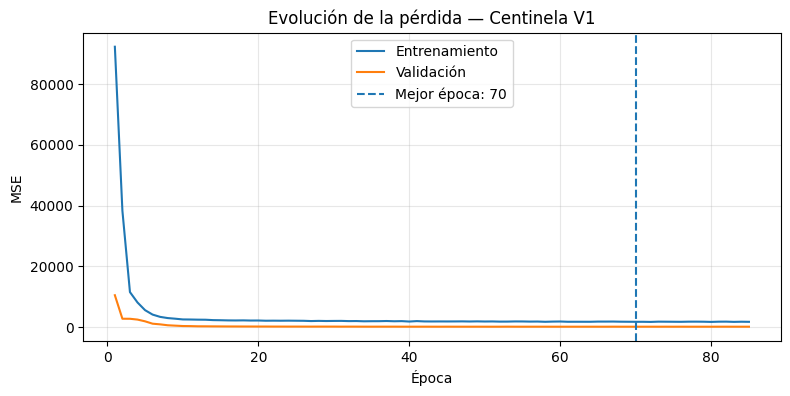

In [6]:
class CentinelaMLP(torch.nn.Module):
    def __init__(self, numero_entradas):
        super(CentinelaMLP, self).__init__()
        self.red = torch.nn.Sequential(
            torch.nn.Linear(numero_entradas, 64),
            torch.nn.ReLU(),
            torch.nn.Dropout(p=0.2),
            torch.nn.Linear(64, 32),
            torch.nn.ReLU(),
            torch.nn.Dropout(p=0.2),
            torch.nn.Linear(32, 1)
        )

    def forward(self, x):
        return self.red(x)


torch.manual_seed(semilla)
modelo = CentinelaMLP(X_train_tensor.shape[1])
print("Parámetros entrenables:",
      sum(p.numel() for p in modelo.parameters() if p.requires_grad))

historial_v1, mejor_epoca_v1 = entrenar_modelo(
    modelo, cargador_entrenamiento, cargador_validacion, nombre="Centinela V1"
)
graficar_perdidas(historial_v1, mejor_epoca_v1,
                  "Evolución de la pérdida — Centinela V1")

### 1.6 Centinela V2 — se añaden variables de tendencia
`tasa_cambio_12h_cm_h`, `tasa_cambio_24h_cm_h` y `aceleracion_tendencia_cm` (14 predictores).

Centinela V2: mejor época 106 (de 121), MSE validación 97.8618


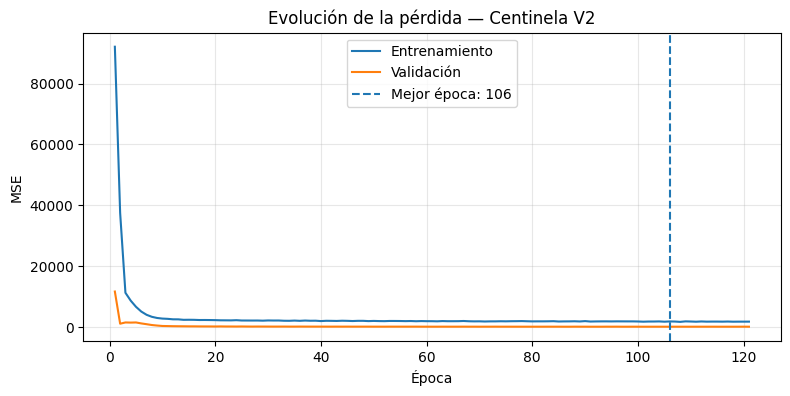

In [7]:
for conjunto in (conjunto_entrenamiento, conjunto_validacion,
                 conjunto_prueba):
    conjunto["tasa_cambio_12h_cm_h"] = conjunto["cambio_12h"] / 12
    conjunto["tasa_cambio_24h_cm_h"] = conjunto["cambio_24h"] / 24
    conjunto["aceleracion_tendencia_cm"] = (
        conjunto["cambio_12h"] - conjunto["cambio_24h"] / 2
    )

variables_predictoras_v2 = variables_predictoras + [
    "tasa_cambio_12h_cm_h", "tasa_cambio_24h_cm_h",
    "aceleracion_tendencia_cm"
]


class CentinelaMLPV2(torch.nn.Module):
    def __init__(self, numero_entradas):
        super(CentinelaMLPV2, self).__init__()
        self.red = torch.nn.Sequential(
            torch.nn.Linear(numero_entradas, 64),
            torch.nn.ReLU(),
            torch.nn.Dropout(p=0.2),
            torch.nn.Linear(64, 32),
            torch.nn.ReLU(),
            torch.nn.Dropout(p=0.2),
            torch.nn.Linear(32, 1)
        )

    def forward(self, x):
        return self.red(x)


(escalador_X_v2, X_train_tensor_v2, X_val_tensor_v2, X_test_tensor_v2,
 cargador_entrenamiento_v2, cargador_validacion_v2) = preparar_conjuntos(
    variables_predictoras_v2
)

torch.manual_seed(semilla)
modelo_v2 = CentinelaMLPV2(X_train_tensor_v2.shape[1])
historial_v2, mejor_epoca_v2 = entrenar_modelo(
    modelo_v2, cargador_entrenamiento_v2, cargador_validacion_v2,
    nombre="Centinela V2"
)
graficar_perdidas(historial_v2, mejor_epoca_v2,
                  "Evolución de la pérdida — Centinela V2")

### 1.7 Evaluación frente a la línea base de persistencia
Persistencia = «el nivel dentro de 12 h será el actual». La prueba se evalúa **una sola vez**, al final. Un aumento pronunciado es un cambio real mayor de 4 cm en 12 h.

  conjunto       modelo  MAE_cm  RMSE_cm  sesgo_cm
Validación Centinela V1  7.0755  10.1505   -0.3346
Validación Centinela V2  6.8965   9.8925    0.5364
Validación Persistencia  7.1285  10.2994   -0.1343
    Prueba Centinela V1 13.1466  19.1525   -5.8631
    Prueba Centinela V2 12.2615  18.1426   -4.2643
    Prueba Persistencia 13.1166  18.5747   -0.7500

AUMENTOS > 4 cm EN 12 h (PRUEBA) — 539 aumentos reales de 1724
      modelo  VP  FP  FN   VN  sensibilidad  precision
Centinela V1  45  41 494 1144         0.083      0.523
Centinela V2  25  20 514 1165         0.046      0.556
Persistencia   0   0 539 1185         0.000      0.000


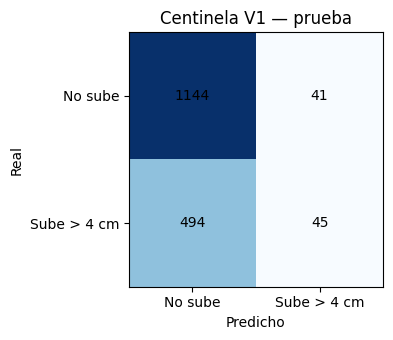

In [8]:
pred_v1 = {
    "Validación": predecir(modelo, X_val_tensor),
    "Prueba": predecir(modelo, X_test_tensor),
}
pred_v2 = {
    "Validación": predecir(modelo_v2, X_val_tensor_v2),
    "Prueba": predecir(modelo_v2, X_test_tensor_v2),
}
conjuntos_eval = {
    "Validación": conjunto_validacion,
    "Prueba": conjunto_prueba,
}

filas = []
for nombre_conjunto, datos in conjuntos_eval.items():
    real = datos[variable_objetivo].to_numpy()
    persistencia = datos["valorObservado"].to_numpy()
    for nombre_modelo, prediccion in [
        ("Centinela V1", pred_v1[nombre_conjunto]),
        ("Centinela V2", pred_v2[nombre_conjunto]),
        ("Persistencia", persistencia),
    ]:
        filas.append({
            "conjunto": nombre_conjunto, "modelo": nombre_modelo,
            **calcular_metricas(real, prediccion)
        })

metricas_fase_1 = pd.DataFrame(filas)
print(metricas_fase_1.round(4).to_string(index=False))

metricas_fase_1.to_csv(
    os.path.join(CARPETA_FASE_1, "centinela_metricas_fase_1.csv"),
    index=False, encoding="utf-8-sig"
)

# --- Detección de aumentos pronunciados (> 4 cm en 12 h), prueba -------
datos = conjunto_prueba
cambio_real = (datos[variable_objetivo] - datos["valorObservado"]).to_numpy()
aumento_real = cambio_real > 4

filas = []
for nombre_modelo, prediccion in [
    ("Centinela V1", pred_v1["Prueba"]),
    ("Centinela V2", pred_v2["Prueba"]),
    ("Persistencia", datos["valorObservado"].to_numpy()),
]:
    aumento_predicho = (prediccion - datos["valorObservado"].to_numpy()) > 4
    vp = int(np.sum(aumento_real & aumento_predicho))
    fp = int(np.sum(~aumento_real & aumento_predicho))
    fn = int(np.sum(aumento_real & ~aumento_predicho))
    vn = int(np.sum(~aumento_real & ~aumento_predicho))
    filas.append({
        "modelo": nombre_modelo, "VP": vp, "FP": fp, "FN": fn, "VN": vn,
        "sensibilidad": vp / (vp + fn) if (vp + fn) else 0.0,
        "precision": vp / (vp + fp) if (vp + fp) else 0.0,
    })
deteccion_aumentos = pd.DataFrame(filas)
print("\nAUMENTOS > 4 cm EN 12 h (PRUEBA) —",
      int(aumento_real.sum()), "aumentos reales de", len(aumento_real))
print(deteccion_aumentos.round(3).to_string(index=False))

# --- Matriz de confusión de Centinela V1 -------------------------------
matriz = deteccion_aumentos.iloc[0][["VN", "FP", "FN", "VP"]].astype(int)
fig, eje = plt.subplots(figsize=(4, 3.5))
eje.imshow([[matriz["VN"], matriz["FP"]], [matriz["FN"], matriz["VP"]]],
           cmap="Blues")
for i, fila_m in enumerate([[matriz["VN"], matriz["FP"]],
                            [matriz["FN"], matriz["VP"]]]):
    for j, valor in enumerate(fila_m):
        eje.text(j, i, int(valor), ha="center", va="center")
eje.set_xticks([0, 1]); eje.set_xticklabels(["No sube", "Sube > 4 cm"])
eje.set_yticks([0, 1]); eje.set_yticklabels(["No sube", "Sube > 4 cm"])
eje.set_xlabel("Predicho"); eje.set_ylabel("Real")
eje.set_title("Centinela V1 — prueba")
plt.tight_layout(); plt.show()

### 1.8 MLP binario: ¿sube más de 4 cm en 12 horas? (sí / no)
Planteamiento alternativo que pide la rúbrica de la Fase 1. Se compara con las reglas "nunca sube", "sube si ya subió" y "siempre sube". **Resultado:** el MLP binario obtiene F1 0.486 y AUC 0.653, apenas por encima de responder siempre "sube" (F1 0.476); detecta casi todos los aumentos (sensibilidad 0.90) a costa de muchos falsos positivos (precisión 0.33). **La formulación binaria no es adecuada para este problema**; la regresión original del nivel sigue como formulación principal.

Frecuencia de 'sube > 4 cm': entrenamiento 0.246 (1959/7975) | validación 0.228 (391/1712) | prueba 0.313 (539/1724)
pos_weight = 3.07
MLP binario: mejor época 7 (de 22), BCE validación 0.9608
Umbral elegido en validación: 0.35 (F1 validación 0.442)

PRUEBA — 539 aumentos > 4 cm de 1724 ejemplos
                            modelo  VP  FP  FN   VN  exactitud  precision  sensibilidad    F1   AUC
                       MLP binario 485 972  54  213      0.405      0.333         0.900 0.486 0.653
                 Regla: nunca sube   0   0 539 1185      0.687      0.000         0.000 0.000   NaN
Regla: sube si subió >4 cm en 12 h 242 308 297  877      0.649      0.440         0.449 0.444   NaN


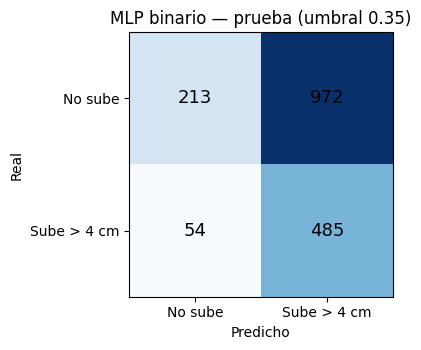

             modelo  VP   FP  FN  VN  exactitud  precision  sensibilidad    F1
Regla: siempre sube 539 1185   0   0      0.313      0.313           1.0 0.476


In [9]:
# ============================================================
# CELDA 1.8 — MLP BINARIO: ¿SUBE MÁS DE 4 cm EN 12 HORAS?  (sí / no)
# Reglas fijadas ANTES de ver resultados:
#   - Etiqueta: sube = (nivel a +12 h - nivel actual) > 4 cm.
#   - Salida de la red: UN número sin sigmoide (logit); pérdida BCEWithLogitsLoss con pos_weight.
#   - El umbral de decisión se elige SOLO con la validación (maximiza F1). La prueba se mira UNA vez.
#   - Se compara con dos reglas sin red: "nunca sube" y "sube si en las últimas 12 h subió más de 4 cm".
# Requiere las celdas hasta la 1.6 (usa X_*_tensor_v2, conjunto_*, dispositivo, semilla).
# ============================================================
from sklearn.metrics import roc_auc_score

UMBRAL_CM = 4.0

def etiqueta_sube(df):
    return ((df[variable_objetivo] - df["valorObservado"]) > UMBRAL_CM).astype("float32").to_numpy()

yb_ent, yb_val, yb_pru = (etiqueta_sube(c) for c in (conjunto_entrenamiento, conjunto_validacion, conjunto_prueba))
print("Frecuencia de 'sube > 4 cm':",
      f"entrenamiento {yb_ent.mean():.3f} ({int(yb_ent.sum())}/{len(yb_ent)}) |",
      f"validación {yb_val.mean():.3f} ({int(yb_val.sum())}/{len(yb_val)}) |",
      f"prueba {yb_pru.mean():.3f} ({int(yb_pru.sum())}/{len(yb_pru)})")
if yb_ent.sum() == 0 or yb_val.sum() == 0:
    raise RuntimeError("No hay aumentos > 4 cm en entrenamiento o validación; no se puede entrenar/elegir umbral.")

t32 = lambda a: torch.tensor(np.asarray(a), dtype=torch.float32).reshape(-1, 1)
Yb_ent, Yb_val = t32(yb_ent), t32(yb_val)

generador_b = torch.Generator()
generador_b.manual_seed(semilla)
cargador_b_ent = DataLoader(TensorDataset(X_train_tensor_v2, Yb_ent), batch_size=tamano_lote,
                            shuffle=True, generator=generador_b)
cargador_b_val = DataLoader(TensorDataset(X_val_tensor_v2, Yb_val), batch_size=tamano_lote, shuffle=False)


class CentinelaMLPBinario(torch.nn.Module):
    def __init__(self, numero_entradas):
        super(CentinelaMLPBinario, self).__init__()
        self.red = torch.nn.Sequential(
            torch.nn.Linear(numero_entradas, 64), torch.nn.ReLU(), torch.nn.Dropout(p=0.2),
            torch.nn.Linear(64, 32), torch.nn.ReLU(), torch.nn.Dropout(p=0.2),
            torch.nn.Linear(32, 1)          # logit: sin sigmoide aquí
        )

    def forward(self, x):
        return self.red(x)


# pos_weight = (no sube) / (sube) en ENTRENAMIENTO: compensa que los aumentos son pocos.
peso_positivo = float((1 - yb_ent).sum() / yb_ent.sum())
perdida_bce = torch.nn.BCEWithLogitsLoss(pos_weight=torch.tensor([peso_positivo], device=dispositivo))
print(f"pos_weight = {peso_positivo:.2f}")

torch.manual_seed(semilla)
modelo_b = CentinelaMLPBinario(X_train_tensor_v2.shape[1]).to(dispositivo)
optimizador_b = torch.optim.Adam(modelo_b.parameters(), lr=0.001, weight_decay=0.0001)


def pasada_b(cargador, entrenar):
    modelo_b.train(entrenar)
    suma, total = 0.0, 0
    for x, y in cargador:
        x, y = x.to(dispositivo), y.to(dispositivo)
        with torch.set_grad_enabled(entrenar):
            perdida = perdida_bce(modelo_b(x), y)
            if entrenar:
                optimizador_b.zero_grad(); perdida.backward(); optimizador_b.step()
        suma += perdida.item() * y.size(0); total += y.size(0)
    return suma / total


mejor_b, mejor_estado_b, mejor_epoca_b, sin_mejora_b, hist_b = float("inf"), None, 0, 0, []
for epoca in range(1, 151):
    l_ent, l_val = pasada_b(cargador_b_ent, True), pasada_b(cargador_b_val, False)
    hist_b.append({"epoca": epoca, "bce_entrenamiento": l_ent, "bce_validacion": l_val})
    if l_val < mejor_b:
        mejor_b, mejor_estado_b, mejor_epoca_b, sin_mejora_b = l_val, copy.deepcopy(modelo_b.state_dict()), epoca, 0
    else:
        sin_mejora_b += 1
        if sin_mejora_b >= 15:
            break
modelo_b.load_state_dict(mejor_estado_b); modelo_b.eval()
print(f"MLP binario: mejor época {mejor_epoca_b} (de {len(hist_b)}), BCE validación {mejor_b:.4f}")


def probabilidades(X):
    with torch.no_grad():
        return torch.sigmoid(modelo_b(X.to(dispositivo))).cpu().numpy().flatten()


def metricas_binarias(real, predicho):
    real, predicho = np.asarray(real).astype(bool), np.asarray(predicho).astype(bool)
    vp = int((real & predicho).sum()); fp = int((~real & predicho).sum())
    fn = int((real & ~predicho).sum()); vn = int((~real & ~predicho).sum())
    precision = vp / (vp + fp) if (vp + fp) else 0.0
    sensibilidad = vp / (vp + fn) if (vp + fn) else 0.0
    f1 = 2 * precision * sensibilidad / (precision + sensibilidad) if (precision + sensibilidad) else 0.0
    return {"VP": vp, "FP": fp, "FN": fn, "VN": vn, "exactitud": (vp + vn) / len(real),
            "precision": precision, "sensibilidad": sensibilidad, "F1": f1}


# --- Umbral elegido SOLO con validación (rejilla fija 0.05 ... 0.95) ---------
p_val, p_pru = probabilidades(X_val_tensor_v2), probabilidades(X_test_tensor_v2)
rejilla = np.round(np.arange(0.05, 0.96, 0.05), 2)
f1_por_umbral = [metricas_binarias(yb_val, p_val >= u)["F1"] for u in rejilla]
umbral = float(rejilla[int(np.argmax(f1_por_umbral))])
print(f"Umbral elegido en validación: {umbral:.2f} (F1 validación {max(f1_por_umbral):.3f})")

# --- Prueba: UNA sola vez ------------------------------------------------------
filas = []
reglas = {
    "MLP binario": p_pru >= umbral,
    "Regla: nunca sube": np.zeros(len(yb_pru), dtype=bool),
    "Regla: sube si subió >4 cm en 12 h": (conjunto_prueba["cambio_12h"].to_numpy() > UMBRAL_CM),
}
for nombre, pred in reglas.items():
    m = metricas_binarias(yb_pru, pred)
    if nombre == "MLP binario":
        m["AUC"] = float(roc_auc_score(yb_pru, p_pru)) if 0 < yb_pru.sum() < len(yb_pru) else np.nan
    else:
        m["AUC"] = np.nan
    filas.append({"modelo": nombre, **m})
tabla_binaria = pd.DataFrame(filas)
print(f"\nPRUEBA — {int(yb_pru.sum())} aumentos > 4 cm de {len(yb_pru)} ejemplos")
print(tabla_binaria.round(3).to_string(index=False))
tabla_binaria.to_csv(os.path.join(CARPETA_FASE_1, "centinela_mlp_binario_prueba.csv"),
                     index=False, encoding="utf-8-sig")

# --- Matriz de confusión del MLP binario ----------------------------------------
m = tabla_binaria.iloc[0]
cm = [[int(m["VN"]), int(m["FP"])], [int(m["FN"]), int(m["VP"])]]
fig, eje = plt.subplots(figsize=(4.2, 3.6))
eje.imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        eje.text(j, i, cm[i][j], ha="center", va="center", fontsize=13)
eje.set_xticks([0, 1]); eje.set_xticklabels(["No sube", "Sube > 4 cm"])
eje.set_yticks([0, 1]); eje.set_yticklabels(["No sube", "Sube > 4 cm"])
eje.set_xlabel("Predicho"); eje.set_ylabel("Real")
eje.set_title(f"MLP binario — prueba (umbral {umbral:.2f})")
plt.tight_layout(); plt.show()

m_s = metricas_binarias(yb_pru, np.ones(len(yb_pru), dtype=bool))
print(pd.DataFrame([{"modelo": "Regla: siempre sube", **m_s}]).round(3).to_string(index=False))

### 1.9 Experimento de regularización (sobreajuste a propósito)
Cuatro configuraciones del MLP: A sin regularización, B Dropout 0.3, C L2 (1e-3) y D Dropout + L2 + parada temprana. El MSE de entrenamiento se recalcula con Dropout apagado y con los pesos de la mejor época para que la brecha entre validación y entrenamiento sea comparable.

**Resultado (una semilla; el entrenamiento en CPU no es totalmente reproducible).** Sin regularización (A) y con L2 solo (C) la validación alcanza su mínimo en la época 9 a 10 (MSE ≈ 116) y después empeora hasta ≈ 300: sobreajuste clásico. Con Dropout 0.3 (B) el mínimo es el mejor de las cuatro (MSE 99.3, un 14 % menos que A) y la validación casi no se degrada (119 en la última época); Dropout + L2 + parada temprana (D) se detiene en la época 29 con MSE 109.2. **Dropout es lo que controla el sobreajuste; L2 solo no ayuda.** La columna de brecha sale menor que 1 porque, con los pesos de la mejor época, el MSE de entrenamiento es mayor que el de validación (el periodo de entrenamiento contiene crecidas más fuertes y en A y C la red aún está poco ajustada en esa época); por eso el sobreajuste se lee mejor comparando la validación de la mejor época con la de la última y con las curvas.

                    configuración  épocas entrenadas  mejor época (validación)  MSE valid. (última época)  MSE valid. (mejor época)  MSE entren. (mejor época, sin Dropout)  brecha valid./entren. (mejor época)
            A) Sin regularización                300                        10                    303.303                   115.529                                 302.196                                0.382
                   B) Dropout 0.3                300                       293                    119.185                    99.267                                 290.732                                0.341
                     C) L2 (1e-3)                300                         9                    290.119                   115.919                                 315.851                                0.367
D) Dropout + L2 + parada temprana                 29                        14                    121.538                   109.238                                 

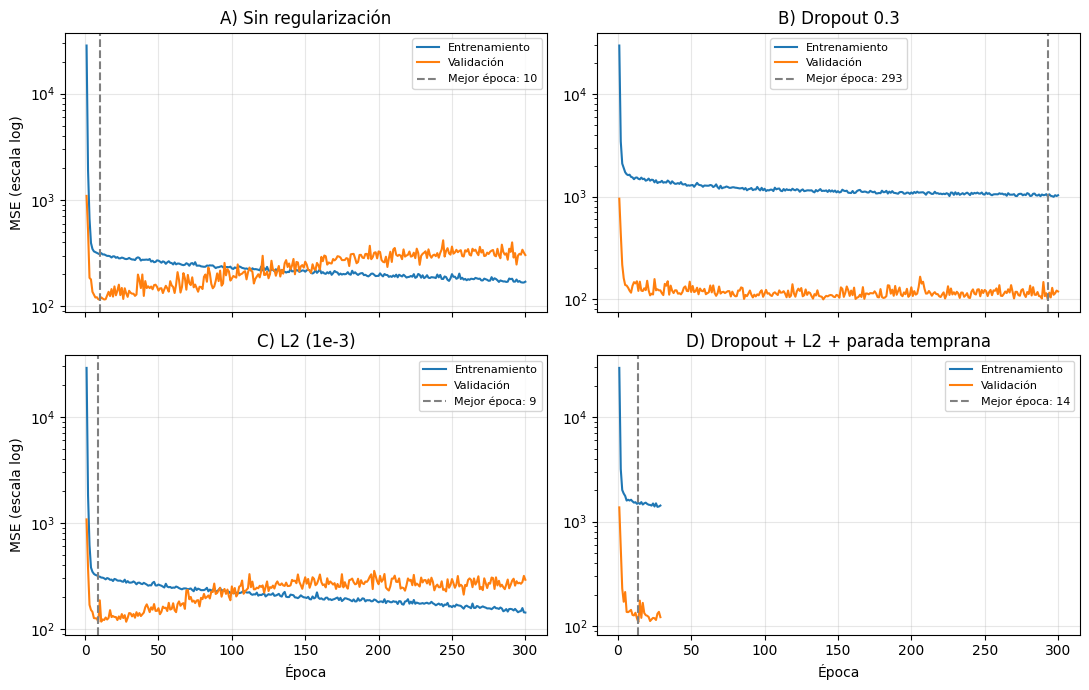

In [10]:
# ============================================================
# CELDA 1.9 — EXPERIMENTO DE REGULARIZACIÓN (sobreajuste a propósito)
# Misma tarea de la Fase 1 (regresión a +12 h, 14 predictores). Cuatro configuraciones, semilla fija:
#   A) Red grande, sin Dropout ni L2, 300 épocas, SIN parada temprana  -> debe sobreajustar
#   B) A + Dropout 0.3
#   C) A + L2 (weight_decay 1e-3)
#   D) A + Dropout 0.3 + L2 1e-3 + parada temprana (paciencia 15)
# Se compara con entrenamiento y VALIDACIÓN. La prueba NO se usa aquí.
# Requiere las celdas hasta la 1.6 (usa entrenar_modelo y los cargadores de V2).
# ============================================================

def construir_mlp(numero_entradas, ocultas=(256, 256, 128), dropout=0.0):
    capas, previo = [], numero_entradas
    for n in ocultas:
        capas += [torch.nn.Linear(previo, n), torch.nn.ReLU()]
        if dropout > 0:
            capas.append(torch.nn.Dropout(p=dropout))
        previo = n
    capas.append(torch.nn.Linear(previo, 1))
    return torch.nn.Sequential(*capas)


configuraciones = [
    ("A) Sin regularización",          dict(dropout=0.0, l2=0.0,   paciencia=10**9, epocas=300)),
    ("B) Dropout 0.3",                 dict(dropout=0.3, l2=0.0,   paciencia=10**9, epocas=300)),
    ("C) L2 (1e-3)",                   dict(dropout=0.0, l2=1e-3,  paciencia=10**9, epocas=300)),
    ("D) Dropout + L2 + parada temprana", dict(dropout=0.3, l2=1e-3, paciencia=15, epocas=300)),
]

resultados_reg, historiales_reg = [], {}
for nombre, c in configuraciones:
    torch.manual_seed(semilla)
    red = construir_mlp(X_train_tensor_v2.shape[1], dropout=c["dropout"])
    hist, mejor_ep = entrenar_modelo(
        red, cargador_entrenamiento_v2, cargador_validacion_v2,
        regularizacion=c["l2"], maximo_epocas=c["epocas"], paciencia=c["paciencia"],
        nombre=nombre, silencioso=True
    )
    historiales_reg[nombre] = (hist, mejor_ep)
    ultima = hist.iloc[-1]
    # El MSE de entrenamiento del historial se mide con Dropout ACTIVO; para comparar bien se
    # recalcula en modo evaluación (Dropout apagado) con los pesos de la mejor época.
    mse_ent_eval = float(np.mean((predecir(red, X_train_tensor_v2) - y_entrenamiento.to_numpy()) ** 2))
    mse_val_mejor = float(hist["mse_validacion"].min())
    resultados_reg.append({
        "configuración": nombre,
        "épocas entrenadas": len(hist),
        "mejor época (validación)": mejor_ep,
        "MSE valid. (última época)": ultima["mse_validacion"],
        "MSE valid. (mejor época)": mse_val_mejor,
        "MSE entren. (mejor época, sin Dropout)": mse_ent_eval,
        "brecha valid./entren. (mejor época)": mse_val_mejor / max(mse_ent_eval, 1e-9),
    })

tabla_reg = pd.DataFrame(resultados_reg)
print(tabla_reg.round(3).to_string(index=False))
tabla_reg.to_csv(os.path.join(CARPETA_FASE_1, "centinela_regularizacion.csv"),
                 index=False, encoding="utf-8-sig")

fig, ejes = plt.subplots(2, 2, figsize=(11, 7), sharex=True)
for eje, (nombre, (hist, mejor_ep)) in zip(ejes.ravel(), historiales_reg.items()):
    eje.plot(hist["epoca"], hist["mse_entrenamiento"], label="Entrenamiento")
    eje.plot(hist["epoca"], hist["mse_validacion"], label="Validación")
    eje.axvline(mejor_ep, linestyle="--", color="gray", label=f"Mejor época: {mejor_ep}")
    eje.set_title(nombre); eje.set_yscale("log"); eje.grid(alpha=0.3); eje.legend(fontsize=8)
for eje in ejes[1]:
    eje.set_xlabel("Época")
for eje in ejes[:, 0]:
    eje.set_ylabel("MSE (escala log)")
plt.tight_layout(); plt.show()

**Lectura de la Fase 1.** Los modelos temporales V1/V2 son la **línea base**. Su resultado muestra qué tanto aporta el historial del propio nivel; no demuestra capacidad de alerta de inundación. La Fase 2 incorpora información espacial de Sentinel-1 para comprobar si una arquitectura multimodal mejora esa línea base.

---
# FASE 2 — Sentinel-1 y modelo multimodal
Flujo: **catálogo** → **cruce con IDEAM** → **COG en S3** → **funciones de procesamiento** → **malla de referencia y distancia al cauce (HydroRIVERS)** → **procesamiento por lotes (reanudable)** → **modelo multimodal**.

### 2.1 Catálogo Sentinel-1 (Copernicus Data Space, OData)
IW GRDH 1S sobre el área de estudio, 2017-2025. Se conservan las órbitas relativas **142 DESCENDING** (paso de ≈05:51 h local) y **48 ASCENDING** (≈18:22 h local) con doble polarización (VV&VH), y se elimina la duplicidad de productos para una misma adquisición (se prefiere el producto en línea y de mayor tamaño). La órbita 142 aporta la gran mayoría de las escenas.

In [11]:
import requests

URL = "https://catalogue.dataspace.copernicus.eu/odata/v1/Products"

def consultar_anio(anio):
    filtro = (
        "Collection/Name eq 'SENTINEL-1' "
        "and Attributes/OData.CSC.StringAttribute/"
        "any(att:att/Name eq 'productType' "
        "and att/OData.CSC.StringAttribute/Value eq 'IW_GRDH_1S') "
        f"and ContentDate/Start ge {anio}-01-01T00:00:00.000Z "
        f"and ContentDate/Start lt {anio + 1}-01-01T00:00:00.000Z "
        "and OData.CSC.Intersects(area=geography'"
        f"SRID=4326;POLYGON(({poligono}))')"
    )
    productos, salto = [], 0
    while True:
        respuesta = requests.get(
            URL,
            params={
                "$filter": filtro, "$top": 1000, "$skip": salto,
                "$orderby": "ContentDate/Start asc",
                "$expand": "Attributes",
            },
            timeout=180
        )
        respuesta.raise_for_status()
        pagina = respuesta.json().get("value", [])
        productos.extend(pagina)
        if len(pagina) < 1000:
            return productos
        salto += 1000


registros = []
for anio in range(2017, 2026):
    productos_anio = consultar_anio(anio)
    print(f"Año {anio}: {len(productos_anio)} productos")
    for producto in productos_anio:
        atributos = {
            a["Name"]: a.get("Value")
            for a in producto.get("Attributes", [])
        }
        registros.append({
            "Id": producto["Id"],
            "Name": producto["Name"],
            "ContentDate.Start": producto["ContentDate"]["Start"],
            "ContentLength": producto.get("ContentLength"),
            "Online": producto.get("Online"),
            "orbitNumber": atributos.get("orbitNumber"),
            "relativeOrbitNumber": atributos.get("relativeOrbitNumber"),
            "orbitDirection": atributos.get("orbitDirection"),
            "polarisationChannels": atributos.get("polarisationChannels"),
            "platformSerialIdentifier": atributos.get("platformSerialIdentifier"),
        })

df = pd.DataFrame(registros)
df["ContentDate.Start"] = pd.to_datetime(
    df["ContentDate.Start"], errors="coerce", utc=True
)
df["relativeOrbitNumber"] = pd.to_numeric(
    df["relativeOrbitNumber"], errors="coerce"
)
df["ContentLength"] = pd.to_numeric(df["ContentLength"], errors="coerce")

df_orbita = df[
    (
        ((df["relativeOrbitNumber"] == 142) & (df["orbitDirection"] == "DESCENDING"))
        | ((df["relativeOrbitNumber"] == 48) & (df["orbitDirection"] == "ASCENDING"))
    )
    & (df["polarisationChannels"] == "VV&VH")
].copy()

df_productos_seleccionados = (
    df_orbita
    .sort_values(by=["Online", "ContentLength"], ascending=[False, False])
    .drop_duplicates(
        subset=["ContentDate.Start", "platformSerialIdentifier", "orbitNumber"],
        keep="first"
    )
    .sort_values("ContentDate.Start")
    .reset_index(drop=True)
)

print("\nProductos consultados:", len(df))
print("Adquisiciones órbita 142 DESCENDING VV&VH:",
      len(df_productos_seleccionados))
df_productos_seleccionados.to_csv(
    os.path.join(CARPETA_FASE_2, "centinela_inventario_adquisiciones_seleccionadas.csv"),
    index=False, encoding="utf-8-sig"
)

Año 2017: 76 productos
Año 2018: 76 productos
Año 2019: 77 productos
Año 2020: 83 productos
Año 2021: 73 productos
Año 2022: 30 productos
Año 2023: 31 productos
Año 2024: 31 productos
Año 2025: 68 productos

Productos consultados: 545
Adquisiciones órbita 142 DESCENDING VV&VH: 530


### 2.2 Cruce de cada adquisición con el último nivel IDEAM definitivo
Hora de Colombia (America/Bogota). Para cada imagen se toma la **última observación anterior** (`direction="backward"`, tolerancia 12 h). Esa observación es el ancla temporal del modelo multimodal.

In [ ]:
imagenes_finales = df_productos_seleccionados.copy()
imagenes_finales["datetime_utc"] = pd.to_datetime(
    imagenes_finales["ContentDate.Start"], utc=True, errors="coerce"
)
imagenes_finales["datetime_colombia"] = (
    imagenes_finales["datetime_utc"]
    .dt.tz_convert("America/Bogota")
    .dt.tz_localize(None)
)
imagenes_finales = imagenes_finales[
    imagenes_finales["datetime_colombia"].dt.year.between(2020, 2025)
][["Id", "Name", "datetime_colombia"]].sort_values("datetime_colombia")

niveles_finales = df_nivel_definitivo[
    ["fechaObservacion", "valorObservado"]
].rename(columns={
    "fechaObservacion": "fecha_hora_ideam",
    "valorObservado": "nivel_cm"
}).sort_values("fecha_hora_ideam")

imagenes_finales["datetime_colombia"] = imagenes_finales["datetime_colombia"].astype("datetime64[ns]")
niveles_finales["fecha_hora_ideam"] = niveles_finales["fecha_hora_ideam"].astype("datetime64[ns]")

cruce_anterior = pd.merge_asof(
    imagenes_finales,
    niveles_finales,
    left_on="datetime_colombia",
    right_on="fecha_hora_ideam",
    direction="backward",
    tolerance=pd.Timedelta("12 hours")
)
cruce_anterior["antiguedad_medicion_minutos"] = (
    cruce_anterior["datetime_colombia"] - cruce_anterior["fecha_hora_ideam"]
).dt.total_seconds() / 60

print("Imágenes 2020-2025:", len(cruce_anterior))
print("Con observación IDEAM definitiva previa (<= 12 h):",
      int(cruce_anterior["nivel_cm"].notna().sum()))

cruce_anterior = cruce_anterior[
    cruce_anterior["nivel_cm"].notna()
].reset_index(drop=True)

### 2.2b Diagnóstico: ¿qué órbitas de Sentinel-1 cubren el área?
Solo consulta el catálogo; sirve para justificar el uso de las órbitas 142 y 48.

In [12]:
# ============================================================
# CELDA B — ¿QUÉ ÓRBITAS DE SENTINEL-1 CUBREN EL ÁREA? (solo consulta el catálogo; no descarga nada)
# Cuenta, por órbita relativa y dirección, las escenas 2020-2025 (el IDEAM solo tiene nivel
# DEFINITIVO desde 2020), con doble polarización y cobertura completa del área de estudio.
# Ejecutar en el cuaderno de las Fases 1 y 2, después de la 2.2 (usa poligono, LON_*, LAT_*,
# serie_modelado, CARPETA_FASE_2). Requiere las claves? No: el catálogo OData es público.
# ============================================================
import requests
from shapely.geometry import box, shape

URL_CATALOGO = "https://catalogue.dataspace.copernicus.eu/odata/v1/Products"
area_estudio = box(LON_MIN, LAT_MIN, LON_MAX, LAT_MAX)

def consultar_anio_todas(anio):
    filtro = (
        "Collection/Name eq 'SENTINEL-1' "
        "and Attributes/OData.CSC.StringAttribute/"
        "any(att:att/Name eq 'productType' "
        "and att/OData.CSC.StringAttribute/Value eq 'IW_GRDH_1S') "
        f"and ContentDate/Start ge {anio}-01-01T00:00:00.000Z "
        f"and ContentDate/Start lt {anio + 1}-01-01T00:00:00.000Z "
        "and OData.CSC.Intersects(area=geography'"
        f"SRID=4326;POLYGON(({poligono}))')"
    )
    productos, salto = [], 0
    while True:
        r = requests.get(URL_CATALOGO, params={
            "$filter": filtro, "$top": 1000, "$skip": salto,
            "$orderby": "ContentDate/Start asc", "$expand": "Attributes"}, timeout=180)
        r.raise_for_status()
        pagina = r.json().get("value", [])
        productos.extend(pagina)
        if len(pagina) < 1000:
            return productos
        salto += 1000

registros = []
for anio in range(2020, 2026):
    for p in consultar_anio_todas(anio):
        atr = {a["Name"]: a.get("Value") for a in p.get("Attributes", [])}
        try:
            cobertura = area_estudio.intersection(shape(p["GeoFootprint"])).area / area_estudio.area
        except Exception:
            cobertura = np.nan
        registros.append({
            "Name": p["Name"], "inicio_utc": p["ContentDate"]["Start"],
            "orbita_relativa": pd.to_numeric(atr.get("relativeOrbitNumber"), errors="coerce"),
            "direccion": atr.get("orbitDirection"), "polarizacion": atr.get("polarisationChannels"),
            "plataforma": atr.get("platformSerialIdentifier"), "cobertura_area": cobertura,
        })
    print(f"Año {anio}: consultado")

cat = pd.DataFrame(registros)
cat["inicio_utc"] = pd.to_datetime(cat["inicio_utc"], errors="coerce", utc=True)
cat = cat[(cat["polarizacion"] == "VV&VH") & (cat["cobertura_area"] >= 0.99)].copy()
cat["fecha_colombia"] = (cat["inicio_utc"] - pd.Timedelta(hours=5)).dt.tz_localize(None).astype("datetime64[ns]")
cat = cat.drop_duplicates(subset=["orbita_relativa", "direccion", "fecha_colombia"])

# ¿Cuántas tienen una observación DEFINITIVA del IDEAM en las 12 h anteriores?
serie_ref = serie_modelado[["fechaObservacion"]].copy()
serie_ref["fechaObservacion"] = serie_ref["fechaObservacion"].astype("datetime64[ns]")
serie_ref = serie_ref.sort_values("fechaObservacion")
con_ancla = pd.merge_asof(
    cat.sort_values("fecha_colombia"), serie_ref, left_on="fecha_colombia",
    right_on="fechaObservacion", direction="backward", tolerance=pd.Timedelta("12 hours"))
cat = con_ancla[con_ancla["fechaObservacion"].notna()].copy()

resumen_orbitas = (cat.groupby(["orbita_relativa", "direccion"])
                   .agg(escenas=("Name", "count"), primera=("fecha_colombia", "min"),
                        ultima=("fecha_colombia", "max"),
                        plataformas=("plataforma", lambda s: ",".join(sorted(set(s.dropna())))))
                   .reset_index().sort_values("escenas", ascending=False))
resumen_orbitas["primera"] = resumen_orbitas["primera"].dt.date
resumen_orbitas["ultima"] = resumen_orbitas["ultima"].dt.date
print("\nEscenas 2020-2025 con doble polarización, cobertura completa y nivel IDEAM definitivo previo (<= 12 h):")
print(resumen_orbitas.to_string(index=False))
print("\nTotal de escenas entre todas las órbitas:", len(cat))
cat.to_csv(os.path.join(CARPETA_FASE_2, "centinela_catalogo_todas_las_orbitas.csv"),
           index=False, encoding="utf-8-sig")

Año 2020: consultado
Año 2021: consultado
Año 2022: consultado
Año 2023: consultado
Año 2024: consultado
Año 2025: consultado

Escenas 2020-2025 con doble polarización, cobertura completa y nivel IDEAM definitivo previo (<= 12 h):
 orbita_relativa  direccion  escenas    primera     ultima plataformas
             142 DESCENDING      250 2020-01-05 2025-12-28       A,B,C
              48  ASCENDING       66 2020-01-04 2025-12-03       A,B,C

Total de escenas entre todas las órbitas: 316


### 2.3 Acceso a los COG de Copernicus S3
`s3fs` contra `https://eodata.dataspace.copernicus.eu`. Los productos COG están en `eodata/Sentinel-1/SAR/IW_GRDH_1S-COG/AAAA/MM/DD/..._COG.SAFE`; el nombre del COG termina con un sufijo distinto al del producto del catálogo, por eso se localiza por la **clave técnica** (plataforma, fechas, órbita y datatake) listando la carpeta del día.

In [13]:
import s3fs
import rasterio

sistema_archivos = s3fs.S3FileSystem(
    key=ACCESS_KEY,
    secret=SECRET_KEY,
    client_kwargs={
        "endpoint_url": "https://eodata.dataspace.copernicus.eu",
        "region_name": "default"
    }
)

patron_clave = re.compile(
    r"(?P<clave>S1[AB]_IW_GRDH_1SDV_"
    r"(?P<fecha>\d{8}T\d{6}_\d{8}T\d{6}_\d{6}_\w{6}))"
)
prefijo_cog = "eodata/Sentinel-1/SAR/IW_GRDH_1S-COG"

adquisiciones = cruce_anterior[["Id", "Name"]].copy()
adquisiciones["clave_tecnica"] = adquisiciones["Name"].apply(
    lambda x: patron_clave.search(str(x)).group("clave")
    if patron_clave.search(str(x)) else None
)
adquisiciones["fecha_carpeta"] = adquisiciones["Name"].apply(
    lambda x: patron_clave.search(str(x)).group("fecha")[:8]
    if patron_clave.search(str(x)) else None
)

catalogo_dias = {}
errores_consulta = []
for fecha in sorted(adquisiciones["fecha_carpeta"].dropna().unique()):
    ruta_dia = f"{prefijo_cog}/{fecha[:4]}/{fecha[4:6]}/{fecha[6:8]}"
    try:
        elementos = sistema_archivos.ls(ruta_dia, detail=False)
        catalogo_dias[fecha] = [
            e.get("name", "") if isinstance(e, dict) else str(e)
            for e in elementos
        ]
    except Exception as error:
        catalogo_dias[fecha] = []
        errores_consulta.append({"fecha": fecha, "error": str(error)[:200]})

resultados = []
for _, fila in adquisiciones.iterrows():
    clave, fecha = fila["clave_tecnica"], fila["fecha_carpeta"]
    candidatos = []
    if pd.notna(clave) and pd.notna(fecha):
        candidatos = [
            ruta for ruta in catalogo_dias.get(fecha, [])
            if clave in ruta and ruta.endswith(".SAFE")
        ]
    resultados.append({
        "Id": fila["Id"], "Name": fila["Name"], "clave_tecnica": clave,
        "ruta_cog": candidatos[0] if len(candidatos) == 1 else None,
        "numero_candidatos": len(candidatos),
        "estado": (
            "COG localizado" if len(candidatos) == 1
            else "Sin coincidencia" if len(candidatos) == 0
            else "Múltiples candidatos"
        )
    })

df_catalogo_cog_por_adquisicion = pd.DataFrame(resultados)
print(df_catalogo_cog_por_adquisicion["estado"].value_counts().to_string())
print("Errores de consulta S3:", len(errores_consulta))

if (df_catalogo_cog_por_adquisicion["estado"] == "COG localizado").sum() == 0:
    raise RuntimeError(
        "No se localizó ningún COG. Revise las credenciales de S3 "
        "(" + (errores_consulta[0]["error"] if errores_consulta else "sin detalle") + ")."
    )

# --- Cola de procesamiento: rutas VV y VH de cada COG ------------------
cola = df_catalogo_cog_por_adquisicion[
    df_catalogo_cog_por_adquisicion["estado"] == "COG localizado"
].copy()

inventario_mediciones = []
for _, fila in cola.iterrows():
    raiz = fila["ruta_cog"]
    try:
        elementos = sistema_archivos.ls(f"{raiz}/measurement", detail=False)
        tiff = [str(x) for x in elementos
                if str(x).lower().endswith((".tif", ".tiff"))]
        vv = [x for x in tiff if "vv" in x.lower()]
        vh = [x for x in tiff if "vh" in x.lower()]
        inventario_mediciones.append({
            "Id": fila["Id"], "Name": fila["Name"],
            "fecha": fila["Name"][17:25], "ruta_cog": raiz,
            "ruta_vv": vv[0] if len(vv) == 1 else None,
            "ruta_vh": vh[0] if len(vh) == 1 else None,
            "numero_tiff": len(tiff),
            "estado_medicion": (
                "VV y VH disponibles" if len(vv) == 1 and len(vh) == 1
                else "Revisar archivos de medición"
            )
        })
    except Exception as error:
        inventario_mediciones.append({
            "Id": fila["Id"], "Name": fila["Name"],
            "fecha": fila["Name"][17:25], "ruta_cog": raiz,
            "ruta_vv": None, "ruta_vh": None, "numero_tiff": 0,
            "estado_medicion": f"Error: {str(error)[:150]}"
        })

df_cola_sar = pd.DataFrame(inventario_mediciones)
df_cola_sar = df_cola_sar[
    df_cola_sar["estado_medicion"] == "VV y VH disponibles"
].reset_index(drop=True)

print("\nCola de procesamiento (VV y VH disponibles):", len(df_cola_sar))
df_cola_sar.to_csv(
    os.path.join(CARPETA_FASE_2, "cola_procesamiento_sentinel1.csv"),
    index=False, encoding="utf-8-sig"
)

estado
COG localizado          276
Sin coincidencia         37
Múltiples candidatos      3
Errores de consulta S3: 0

Cola de procesamiento (VV y VH disponibles): 276


### 2.4 Funciones de procesamiento SAR (las del proyecto, ya validadas)
Se reutilizan sin cambios: lectura de XML en S3, tabla de calibración Sigma0, ruido térmico por ventana (**versión parametrizada** `construir_ruido_ventana(banda, dn, ruta_cog, fila_inicial, columna_inicial)`), localización de la ventana por GCP y extracción de variables espaciales.

In [ ]:
from rasterio.windows import Window
from rasterio.transform import GCPTransformer, from_origin
from rasterio.control import GroundControlPoint
from rasterio.warp import reproject, Resampling


MARGEN_PIXELES = 100


def leer_xml_s3(ruta):
    with sistema_archivos.open(ruta, "rb") as archivo:
        return ET.parse(archivo).getroot()

def cargar_lut_sigma(ruta_xml):

    with sistema_archivos.open(ruta_xml, "rb") as archivo:
        raiz = ET.parse(archivo).getroot()

    vectores = [
        e for e in raiz.iter()
        if e.tag.split("}")[-1] == "calibrationVector"
    ]

    if not vectores:
        raise ValueError("No se encontraron vectores de calibración.")

    lineas = []
    pixeles_referencia = None
    lut_sigma = []

    for vector in vectores:

        linea = int(vector.find("line").text)

        pixeles = np.array(
            list(map(int, vector.find("pixel").text.split())),
            dtype=np.float64
        )

        sigma = np.array(
            list(map(float, vector.find("sigmaNought").text.split())),
            dtype=np.float64
        )

        if len(pixeles) != len(sigma):
            raise ValueError(
                "Longitudes incompatibles en LUT sigmaNought."
            )

        if pixeles_referencia is None:
            pixeles_referencia = pixeles
        elif not np.array_equal(pixeles_referencia, pixeles):
            raise ValueError(
                "Los vectores no comparten las mismas coordenadas."
            )

        lineas.append(linea)
        lut_sigma.append(sigma)

    orden = np.argsort(lineas)

    lineas = np.array(lineas, dtype=np.float64)[orden]
    lut_sigma = np.array(lut_sigma, dtype=np.float64)[orden]

    if len(np.unique(lineas)) != len(lineas):
        raise ValueError("Hay coordenadas de línea duplicadas.")

    return lineas, pixeles_referencia, lut_sigma

def obtener_hijo(elemento, nombre):
    for hijo in elemento:
        if hijo.tag.split("}")[-1] == nombre:
            return hijo
    return None

def obtener_texto(elemento, nombre):
    hijo = obtener_hijo(elemento, nombre)

    if hijo is None or hijo.text is None:
        raise ValueError(
            f"No se encontró el elemento XML directo: {nombre}"
        )

    return hijo.text.strip()

def obtener_texto_descendiente(elemento, nombre):
    for hijo in elemento.iter():
        if hijo.tag.split("}")[-1] == nombre:
            if hijo.text is not None:
                return hijo.text.strip()

    raise ValueError(
        f"No se encontró el elemento XML: {nombre}"
    )

def obtener_vector(elemento, nombre):
    texto = obtener_texto(elemento, nombre)

    return np.fromstring(
        texto,
        sep=" ",
        dtype=np.float64
    )

def convertir_tiempo(texto):
    return datetime.fromisoformat(
        texto.strip().replace("Z", "+00:00")
    )

def extrapolar_lineal(x, xp, fp):

    x = np.asarray(x, dtype=np.float64)
    xp = np.asarray(xp, dtype=np.float64)
    fp = np.asarray(fp, dtype=np.float64)

    if len(xp) < 2:
        return np.full(x.shape, fp[0], dtype=np.float64)

    if np.any(np.diff(xp) <= 0):
        raise ValueError(
            "Las coordenadas de interpolación deben ser crecientes."
        )

    resultado = np.interp(x, xp, fp)

    izquierda = x < xp[0]
    derecha = x > xp[-1]

    pendiente_izq = (
        (fp[1] - fp[0]) /
        (xp[1] - xp[0])
    )

    pendiente_der = (
        (fp[-1] - fp[-2]) /
        (xp[-1] - xp[-2])
    )

    resultado[izquierda] = (
        fp[0] +
        pendiente_izq * (x[izquierda] - xp[0])
    )

    resultado[derecha] = (
        fp[-1] +
        pendiente_der * (x[derecha] - xp[-1])
    )

    return resultado

def construir_ruido_ventana(
    banda,
    dn,
    ruta_cog,
    fila_inicial,
    columna_inicial
):

    banda = banda.upper()

    # --------------------------------------------------------
    # 1. IDENTIFICAR PLATAFORMA Y XML DEL PRODUCTO
    # --------------------------------------------------------

    coincidencia = re.search(
        r"(S1[AB])_IW_GRDH",
        ruta_cog,
        re.IGNORECASE
    )

    if coincidencia is None:
        raise ValueError(
            f"No se pudo identificar la plataforma Sentinel-1: {ruta_cog}"
        )

    plataforma = coincidencia.group(1).lower()

    sufijo = "-001-cog.xml" if banda == "VV" else "-002-cog.xml"

    archivos_xml = sistema_archivos.find(ruta_cog)

    nombre_principal = (
        f"{plataforma}-iw-grd-{banda.lower()}-"
    )

    nombre_ruido = (
        f"noise-{plataforma}-iw-grd-{banda.lower()}-"
    )

    ruta_principal = next(
        (
            p for p in archivos_xml
            if p.split("/")[-1].lower().startswith(nombre_principal)
            and p.split("/")[-1].lower().endswith(sufijo)
        ),
        None
    )

    ruta_ruido = next(
        (
            p for p in archivos_xml
            if p.split("/")[-1].lower().startswith(nombre_ruido)
            and p.split("/")[-1].lower().endswith(sufijo)
        ),
        None
    )

    if ruta_principal is None or ruta_ruido is None:
        raise FileNotFoundError(
            f"No se localizaron los XML de {plataforma.upper()} "
            f"{banda} en {ruta_cog}"
        )

    raiz_principal = leer_xml_s3(ruta_principal)
    raiz_ruido = leer_xml_s3(ruta_ruido)

    # --------------------------------------------------------
    # 2. TIEMPO INICIAL E INTERVALO AZIMUTAL
    # --------------------------------------------------------

    t0 = convertir_tiempo(
        obtener_texto_descendiente(
            raiz_principal,
            "productFirstLineUtcTime"
        )
    )

    dt = float(
        obtener_texto_descendiente(
            raiz_principal,
            "azimuthTimeInterval"
        )
    )

    if dt <= 0:
        raise ValueError(
            f"{banda}: intervalo azimutal no válido."
        )

    # --------------------------------------------------------
    # 3. VECTORES DE RUIDO DE RANGO
    # --------------------------------------------------------

    vectores_rango = []

    for elemento in raiz_ruido.iter():

        if elemento.tag.split("}")[-1] != "noiseRangeVector":
            continue

        tiempo = convertir_tiempo(
            obtener_texto(elemento, "azimuthTime")
        )

        pixel = obtener_vector(elemento, "pixel")
        lut = obtener_vector(elemento, "noiseRangeLut")

        if len(pixel) != len(lut):
            raise ValueError(
                f"{banda}: longitudes distintas en LUT de rango."
            )

        if len(pixel) < 2 or np.any(np.diff(pixel) <= 0):
            raise ValueError(
                f"{banda}: coordenadas de píxel no válidas."
            )

        linea_tiempo = (
            (tiempo - t0).total_seconds() / dt
        )

        vectores_rango.append({
            "tiempo": tiempo,
            "linea": linea_tiempo,
            "pixel": pixel,
            "lut": lut
        })

    vectores_rango.sort(key=lambda v: v["linea"])

    if not vectores_rango:
        raise ValueError(
            f"{banda}: no se encontraron vectores de rango."
        )

    # --------------------------------------------------------
    # 4. BLOQUES DE RUIDO AZIMUTAL
    # --------------------------------------------------------

    bloques = []

    for elemento in raiz_ruido.iter():

        if elemento.tag.split("}")[-1] != "noiseAzimuthVector":
            continue

        bloque = {
            "swath": obtener_texto(elemento, "swath"),
            "inicio": int(
                obtener_texto(elemento, "firstAzimuthLine")
            ),
            "fin": int(
                obtener_texto(elemento, "lastAzimuthLine")
            ),
            "pixel_inicio": int(
                obtener_texto(elemento, "firstRangeSample")
            ),
            "pixel_fin": int(
                obtener_texto(elemento, "lastRangeSample")
            ),
            "lineas": obtener_vector(elemento, "line"),
            "lut": obtener_vector(elemento, "noiseAzimuthLut")
        }

        if len(bloque["lineas"]) != len(bloque["lut"]):
            raise ValueError(
                f"{banda}: longitudes distintas en LUT azimutal."
            )

        if (
            len(bloque["lineas"]) < 2
            or np.any(np.diff(bloque["lineas"]) <= 0)
        ):
            raise ValueError(
                f"{banda}: líneas azimutales no válidas."
            )

        bloques.append(bloque)

    if not bloques:
        raise ValueError(
            f"{banda}: no se encontraron bloques azimutales."
        )

    # --------------------------------------------------------
    # 5. COORDENADAS GLOBALES DE LA VENTANA
    # --------------------------------------------------------

    alto, ancho = dn.shape

    filas = np.arange(
        fila_inicial,
        fila_inicial + alto,
        dtype=np.float64
    )

    columnas = np.arange(
        columna_inicial,
        columna_inicial + ancho,
        dtype=np.float64
    )

    ruido = np.full(
        dn.shape,
        np.nan,
        dtype=np.float64
    )

    asignaciones = []

    # --------------------------------------------------------
    # 6. PROCESAMIENTO DE LOS BLOQUES AZIMUTALES
    # --------------------------------------------------------

    for bloque in bloques:

        filas_bloque = np.where(
            (filas >= bloque["inicio"]) &
            (filas <= bloque["fin"])
        )[0]

        columnas_bloque = np.where(
            (columnas >= bloque["pixel_inicio"]) &
            (columnas <= bloque["pixel_fin"])
        )[0]

        if len(filas_bloque) == 0 or len(columnas_bloque) == 0:
            continue

        filas_globales = filas[filas_bloque]
        columnas_globales = columnas[columnas_bloque]

        tiempo_inicio = (
            t0.timestamp() + bloque["inicio"] * dt
        )

        tiempo_fin = (
            t0.timestamp() + bloque["fin"] * dt
        )

        tiempo_centro = (tiempo_inicio + tiempo_fin) / 2

        bloques_misma_subfranja = [
            b for b in bloques
            if b["swath"] == bloque["swath"]
        ]

        linea_min = min(
            b["inicio"] for b in bloques_misma_subfranja
        )

        linea_max = max(
            b["fin"] for b in bloques_misma_subfranja
        )

        tiempo_min_swath = (
            t0.timestamp() + linea_min * dt
        )

        tiempo_max_swath = (
            t0.timestamp() + linea_max * dt
        )

        seleccionados = [
            v for v in vectores_rango
            if (
                tiempo_inicio
                <= v["tiempo"].timestamp()
                <= tiempo_fin
            )
        ]

        metodo = "Intervalo temporal"

        if len(seleccionados) == 0:

            candidatos = [
                v for v in vectores_rango
                if (
                    tiempo_min_swath
                    <= v["tiempo"].timestamp()
                    <= tiempo_max_swath
                )
            ]

            if not candidatos:
                raise ValueError(
                    f"{banda}: sin vectores para "
                    f"{bloque['swath']}."
                )

            vector_cercano = min(
                candidatos,
                key=lambda v: abs(
                    v["tiempo"].timestamp() - tiempo_centro
                )
            )

            seleccionados = [vector_cercano]
            metodo = "Vector más cercano"

        seleccionados.sort(key=lambda v: v["linea"])

        # ----------------------------------------------------
        # 6.1. INTERPOLACIÓN DE RANGO
        # ----------------------------------------------------

        matrices_rango = []

        for vector in seleccionados:

            valores = extrapolar_lineal(
                columnas_globales,
                vector["pixel"],
                vector["lut"]
            )

            matrices_rango.append(valores)

        matrices_rango = np.asarray(
            matrices_rango,
            dtype=np.float64
        )

        lineas_vectores = np.array(
            [v["linea"] for v in seleccionados],
            dtype=np.float64
        )

        if len(seleccionados) == 1:

            matriz_rango = np.repeat(
                matrices_rango,
                len(filas_globales),
                axis=0
            )

        else:

            matriz_rango = np.column_stack([
                extrapolar_lineal(
                    filas_globales,
                    lineas_vectores,
                    matrices_rango[:, j]
                )
                for j in range(len(columnas_globales))
            ])

        # ----------------------------------------------------
        # 6.2. INTERPOLACIÓN AZIMUTAL
        # ----------------------------------------------------

        factor_azimut = extrapolar_lineal(
            filas_globales,
            bloque["lineas"],
            bloque["lut"]
        )

        matriz_azimut = np.repeat(
            factor_azimut[:, None],
            len(columnas_globales),
            axis=1
        )

        # ----------------------------------------------------
        # 6.3. MATRIZ TOTAL DE RUIDO
        # ----------------------------------------------------

        ruido_bloque = matriz_rango * matriz_azimut

        ruido[
            np.ix_(filas_bloque, columnas_bloque)
        ] = ruido_bloque

        asignaciones.append({
            "polarizacion": banda,
            "subfranja": bloque["swath"],
            "linea_inicio": bloque["inicio"],
            "linea_fin": bloque["fin"],
            "vectores": len(seleccionados),
            "metodo": metodo,
            "pixeles_procesados": (
                len(filas_bloque) * len(columnas_bloque)
            )
        })

    # --------------------------------------------------------
    # 7. RESTA DEL RUIDO TÉRMICO
    # --------------------------------------------------------

    potencia = dn.astype(np.float64) ** 2

    mascara_ruido = (
        np.isfinite(ruido) &
        (ruido > 0) &
        (dn > 0)
    )

    potencia_corregida = np.full(
        dn.shape,
        np.nan,
        dtype=np.float64
    )

    potencia_corregida[mascara_ruido] = (
        potencia[mascara_ruido] - ruido[mascara_ruido]
    )

    return {
        "ruido": ruido,
        "potencia": potencia,
        "potencia_corregida": potencia_corregida,
        "mascara_ruido": mascara_ruido,
        "asignaciones": asignaciones
    }

def localizar_ventana_escena(ruta_tiff, sistema_archivos):

    with rasterio.open(
        ruta_tiff,
        opener=sistema_archivos.open
    ) as src:

        # Obtener todos los puntos de control originales
        gcps, crs_gcps = src.gcps

        if len(gcps) < 4:
            raise ValueError(
                "La escena no tiene suficientes GCP."
            )

        if str(crs_gcps) != "EPSG:4326":
            raise ValueError(
                f"CRS GCP inesperado: {crs_gcps}"
            )

        # ----------------------------------------------------
        # 2.1. Muestrear el perímetro del área geográfica
        # ----------------------------------------------------

        n = 200

        longitudes = np.concatenate([
            np.linspace(LON_MIN, LON_MAX, n),
            np.full(n, LON_MAX),
            np.linspace(LON_MAX, LON_MIN, n),
            np.full(n, LON_MIN)
        ])

        latitudes = np.concatenate([
            np.full(n, LAT_MIN),
            np.linspace(LAT_MIN, LAT_MAX, n),
            np.full(n, LAT_MAX),
            np.linspace(LAT_MAX, LAT_MIN, n)
        ])

        # ----------------------------------------------------
        # 2.2. Convertir coordenadas geográficas a píxeles
        # ----------------------------------------------------

        with GCPTransformer(gcps) as transformador:

            filas, columnas = transformador.rowcol(
                longitudes,
                latitudes
            )

        filas = np.asarray(filas, dtype=float)
        columnas = np.asarray(columnas, dtype=float)

        validos = (
            np.isfinite(filas) &
            np.isfinite(columnas)
        )

        if validos.sum() < 4:
            raise ValueError(
                "No fue posible localizar el área con los GCP."
            )

        # ----------------------------------------------------
        # 2.3. Calcular límites de la ventana con margen
        # ----------------------------------------------------

        fila_inicio = max(
            0,
            int(np.floor(filas[validos].min()))
            - MARGEN_PIXELES
        )

        fila_fin = min(
            src.height,
            int(np.ceil(filas[validos].max()))
            + MARGEN_PIXELES + 1
        )

        columna_inicio = max(
            0,
            int(np.floor(columnas[validos].min()))
            - MARGEN_PIXELES
        )

        columna_fin = min(
            src.width,
            int(np.ceil(columnas[validos].max()))
            + MARGEN_PIXELES + 1
        )

        if (
            fila_fin <= fila_inicio or
            columna_fin <= columna_inicio
        ):
            raise ValueError(
                "La ventana calculada está vacía."
            )

        # ----------------------------------------------------
        # 2.4. Desplazar TODOS los GCP al origen de la ventana
        # ----------------------------------------------------
        # No se filtran los puntos por los límites del recorte.
        # Se conservan los GCP originales para mantener el
        # soporte espacial de la transformación.

        gcps_ventana = [
            GroundControlPoint(
                row=g.row - fila_inicio,
                col=g.col - columna_inicio,
                x=g.x,
                y=g.y,
                z=g.z,
                id=g.id,
                info=g.info
            )
            for g in gcps
        ]

        if len(gcps_ventana) < 4:
            raise ValueError(
                "No hay suficientes GCP para transformar la ventana."
            )

        # ----------------------------------------------------
        # 2.5. Devolver información de la ventana
        # ----------------------------------------------------

        return {
            "fila_inicio": fila_inicio,
            "fila_fin": fila_fin,
            "columna_inicio": columna_inicio,
            "columna_fin": columna_fin,

            "gcps_ventana": gcps_ventana,
            "crs_gcps": crs_gcps,

            "forma": (
                fila_fin - fila_inicio,
                columna_fin - columna_inicio
            ),

            "total_gcps": len(gcps),
            "gcps_en_ventana": len(gcps_ventana)
        }

def extraer_variables_espaciales(
    rutas_sigma,
    ruta_distancia,
    fecha_adquisicion,
    hora_adquisicion_utc,
    hora_adquisicion_colombia
):
    """
    Extrae estadísticas espaciales VV y VH por distancia al cauce.

    Retorna:
        df_detalle: estadísticas por polarización e intervalo.
        df_escena: una fila con las variables de la adquisición.
    """

    # --------------------------------------------------------
    # 1. LEER RÁSTER DE DISTANCIA
    # --------------------------------------------------------

    with rasterio.open(ruta_distancia) as src:

        distancia = src.read(1).astype(np.float32)
        perfil_distancia = src.profile
        nodata_distancia = src.nodata

    mascara_distancia = (
        np.isfinite(distancia) &
        (distancia >= 0)
    )

    if nodata_distancia is not None:
        mascara_distancia &= (
            distancia != nodata_distancia
        )

    # Mantener los mismos intervalos de las celdas anteriores
    clases_distancia = np.digitize(
        distancia,
        limites[1:-1],
        right=False
    )

    # --------------------------------------------------------
    # 2. EXTRAER ESTADÍSTICAS
    # --------------------------------------------------------

    resultados = []
    variables = {}
    mascaras = {}

    for banda in ["VV", "VH"]:

        if banda not in rutas_sigma:
            raise ValueError(
                f"No se proporcionó la ruta de {banda}."
            )

        with rasterio.open(rutas_sigma[banda]) as src:

            sigma = src.read(1).astype(np.float32)
            nodata_sigma = src.nodata

            if sigma.shape != distancia.shape:
                raise ValueError(
                    f"Dimensiones incompatibles en {banda}."
                )

            if src.crs != perfil_distancia["crs"]:
                raise ValueError(
                    f"CRS incompatible en {banda}."
                )

            if src.transform != perfil_distancia["transform"]:
                raise ValueError(
                    f"Transformación incompatible en {banda}."
                )

        mascara_sigma = np.isfinite(sigma)

        if nodata_sigma is not None:
            mascara_sigma &= (
                sigma != nodata_sigma
            )

        mascara_comun = (
            mascara_distancia &
            mascara_sigma
        )

        mascaras[banda] = mascara_comun

        for indice, etiqueta in enumerate(etiquetas):

            mascara_intervalo = (
                mascara_comun &
                (clases_distancia == indice)
            )

            valores = sigma[mascara_intervalo]

            if len(valores) == 0:
                raise ValueError(
                    f"Intervalo sin datos: {banda}, {etiqueta}."
                )

            media = float(np.mean(valores))
            mediana = float(np.median(valores))
            p10 = float(np.percentile(valores, 10))
            p90 = float(np.percentile(valores, 90))
            negativos = int(np.count_nonzero(valores < 0))
            cantidad = len(valores)

            resultados.append({
                "fecha_adquisicion": fecha_adquisicion,
                "polarizacion": banda,
                "intervalo_distancia": etiqueta,
                "pixeles_validos": cantidad,
                "sigma0_media_lineal": media,
                "sigma0_mediana_lineal": mediana,
                "sigma0_p10_lineal": p10,
                "sigma0_p90_lineal": p90,
                "sigma0_media_db": (
                    float(10 * np.log10(media))
                    if media > 0 else np.nan
                ),
                "valores_negativos": negativos
            })

            prefijo = f"{banda}_{etiqueta}"

            variables[f"{prefijo}_media"] = media
            variables[f"{prefijo}_mediana"] = mediana
            variables[f"{prefijo}_p10"] = p10
            variables[f"{prefijo}_p90"] = p90
            variables[f"{prefijo}_pixeles"] = cantidad
            variables[f"{prefijo}_negativos"] = negativos

    # --------------------------------------------------------
    # 3. VALIDAR COINCIDENCIA VV-VH
    # --------------------------------------------------------

    if not np.array_equal(mascaras["VV"], mascaras["VH"]):
        raise ValueError(
            "Las máscaras VV y VH no coinciden."
        )

    # --------------------------------------------------------
    # 4. CONSTRUIR TABLAS
    # --------------------------------------------------------

    df_detalle = pd.DataFrame(resultados)

    registro = {
        "fecha_adquisicion": fecha_adquisicion,
        "hora_adquisicion_utc": hora_adquisicion_utc,
        "hora_adquisicion_colombia": hora_adquisicion_colombia,
        "pixeles_validos_totales": int(
            np.count_nonzero(mascaras["VV"])
        )
    }

    registro.update(variables)

    df_escena = pd.DataFrame([registro])

    return df_detalle, df_escena

### 2.5 Malla de referencia común (10 m, EPSG:32618)
Se localiza la ventana de la primera escena de la cola, se transforma su perímetro con los GCP y se fija la malla de salida (`transformacion_salida`, `alto_salida`, `ancho_salida`) que usarán **todas** las escenas. La escena de referencia se reproyecta una vez para obtener la máscara de cobertura SAR válida.

In [14]:
from pyproj import Transformer

escena_referencia = df_cola_sar.iloc[0]
localizacion_ref = localizar_ventana_escena(
    escena_referencia["ruta_vv"], sistema_archivos
)

fila_inicio = localizacion_ref["fila_inicio"]
fila_fin = localizacion_ref["fila_fin"]
columna_inicio = localizacion_ref["columna_inicio"]
columna_fin = localizacion_ref["columna_fin"]
gcps_ventana_ref = localizacion_ref["gcps_ventana"]
crs_gcps_ref = localizacion_ref["crs_gcps"]

alto_ventana = fila_fin - fila_inicio
ancho_ventana = columna_fin - columna_inicio

# Perímetro de la ventana -> coordenadas UTM 18N
n = 200
filas_borde = np.linspace(-0.5, alto_ventana - 0.5, n)
columnas_borde = np.linspace(-0.5, ancho_ventana - 0.5, n)
filas_perimetro = np.concatenate([
    np.full(n, -0.5), np.full(n, alto_ventana - 0.5), filas_borde, filas_borde
])
columnas_perimetro = np.concatenate([
    columnas_borde, columnas_borde,
    np.full(n, -0.5), np.full(n, ancho_ventana - 0.5)
])

with GCPTransformer(gcps_ventana_ref) as transformador:
    longitudes, latitudes = transformador.xy(filas_perimetro, columnas_perimetro)

x, y = Transformer.from_crs(
    crs_gcps_ref, "EPSG:32618", always_xy=True
).transform(np.asarray(longitudes), np.asarray(latitudes))

assert np.all(np.isfinite(x)) and np.all(np.isfinite(y))

resolucion = 10
xmin = np.floor(np.min(x) / resolucion) * resolucion
xmax = np.ceil(np.max(x) / resolucion) * resolucion
ymin = np.floor(np.min(y) / resolucion) * resolucion
ymax = np.ceil(np.max(y) / resolucion) * resolucion

ancho_salida = int(round((xmax - xmin) / resolucion))
alto_salida = int(round((ymax - ymin) / resolucion))
transformacion_salida = from_origin(xmin, ymax, resolucion, resolucion)

# Reproyección de la escena de referencia (VV) para la máscara de cobertura
with rasterio.open(
    escena_referencia["ruta_vv"], opener=sistema_archivos.open
) as src:
    dn_referencia = src.read(
        1,
        window=Window(columna_inicio, fila_inicio, ancho_ventana, alto_ventana)
    )

destino = np.zeros((alto_salida, ancho_salida), dtype=np.uint16)
reproject(
    source=dn_referencia,
    destination=destino,
    gcps=gcps_ventana_ref,
    src_crs=crs_gcps_ref,
    dst_transform=transformacion_salida,
    dst_crs="EPSG:32618",
    src_nodata=0,
    dst_nodata=0,
    resampling=Resampling.nearest
)

carpeta_georreferenciacion = os.path.join(CARPETA_FASE_2, "Georreferenciacion")
os.makedirs(carpeta_georreferenciacion, exist_ok=True)
ruta_referencia_vv = os.path.join(
    carpeta_georreferenciacion, "Sentinel1_20200105_VV_georreferenciado.tif"
)

with rasterio.open(
    ruta_referencia_vv, "w", driver="GTiff", height=alto_salida,
    width=ancho_salida, count=1, dtype="uint16", crs="EPSG:32618",
    transform=transformacion_salida, nodata=0, compress="DEFLATE"
) as dst:
    dst.write(destino, 1)

print("Malla de salida:", alto_salida, "filas x", ancho_salida, "columnas")
print("Píxeles SAR válidos en la escena de referencia:",
      int(np.count_nonzero(destino > 0)))
del dn_referencia, destino
gc.collect()

Malla de salida: 2334 filas x 2466 columnas
Píxeles SAR válidos en la escena de referencia: 4125661


1490

### 2.6 Cauce principal (HydroRIVERS) y distancia euclidiana al cauce
Se leen los tramos de `HydroRIVERS_v10_sa.gdb` dentro de la malla, se conserva el **orden de Strahler más alto** (el río Cauca), se recorta al área de estudio y se rasteriza sobre la malla. La distancia (m) se guarda en `distancia_euclidiana_cauce_principal.tif` y se clasifica en 10 intervalos (`limites` / `etiquetas`).

In [15]:
import zipfile
import pyogrio
import geopandas as gpd
from shapely.geometry import box
from rasterio.features import rasterize
from scipy.ndimage import distance_transform_edt

carpeta_hidrografia = os.path.join(CARPETA_FASE_2, "Hidrografia")
os.makedirs(carpeta_hidrografia, exist_ok=True)

# --- Localizar (o descomprimir) la geodatabase -------------------------
nombre_gdb = "HydroRIVERS_v10_sa.gdb"
candidatas_gdb = [
    os.path.join(carpeta_hidrografia, nombre_gdb),
    os.path.join("/content", nombre_gdb),
]
ruta_gdb = next((c for c in candidatas_gdb if os.path.isdir(c)), None)

if ruta_gdb is None:
    candidatas_zip = [
        os.path.join(carpeta_hidrografia, nombre_gdb + ".zip"),
        os.path.join("/content", nombre_gdb + ".zip"),
    ]
    ruta_zip = next((c for c in candidatas_zip if os.path.exists(c)), None)
    if ruta_zip is None:
        print("Selecciona HydroRIVERS_v10_sa.gdb.zip")
        subido = files.upload()
        ruta_zip = os.path.join("/content", next(iter(subido)))
    with zipfile.ZipFile(ruta_zip) as archivo_zip:
        archivo_zip.extractall("/content")
    ruta_gdb = os.path.join("/content", nombre_gdb)

assert os.path.isdir(ruta_gdb), f"No se encontró {nombre_gdb}"
nombre_capa_hidro = "HydroRIVERS_v10_sa"

# --- Tramos dentro de la malla ----------------------------------------
limites_utm = rasterio.transform.array_bounds(
    alto_salida, ancho_salida, transformacion_salida
)  # (oeste, sur, este, norte)
limites_geograficos = Transformer.from_crs(
    "EPSG:32618", "EPSG:4326", always_xy=True
).transform_bounds(*limites_utm, densify_pts=21)

tramos_escena = pyogrio.read_dataframe(
    ruta_gdb, layer=nombre_capa_hidro, bbox=limites_geograficos
)
print("Tramos HydroRIVERS en la malla:", len(tramos_escena))
assert len(tramos_escena) > 0, "No hay tramos HydroRIVERS en la malla."

orden_cauce = int(tramos_escena["ORD_STRA"].max())
tramos_cauce = tramos_escena[tramos_escena["ORD_STRA"] == orden_cauce].copy()
print("Orden de Strahler del cauce principal:", orden_cauce,
      "| tramos:", len(tramos_cauce))

# --- Recorte al área de estudio (UTM 18N) -----------------------------
area_estudio = box(LON_MIN, LAT_MIN, LON_MAX, LAT_MAX)
geometria_area = (
    gpd.GeoDataFrame({"nombre": ["Área de estudio"]},
                     geometry=[area_estudio], crs="EPSG:4326")
    .to_crs("EPSG:32618").geometry.iloc[0]
)

cauce_utm = tramos_cauce.to_crs("EPSG:32618")
cauce_utm["geometry"] = cauce_utm.geometry.intersection(geometria_area)
cauce_recortado = cauce_utm[
    cauce_utm.geometry.notna() & ~cauce_utm.geometry.is_empty
].copy()

columnas_finales = [
    "HYRIV_ID", "NEXT_DOWN", "MAIN_RIV", "LENGTH_KM", "DIST_DN_KM",
    "DIST_UP_KM", "UPLAND_SKM", "DIS_AV_CMS", "ORD_STRA", "ORD_CLAS",
    "ORD_FLOW", "geometry"
]
cauce_recortado = cauce_recortado[columnas_finales]
assert len(cauce_recortado) > 0, "El cauce no cruza el área de estudio."
print("Longitud del cauce en el área:",
      round(cauce_recortado.geometry.length.sum() / 1000, 3), "km")

ruta_cauce = os.path.join(
    carpeta_hidrografia, "cauce_principal_orden6_area_estudio.gpkg"
)
cauce_recortado.to_file(ruta_cauce, driver="GPKG")

# --- Rasterización y distancia euclidiana -----------------------------
with rasterio.open(ruta_referencia_vv) as src:
    perfil_referencia = src.profile.copy()
    transformacion = src.transform
    crs_referencia = src.crs
    alto = src.height
    ancho = src.width
    mascara_valida = src.read(1) > 0
    resolucion_x = abs(transformacion.a)
    resolucion_y = abs(transformacion.e)

cauce_raster = rasterize(
    [(g, 1) for g in cauce_recortado.geometry],
    out_shape=(alto, ancho), transform=transformacion,
    fill=0, all_touched=True, dtype="uint8"
)
if int(cauce_raster.sum()) == 0:
    raise ValueError("El cauce no se superpone con la malla de Sentinel-1.")

distancia_m = distance_transform_edt(
    cauce_raster == 0, sampling=(resolucion_y, resolucion_x)
).astype(np.float32)
distancia_m[~mascara_valida] = -9999

ruta_distancia = os.path.join(
    carpeta_hidrografia, "distancia_euclidiana_cauce_principal.tif"
)
perfil_salida = perfil_referencia.copy()
perfil_salida.update(dtype="float32", count=1, nodata=-9999, compress="deflate")

with rasterio.open(ruta_distancia, "w", **perfil_salida) as dst:
    dst.write(distancia_m, 1)
    dst.set_band_description(1, "Distancia euclidiana al cauce principal (metros)")

limites = [0, 100, 250, 500, 1000, 2000, 3000, 5000, 7500, 10000, np.inf]
etiquetas = [
    "0–100 m", "100–250 m", "250–500 m", "500–1.000 m", "1.000–2.000 m",
    "2.000–3.000 m", "3.000–5.000 m", "5.000–7.500 m", "7.500–10.000 m",
    "Más de 10.000 m"
]

distancias_validas = distancia_m[mascara_valida]
categorias = pd.cut(distancias_validas, bins=limites, labels=etiquetas,
                    include_lowest=True, right=True)
distribucion = (
    pd.Series(categorias).value_counts(sort=False)
    .reindex(etiquetas, fill_value=0).rename("pixeles").to_frame()
)
distribucion["superficie_km2"] = distribucion["pixeles"] * 100 / 1_000_000
print(distribucion.round(3).to_string())

assert (distribucion["pixeles"] > 0).all(), (
    "Algún intervalo de distancia no tiene píxeles; "
    "extraer_variables_espaciales fallaría."
)
del cauce_raster, distancia_m
gc.collect()

Selecciona HydroRIVERS_v10_sa.gdb.zip


Saving HydroRIVERS_v10_sa.gdb.zip to HydroRIVERS_v10_sa.gdb.zip
Tramos HydroRIVERS en la malla: 111
Orden de Strahler del cauce principal: 6 | tramos: 20
Longitud del cauce en el área: 22.814 km


/tmp/ipykernel_1969/4057722941.py:66: UserWarning: GeoSeries.notna() previously returned False for both missing (None) and empty geometries. Now, it only returns False for missing values. Since the calling GeoSeries contains empty geometries, the result has changed compared to previous versions of GeoPandas.
Given a GeoSeries 's', you can use '~s.is_empty & s.notna()' to get back the old behaviour.

To further ignore this warning, you can do: 
import warnings; warnings.filterwarnings('ignore', 'GeoSeries.notna', UserWarning)
  cauce_utm.geometry.notna() & ~cauce_utm.geometry.is_empty


                 pixeles  superficie_km2
0–100 m            48370           4.837
100–250 m          69424           6.942
250–500 m         118514          11.851
500–1.000 m       248164          24.816
1.000–2.000 m     525537          52.554
2.000–3.000 m     535912          53.591
3.000–5.000 m     977792          97.779
5.000–7.500 m     783794          78.379
7.500–10.000 m    543011          54.301
Más de 10.000 m   275143          27.514


0

### 2.7 Procesamiento por lotes de Sentinel-1 (reanudable)
Cada escena pasa por: ventana por GCP → matrices de ruido térmico (ESA MPC-0392) → potencia corregida (`DN² − ruido`, sin recortar negativos) → Sigma0 (`/ LUT²`) → reproyección a la malla común → estadísticas VV/VH por distancia al cauce.

* Resultados por escena en `Resultados_Espaciales/por_escena/` (`escena_*.csv`, `detalle_*.csv`); una escena está **terminada** cuando existen ambos.
* Los GeoTIFF de Sigma0 ya existentes se reutilizan y la escritura es atómica (`.tmp` + `os.replace`).
* Si se interrumpe, **basta volver a ejecutar esta celda**.
* El lote se detiene tras 3 errores consecutivos.
* `LIMITE_ESCENAS = 2` sirve para una prueba rápida (una S1A y una S1B); `None` procesa toda la cola.

In [16]:
# ============================================================
# CELDA 8.70
# PROCESAMIENTO POR LOTES SENTINEL-1 (S1A Y S1B), REANUDABLE
# COG -> VENTANA AOI -> RUIDO TÉRMICO -> SIGMA0 -> GEORREFERENCIACIÓN
# -> VARIABLES ESPACIALES -> RESUMEN MULTITEMPORAL
#
# Sustituye a la celda 8.69 (no volver a ejecutarla).
# Requiere haber ejecutado antes la celda que define la versión
# parametrizada de construir_ruido_ventana:
#     construir_ruido_ventana(banda, dn, ruta_cog,
#                             fila_inicial, columna_inicial)
# ============================================================

import os
import re
import gc
import glob
import time
import inspect
import traceback
import numpy as np
import pandas as pd
import rasterio

from rasterio.windows import Window
from rasterio.warp import reproject, Resampling
from datetime import datetime, timezone
from zoneinfo import ZoneInfo

# ------------------------------------------------------------
# 1. CONFIGURACIÓN (mismas carpetas y archivos de la 8.69)
# ------------------------------------------------------------

CARPETA_SIGMA = (
    "/content/drive/MyDrive/Centinela/Fase_2/Sigma0"
)

CARPETA_RESULTADOS = (
    "/content/drive/MyDrive/Centinela/Fase_2/Resultados_Espaciales"
)

CARPETA_REGISTROS = (
    "/content/drive/MyDrive/Centinela/Fase_2/Procesamiento"
)

# Resultados intermedios por escena: permiten reanudar sin repetir.
CARPETA_ESCENAS = os.path.join(
    CARPETA_RESULTADOS,
    "por_escena"
)

for carpeta in [
    CARPETA_SIGMA,
    CARPETA_RESULTADOS,
    CARPETA_REGISTROS,
    CARPETA_ESCENAS
]:
    os.makedirs(carpeta, exist_ok=True)

ARCHIVO_CONTROL = os.path.join(
    CARPETA_REGISTROS,
    "control_procesamiento_sentinel1.csv"
)

ARCHIVO_DETALLE = os.path.join(
    CARPETA_RESULTADOS,
    "variables_espaciales_detalle.csv"
)

ARCHIVO_ESCENAS = os.path.join(
    CARPETA_RESULTADOS,
    "variables_espaciales_escenas.csv"
)

# None procesa toda la cola.
# Para una ejecución corta de prueba se puede usar 2
# (las dos primeras escenas son una S1A y una S1B).
LIMITE_ESCENAS = None

# Si fallan tantas escenas seguidas, el lote se detiene
# para no recorrer toda la cola con un error sistemático.
MAX_ERRORES_CONSECUTIVOS = 3

# ------------------------------------------------------------
# 2. COMPROBACIÓN DE DEPENDENCIAS
# ------------------------------------------------------------

dependencias = [
    "df_cola_sar",
    "sistema_archivos",
    "localizar_ventana_escena",
    "construir_ruido_ventana",
    "cargar_lut_sigma",
    "extraer_variables_espaciales",
    "leer_xml_s3",
    "ruta_distancia",
    "limites",
    "etiquetas",
    "transformacion_salida",
    "crs_referencia",
    "alto_salida",
    "ancho_salida",
]

faltantes = [
    nombre for nombre in dependencias
    if nombre not in globals()
]

if faltantes:
    raise NameError(
        "Faltan dependencias del notebook: "
        + ", ".join(faltantes)
    )

parametros_ruido = list(
    inspect.signature(construir_ruido_ventana).parameters
)

if parametros_ruido != [
    "banda",
    "dn",
    "ruta_cog",
    "fila_inicial",
    "columna_inicial"
]:
    raise RuntimeError(
        "construir_ruido_ventana sigue siendo la versión antigua "
        f"(parámetros: {parametros_ruido}). Ejecute primero la "
        "celda de la versión parametrizada."
    )

if not isinstance(df_cola_sar, pd.DataFrame):
    raise TypeError("df_cola_sar debe ser un DataFrame.")

if not {"Id", "Name", "ruta_cog", "ruta_vv", "ruta_vh"}.issubset(
    df_cola_sar.columns
):
    raise ValueError(
        "df_cola_sar no contiene las columnas necesarias."
    )

# ------------------------------------------------------------
# 3. FUNCIONES AUXILIARES
# ------------------------------------------------------------

def etiqueta_escena(nombre):

    coincidencia = re.search(
        r"_(\d{8}T\d{6})_",
        str(nombre)
    )

    if coincidencia is None:
        raise ValueError(
            f"No se pudo obtener la fecha de: {nombre}"
        )

    return coincidencia.group(1)


def obtener_fecha_escena(nombre):

    fecha_utc = datetime.strptime(
        etiqueta_escena(nombre),
        "%Y%m%dT%H%M%S"
    ).replace(tzinfo=timezone.utc)

    fecha_colombia = fecha_utc.astimezone(
        ZoneInfo("America/Bogota")
    )

    return (
        fecha_utc,
        fecha_colombia
    )


def identificar_plataforma(ruta_cog):

    coincidencia = re.search(
        r"(S1[AB])_IW_GRDH",
        str(ruta_cog),
        re.IGNORECASE
    )

    if coincidencia is None:
        raise ValueError(
            f"No se pudo identificar la plataforma: {ruta_cog}"
        )

    return coincidencia.group(1).lower()


_cache_listado_xml = {}


def localizar_xml_escena(ruta_cog, banda):
    """
    Localiza los tres XML de una polarización en el producto COG.

    Retorna (xml_principal, xml_calibracion, xml_ruido).
    Funciona con S1A y S1B. Hace un solo listado del producto
    y lo reutiliza para VV y VH.
    """

    banda = banda.upper()

    plataforma = identificar_plataforma(ruta_cog)

    sufijo = (
        "-001-cog.xml"
        if banda == "VV"
        else "-002-cog.xml"
    )

    if ruta_cog not in _cache_listado_xml:

        _cache_listado_xml.clear()

        _cache_listado_xml[ruta_cog] = [
            p for p in sistema_archivos.find(ruta_cog)
            if p.lower().endswith(".xml")
        ]

    archivos_xml = _cache_listado_xml[ruta_cog]

    def buscar(prefijo):

        for ruta in archivos_xml:

            nombre = ruta.split("/")[-1].lower()

            if (
                nombre.startswith(prefijo)
                and nombre.endswith(sufijo)
            ):
                return ruta

        raise FileNotFoundError(
            f"No se encontró el XML '{prefijo}*{sufijo}' "
            f"en {ruta_cog}"
        )

    base = f"{plataforma}-iw-grd-{banda.lower()}-"

    return (
        buscar(base),
        buscar("calibration-" + base),
        buscar("noise-" + base)
    )


def interpolar_sigma_ventana(
    ruta_xml,
    fila_inicio,
    columna_inicio,
    alto,
    ancho
):

    lineas, pixeles, valores = cargar_lut_sigma(ruta_xml)

    filas = np.arange(
        fila_inicio,
        fila_inicio + alto,
        dtype=np.float64
    )

    columnas = np.arange(
        columna_inicio,
        columna_inicio + ancho,
        dtype=np.float64
    )

    lut_horizontal = np.vstack([
        np.interp(columnas, pixeles, vector)
        for vector in valores
    ])

    indice_superior = np.searchsorted(
        lineas,
        filas,
        side="right"
    )

    indice_superior = np.clip(
        indice_superior,
        1,
        len(lineas) - 1
    )

    indice_inferior = indice_superior - 1

    proporcion = (
        (filas - lineas[indice_inferior])
        /
        (lineas[indice_superior] - lineas[indice_inferior])
    )

    return (
        lut_horizontal[indice_inferior]
        * (1 - proporcion[:, None])
        +
        lut_horizontal[indice_superior]
        * proporcion[:, None]
    ).astype(np.float32)


def perfil_raster_salida():

    return {
        "driver": "GTiff",
        "height": alto_salida,
        "width": ancho_salida,
        "count": 1,
        "dtype": "float32",
        "crs": crs_referencia,
        "transform": transformacion_salida,
        "nodata": -9999,
        "compress": "deflate",
        "predictor": 3,
        "tiled": True
    }


def escribir_raster_atomico(ruta_salida, matriz):
    # Se escribe a un archivo temporal y se renombra al terminar:
    # un corte de Colab nunca deja un GeoTIFF incompleto.

    ruta_tmp = ruta_salida + ".tmp"

    with rasterio.open(
        ruta_tmp,
        "w",
        **perfil_raster_salida()
    ) as dst:

        dst.write(matriz, 1)

    os.replace(ruta_tmp, ruta_salida)


def escribir_csv_atomico(df, ruta_salida):

    ruta_tmp = ruta_salida + ".tmp"

    df.to_csv(ruta_tmp, index=False)

    os.replace(ruta_tmp, ruta_salida)


def guardar_sigma_georreferenciado(
    matriz,
    gcps_ventana,
    crs_gcps,
    ruta_salida
):

    destino = np.full(
        (alto_salida, ancho_salida),
        -9999,
        dtype=np.float32
    )

    fuente = np.asarray(
        matriz,
        dtype=np.float32
    )

    fuente = np.where(
        np.isfinite(fuente),
        fuente,
        -9999
    ).astype(np.float32)

    reproject(
        source=fuente,
        destination=destino,
        gcps=gcps_ventana,
        src_crs=crs_gcps,
        src_nodata=-9999,
        dst_transform=transformacion_salida,
        dst_crs=crs_referencia,
        dst_nodata=-9999,
        resampling=Resampling.nearest
    )

    escribir_raster_atomico(ruta_salida, destino)

    return destino


def ruta_csv_escena(etiqueta):
    return os.path.join(
        CARPETA_ESCENAS,
        f"escena_{etiqueta}.csv"
    )


def ruta_csv_detalle(etiqueta):
    return os.path.join(
        CARPETA_ESCENAS,
        f"detalle_{etiqueta}.csv"
    )


def rutas_sigma_banda(etiqueta, banda):

    return (
        os.path.join(
            CARPETA_SIGMA,
            f"Sentinel1_{etiqueta}_{banda}_Sigma0_lineal.tif"
        ),
        os.path.join(
            CARPETA_SIGMA,
            f"Sentinel1_{etiqueta}_{banda}_Sigma0_db.tif"
        )
    )


def escena_terminada(nombre):

    try:
        etiqueta = etiqueta_escena(nombre)
    except ValueError:
        return False

    return (
        os.path.exists(ruta_csv_escena(etiqueta))
        and os.path.exists(ruta_csv_detalle(etiqueta))
    )


# ------------------------------------------------------------
# 4. PROCESAMIENTO DE UNA POLARIZACIÓN
# ------------------------------------------------------------

def procesar_banda(
    banda,
    escena,
    localizacion,
    xml_calibracion,
    ruta_lineal,
    ruta_db
):
    """
    Ventana DN -> ruido térmico -> Sigma0 -> reproyección
    a la cuadrícula común -> Sigma0 lineal y en dB (GeoTIFF).
    """

    ruta_cog = escena["ruta_cog"]

    ruta_tiff = (
        escena["ruta_vv"]
        if banda == "VV"
        else escena["ruta_vh"]
    )

    fila_inicio = localizacion["fila_inicio"]
    fila_fin = localizacion["fila_fin"]
    columna_inicio = localizacion["columna_inicio"]
    columna_fin = localizacion["columna_fin"]

    alto = fila_fin - fila_inicio
    ancho = columna_fin - columna_inicio

    # --- Lectura de la ventana (sin cargar la imagen completa) ---

    with rasterio.open(
        ruta_tiff,
        opener=sistema_archivos.open
    ) as src:

        if fila_fin > src.height or columna_fin > src.width:
            raise ValueError(
                f"Ventana fuera del ráster {banda}."
            )

        dn = src.read(
            1,
            window=Window(
                columna_inicio,
                fila_inicio,
                ancho,
                alto
            )
        ).astype(np.float32)

    if dn.shape != (alto, ancho):
        raise ValueError(
            f"Dimensiones inesperadas en {banda}: {dn.shape}"
        )

    # --- Ruido térmico y corrección de potencia ---

    resultado = construir_ruido_ventana(
        banda,
        dn,
        ruta_cog,
        fila_inicio,
        columna_inicio
    )

    potencia_corregida = resultado["potencia_corregida"]
    mascara_ruido = resultado["mascara_ruido"]

    # --- Calibración Sigma0 ---

    lut_sigma = interpolar_sigma_ventana(
        xml_calibracion,
        fila_inicio,
        columna_inicio,
        alto,
        ancho
    )

    mascara_calibracion = (
        mascara_ruido
        & np.isfinite(lut_sigma)
        & (lut_sigma > 0)
    )

    sigma0 = np.full(
        dn.shape,
        np.nan,
        dtype=np.float32
    )

    sigma0[mascara_calibracion] = (
        potencia_corregida[mascara_calibracion]
        /
        lut_sigma[mascara_calibracion].astype(np.float64) ** 2
    ).astype(np.float32)

    # --- Georreferenciación a la cuadrícula común ---

    sigma0_geo = guardar_sigma_georreferenciado(
        sigma0,
        localizacion["gcps_ventana"],
        localizacion["crs_gcps"],
        ruta_lineal
    )

    # --- Decibelios ---

    sigma0_db = np.full(
        sigma0_geo.shape,
        -9999,
        dtype=np.float32
    )

    validos_db = (
        np.isfinite(sigma0_geo)
        & (sigma0_geo > 0)
        & (sigma0_geo != -9999)
    )

    sigma0_db[validos_db] = (
        10 * np.log10(sigma0_geo[validos_db])
    ).astype(np.float32)

    escribir_raster_atomico(ruta_db, sigma0_db)

    pixeles_validos = int(np.sum(sigma0_geo != -9999))

    del (
        dn,
        resultado,
        potencia_corregida,
        mascara_ruido,
        lut_sigma,
        mascara_calibracion,
        sigma0,
        sigma0_geo,
        sigma0_db,
        validos_db
    )

    gc.collect()

    return pixeles_validos


# ------------------------------------------------------------
# FRACCIÓN DE AGUA POR DISTANCIA AL CAUCE (misma lógica de la celda 2.16)
# Se calcula aquí, antes de borrar los GeoTIFF, y se guarda por escena.
# Umbrales fijados antes de ver resultados: agua = VV < -18 dB y VH < -24 dB
# ------------------------------------------------------------

UMBRAL_AGUA_DB = {"VV": -18.0, "VH": -24.0}

with rasterio.open(ruta_distancia) as _src_d:
    _distancia_r = _src_d.read(1).astype(np.float32)
    _nodata_d = _src_d.nodata

_valida_d = np.isfinite(_distancia_r) & (_distancia_r >= 0)
if _nodata_d is not None:
    _valida_d &= (_distancia_r != _nodata_d)
_clases_d = np.digitize(_distancia_r, limites[1:-1], right=False)
_n_int = len(etiquetas)


def calcular_fila_agua(etiqueta_escena_, db_por_pol, nodata_por_pol):
    fila = {"etiqueta": etiqueta_escena_}
    for pol in ["VV", "VH"]:
        db = db_por_pol[pol]
        valido = _valida_d & np.isfinite(db)
        if nodata_por_pol[pol] is not None:
            valido &= (db != nodata_por_pol[pol])
        agua = valido & (db < UMBRAL_AGUA_DB[pol])
        for i in range(_n_int):
            m = valido & (_clases_d == i)
            fila[f"agua_{pol}_{i}"] = float(agua[m].mean()) if m.any() else np.nan
        fila[f"agua_{pol}_total"] = float(agua[valido].mean()) if valido.any() else np.nan
    return fila


def ruta_csv_agua(etiqueta_escena_):
    return os.path.join(CARPETA_ESCENAS, f"agua_{etiqueta_escena_}.csv")


def guardar_fraccion_agua(etiqueta_escena_):
    # Guarda agua_<etiqueta>.csv en la carpeta por_escena. Devuelve True si existe.
    ruta = ruta_csv_agua(etiqueta_escena_)
    if os.path.exists(ruta):
        return True
    try:
        dbs, nds = {}, {}
        for pol in ["VV", "VH"]:
            with rasterio.open(rutas_sigma_banda(etiqueta_escena_, pol)[1]) as src:
                dbs[pol] = src.read(1).astype(np.float32)
                nds[pol] = src.nodata
            if dbs[pol].shape != _distancia_r.shape:
                raise ValueError(f"forma distinta en {pol}")
        fila = calcular_fila_agua(etiqueta_escena_, dbs, nds)
        escribir_csv_atomico(pd.DataFrame([fila]), ruta)
        return True
    except Exception as error:
        print(f"  Aviso: no se pudo calcular el agua de {etiqueta_escena_}: {error!r}"[:200])
        return False


# ------------------------------------------------------------
# 5. PROCESAMIENTO DE UNA ESCENA
# ------------------------------------------------------------

# ------------------------------------------------------------
# RECORTE 224 x 224 x 3 POR ESCENA (VV, VH, VH-VV en dB) PARA LA FASE 3
# ------------------------------------------------------------
import rasterio

CARPETA_CHIPS = os.path.join(CARPETA_BASE, "Fase_3", "chips")
os.makedirs(CARPETA_CHIPS, exist_ok=True)
TAM_CHIP = 224
LIMITE_VALIDO_DB = -60.0


def _reducir_ignorando_relleno(a, tam):
    valido = np.isfinite(a) & (a > LIMITE_VALIDO_DB)
    suma_v = np.where(valido, a, 0.0)
    ys = np.linspace(0, a.shape[0], tam + 1).astype(int)[:-1]
    xs = np.linspace(0, a.shape[1], tam + 1).astype(int)[:-1]
    num = np.add.reduceat(np.add.reduceat(suma_v, ys, axis=0), xs, axis=1)
    den = np.add.reduceat(np.add.reduceat(valido.astype("float32"), ys, axis=0), xs, axis=1)
    salida = np.full(num.shape, np.nan, dtype="float32")
    ok = den >= 0.5 * den.max()
    salida[ok] = num[ok] / den[ok]
    return salida


def _leer_reducida(ruta):
    with rasterio.open(ruta) as f:
        a = f.read(1).astype("float32")
        if f.nodata is not None:
            a[a == f.nodata] = np.nan
    return _reducir_ignorando_relleno(a, TAM_CHIP)


def guardar_recorte_escena(etiqueta):
    # Guarda Fase_3/chips/<etiqueta>.npy y devuelve True si el recorte existe y es válido.
    ruta_chip = os.path.join(CARPETA_CHIPS, f"{etiqueta}.npy")
    try:
        if not os.path.exists(ruta_chip):
            vv = _leer_reducida(rutas_sigma_banda(etiqueta, "VV")[1])
            vh = _leer_reducida(rutas_sigma_banda(etiqueta, "VH")[1])
            img = np.stack([vv, vh, vh - vv])
            for c in range(3):
                img[c][np.isnan(img[c])] = np.nanmedian(img[c])
            with open(ruta_chip + ".tmp", "wb") as f:
                np.save(f, img.astype("float16"))
            os.replace(ruta_chip + ".tmp", ruta_chip)
        c = np.load(ruta_chip).astype("float32")
        return c.shape == (3, TAM_CHIP, TAM_CHIP) and bool(np.isfinite(c).all()) and float(c[0].std()) > 0
    except Exception as error:
        print(f"  Aviso: no se pudo guardar el recorte de {etiqueta}: {error!r}"[:200])
        return False


def procesar_escena(escena):

    identificador = str(escena["Id"])
    nombre = str(escena["Name"])
    ruta_cog = escena["ruta_cog"]

    etiqueta = etiqueta_escena(nombre)
    plataforma = identificar_plataforma(ruta_cog).upper()

    fecha_utc, fecha_colombia = obtener_fecha_escena(nombre)

    fecha_adquisicion = fecha_colombia.strftime("%Y-%m-%d")
    hora_utc = fecha_utc.isoformat()
    hora_colombia = fecha_colombia.isoformat()

    rutas = {
        banda: rutas_sigma_banda(etiqueta, banda)
        for banda in ["VV", "VH"]
    }

    pendientes = [
        banda for banda in ["VV", "VH"]
        if not (
            os.path.exists(rutas[banda][0])
            and os.path.exists(rutas[banda][1])
        )
    ]

    reutilizadas = [
        banda for banda in ["VV", "VH"]
        if banda not in pendientes
    ]

    if pendientes:

        # La ventana y los GCP solo se calculan si hace falta
        # procesar alguna polarización.
        localizacion = localizar_ventana_escena(
            escena["ruta_vv"],
            sistema_archivos
        )

        print(
            f"{plataforma} | ventana "
            f"{localizacion['fila_fin'] - localizacion['fila_inicio']}"
            f" x "
            f"{localizacion['columna_fin'] - localizacion['columna_inicio']}"
            f" | GCP: {len(localizacion['gcps_ventana'])}"
        )

        for banda in pendientes:

            (
                _xml_principal,
                xml_calibracion,
                _xml_ruido
            ) = localizar_xml_escena(ruta_cog, banda)

            pixeles = procesar_banda(
                banda,
                escena,
                localizacion,
                xml_calibracion,
                rutas[banda][0],
                rutas[banda][1]
            )

            print(
                f"  {banda}: Sigma0 exportado "
                f"({pixeles:,} píxeles válidos)"
            )

        del localizacion

    if reutilizadas:
        print(
            "  Sigma0 ya existente, reutilizado: "
            + ", ".join(reutilizadas)
        )

    # --- Variables espaciales ---

    df_detalle_escena, df_resumen_escena = (
        extraer_variables_espaciales(
            rutas_sigma={
                "VV": rutas["VV"][0],
                "VH": rutas["VH"][0]
            },
            ruta_distancia=ruta_distancia,
            fecha_adquisicion=fecha_adquisicion,
            hora_adquisicion_utc=hora_utc,
            hora_adquisicion_colombia=hora_colombia
        )
    )

    # Las variables espaciales ya están extraídas. Se guarda el recorte 224x224
    # de la escena (lo que usa la Fase 3) y, solo si quedó bien guardado, se borran
    # los GeoTIFF pesados (lineal y dB) para no llenar Drive.
    ok_recorte = guardar_recorte_escena(etiqueta)
    ok_agua = guardar_fraccion_agua(etiqueta)
    if ok_recorte and ok_agua:
        for banda in ["VV", "VH"]:
            for ruta in rutas[banda]:
                try:
                    if os.path.exists(ruta):
                        os.remove(ruta)
                except OSError:
                    pass

    for df in (df_detalle_escena, df_resumen_escena):
        df["Id"] = identificador
        df["producto"] = nombre
        df["plataforma"] = plataforma

    return (
        etiqueta,
        fecha_adquisicion,
        df_detalle_escena,
        df_resumen_escena
    )


# ------------------------------------------------------------
# 6. CONTROL DE PROCESAMIENTO Y REANUDACIÓN
# ------------------------------------------------------------

# Se eliminan temporales de ejecuciones interrumpidas.
for patron in [
    os.path.join(CARPETA_SIGMA, "*.tmp"),
    os.path.join(CARPETA_ESCENAS, "*.tmp"),
    os.path.join(CARPETA_RESULTADOS, "*.tmp"),
]:
    for temporal in glob.glob(patron):
        os.remove(temporal)

if os.path.exists(ARCHIVO_CONTROL):

    control = pd.read_csv(ARCHIVO_CONTROL)

else:

    control = pd.DataFrame(
        columns=[
            "Id",
            "Name",
            "fecha",
            "estado",
            "mensaje"
        ]
    )


def registrar_estado(
    identificador,
    nombre,
    fecha,
    estado,
    mensaje=""
):

    global control

    control = control[
        control["Id"].astype(str)
        != str(identificador)
    ]

    nuevo = pd.DataFrame([{
        "Id": str(identificador),
        "Name": str(nombre),
        "fecha": str(fecha),
        "estado": estado,
        "mensaje": str(mensaje)
    }])

    control = pd.concat(
        [control, nuevo],
        ignore_index=True
    )

    escribir_csv_atomico(control, ARCHIVO_CONTROL)


# ------------------------------------------------------------
# 7. PREPARAR COLA
# ------------------------------------------------------------

cola = df_cola_sar.copy()

if LIMITE_ESCENAS is not None:
    cola = cola.head(LIMITE_ESCENAS)

# Una escena está terminada si existen sus dos CSV por escena
# (se escriben de forma atómica al final de cada escena).
terminadas = {
    str(fila["Id"])
    for _, fila in cola.iterrows()
    if escena_terminada(fila["Name"])
}

# Sincroniza el control con lo que ya existe en disco.
completadas_en_control = set(
    control.loc[
        control["estado"] == "COMPLETADA",
        "Id"
    ].astype(str)
)

for _, fila in cola.iterrows():

    identificador = str(fila["Id"])

    if (
        identificador in terminadas
        and identificador not in completadas_en_control
    ):
        registrar_estado(
            identificador,
            fila["Name"],
            obtener_fecha_escena(fila["Name"])[1].strftime("%Y-%m-%d"),
            "COMPLETADA",
            "Recuperada de los resultados por escena."
        )

pendientes_cola = [
    str(fila["Id"])
    for _, fila in cola.iterrows()
    if str(fila["Id"]) not in terminadas
]

print("=" * 75)
print("PROCESAMIENTO MULTITEMPORAL SENTINEL-1")
print("=" * 75)
print("Adquisiciones en cola:", len(cola))
print("Adquisiciones ya completadas:", len(terminadas))
print("Adquisiciones pendientes:", len(pendientes_cola))
print("=" * 75)

# ------------------------------------------------------------
# 8. PROCESAMIENTO POR ADQUISICIÓN
# ------------------------------------------------------------

errores_consecutivos = 0
procesadas_ahora = 0
inicio_lote = time.time()

try:

    for indice, (_, escena) in enumerate(
        cola.iterrows(),
        start=1
    ):

        identificador = str(escena["Id"])
        nombre = str(escena["Name"])

        if identificador in terminadas:
            continue

        print(f"\n[{indice}/{len(cola)}] {nombre}")

        inicio_escena = time.time()

        try:

            (
                etiqueta,
                fecha_adquisicion,
                df_detalle_escena,
                df_resumen_escena
            ) = procesar_escena(escena)

            # Primero el detalle y al final el resumen:
            # el resumen marca la escena como terminada.
            escribir_csv_atomico(
                df_detalle_escena,
                ruta_csv_detalle(etiqueta)
            )

            escribir_csv_atomico(
                df_resumen_escena,
                ruta_csv_escena(etiqueta)
            )

            registrar_estado(
                identificador,
                nombre,
                fecha_adquisicion,
                "COMPLETADA",
                "Sigma0 y variables espaciales exportadas."
            )

            errores_consecutivos = 0
            procesadas_ahora += 1

            print(
                f"  COMPLETADA en "
                f"{time.time() - inicio_escena:.0f} s"
            )

            del df_detalle_escena, df_resumen_escena

        except Exception as error:

            mensaje_error = (
                f"{type(error).__name__}: {str(error)}"
            )

            registrar_estado(
                identificador,
                nombre,
                "",
                "ERROR",
                mensaje_error
            )

            errores_consecutivos += 1

            print("  ERROR:", mensaje_error)

            if errores_consecutivos == 1:
                traceback.print_exc()

            if errores_consecutivos >= MAX_ERRORES_CONSECUTIVOS:
                raise RuntimeError(
                    f"Lote detenido: {errores_consecutivos} escenas "
                    f"consecutivas con error. Último error: "
                    f"{mensaje_error}"
                )

        gc.collect()

finally:

    # --------------------------------------------------------
    # 9. RESUMEN MULTITEMPORAL (se reconstruye siempre desde
    #    los resultados por escena, sin duplicados)
    # --------------------------------------------------------

    rutas_escena = sorted(
        glob.glob(os.path.join(CARPETA_ESCENAS, "escena_*.csv"))
    )

    rutas_detalle = sorted(
        glob.glob(os.path.join(CARPETA_ESCENAS, "detalle_*.csv"))
    )

    if rutas_escena and rutas_detalle:

        df_multitemporal_escenas = (
            pd.concat(
                (pd.read_csv(r) for r in rutas_escena),
                ignore_index=True
            )
            .sort_values("hora_adquisicion_utc")
            .reset_index(drop=True)
        )

        df_multitemporal_detalle = (
            pd.concat(
                (pd.read_csv(r) for r in rutas_detalle),
                ignore_index=True
            )
            .sort_values("fecha_adquisicion", kind="stable")
            .reset_index(drop=True)
        )

        escribir_csv_atomico(
            df_multitemporal_escenas,
            ARCHIVO_ESCENAS
        )

        escribir_csv_atomico(
            df_multitemporal_detalle,
            ARCHIVO_DETALLE
        )

# ------------------------------------------------------------
# 10. RESUMEN GENERAL
# ------------------------------------------------------------

mostrar = display if "display" in globals() else print

print("\n" + "=" * 75)
print("RESUMEN DEL PROCESAMIENTO MULTITEMPORAL")
print("=" * 75)

print(
    f"Escenas procesadas en esta ejecución: {procesadas_ahora} "
    f"({(time.time() - inicio_lote) / 60:.1f} min)"
)

print(control["estado"].value_counts(dropna=False))

if "df_multitemporal_escenas" in globals():

    print(
        "\nResumen multitemporal:",
        df_multitemporal_escenas.shape[0],
        "escenas x",
        df_multitemporal_escenas.shape[1],
        "columnas"
    )

    print(
        "Rango:",
        df_multitemporal_escenas["fecha_adquisicion"].min(),
        "->",
        df_multitemporal_escenas["fecha_adquisicion"].max()
    )

    print(
        df_multitemporal_escenas["plataforma"]
        .value_counts()
        .to_string()
    )

errores = control.loc[
    control["estado"] == "ERROR",
    ["Id", "Name", "mensaje"]
]

if len(errores) > 0:
    print("\nAdquisiciones con errores:")
    mostrar(errores)

print("\nArchivos de resultados:")
print(ARCHIVO_CONTROL)
print(ARCHIVO_DETALLE)
print(ARCHIVO_ESCENAS)
print(CARPETA_ESCENAS)
print("=" * 75)


PROCESAMIENTO MULTITEMPORAL SENTINEL-1
Adquisiciones en cola: 276
Adquisiciones ya completadas: 275
Adquisiciones pendientes: 1

[57/276] S1A_IW_GRDH_1SDV_20200913T105114_20200913T105143_034339_03FE0F_DEFF.SAFE
S1A | ventana 1921 x 2157 | GCP: 231
  ERROR: ValueError: VV: líneas azimutales no válidas.


Traceback (most recent call last):
  File "/tmp/ipykernel_1969/2552560690.py", line 970, in <cell line: 0>
    ) = procesar_escena(escena)
        ~~~~~~~~~~~~~~~^^^^^^^^
  File "/tmp/ipykernel_1969/2552560690.py", line 758, in procesar_escena
    pixeles = procesar_banda(
        banda,
    ...<4 lines>...
        rutas[banda][1]
    )
  File "/tmp/ipykernel_1969/2552560690.py", line 497, in procesar_banda
    resultado = construir_ruido_ventana(
        banda,
    ...<3 lines>...
        columna_inicio
    )
  File "/tmp/ipykernel_1969/1783290371.py", line 324, in construir_ruido_ventana
    raise ValueError(
        f"{banda}: líneas azimutales no válidas."
    )
ValueError: VV: líneas azimutales no válidas.



RESUMEN DEL PROCESAMIENTO MULTITEMPORAL
Escenas procesadas en esta ejecución: 0 (0.4 min)
estado
COMPLETADA    275
ERROR           1
Name: count, dtype: int64

Resumen multitemporal: 275 escenas x 127 columnas
Rango: 2020-01-04 -> 2025-12-28
plataforma
S1A    165
S1B    110

Adquisiciones con errores:
                                       Id  \
275  9328018e-7e0a-571d-aaa3-17cc26752a7c   

                                                  Name  \
275  S1A_IW_GRDH_1SDV_20200913T105114_20200913T1051...   

                                           mensaje  
275  ValueError: VV: líneas azimutales no válidas.  

Archivos de resultados:
/content/drive/MyDrive/Centinela/Fase_2/Procesamiento/control_procesamiento_sentinel1.csv
/content/drive/MyDrive/Centinela/Fase_2/Resultados_Espaciales/variables_espaciales_detalle.csv
/content/drive/MyDrive/Centinela/Fase_2/Resultados_Espaciales/variables_espaciales_escenas.csv
/content/drive/MyDrive/Centinela/Fase_2/Resultados_Espaciales/por_escena


### 2.7b Diagnóstico: órbita y estado de cada escena de la cola
Solo lectura. Confirma que las 52 escenas agregadas son de la órbita 48 ascendente y que la cola completa tiene 275 escenas procesadas.

In [17]:
# CELDA D (solo lectura): ¿de qué órbita es cada escena de la cola, de las completadas y de las 40 sin COG?
cat = df_productos_seleccionados[["Name", "relativeOrbitNumber", "orbitDirection"]].drop_duplicates("Name")

cola_o = df_cola_sar[["Name"]].drop_duplicates().merge(cat, on="Name", how="left")
cola_o["procesada"] = cola_o["Name"].apply(escena_terminada)
print("COLA por órbita / dirección / procesada:")
print(cola_o.groupby(["relativeOrbitNumber", "orbitDirection", "procesada"], dropna=False).size().to_string())

sin_cog = df_catalogo_cog_por_adquisicion[df_catalogo_cog_por_adquisicion["estado"] != "COG localizado"]
sin_cog_o = sin_cog[["Name", "estado"]].merge(cat, on="Name", how="left")
print("\nSIN COG por órbita / dirección / estado:")
print(sin_cog_o.groupby(["relativeOrbitNumber", "orbitDirection", "estado"], dropna=False).size().to_string())

print("\nEscenas con CSV por escena en disco:", len(glob.glob(os.path.join(CARPETA_ESCENAS, "escena_*.csv"))))

COLA por órbita / dirección / procesada:
relativeOrbitNumber  orbitDirection  procesada
48                   ASCENDING       True          52
142                  DESCENDING      False          1
                                     True         223

SIN COG por órbita / dirección / estado:
relativeOrbitNumber  orbitDirection  estado              
48                   ASCENDING       Sin coincidencia        14
142                  DESCENDING      Múltiples candidatos     3
                                     Sin coincidencia        23

Escenas con CSV por escena en disco: 275


> **Nota de diseño (leer antes de seguir).** La pregunta de la Fase 2 se planteó primero a **+12 h**. Como el radar no aportó a ese horizonte, se exploraron otros horizontes (24, 36 y 48 h) y otras preguntas (celdas 2.15 a 2.20). Todo se reporta, incluso lo que no funcionó. La **pregunta principal del informe es el nivel a +24 h**, y quedó fijada *después* de esa exploración: por eso se confirma con validación por bloques de tiempo y controles (celdas 2.21 y 2.22). Las celdas 2.8 a 2.20 documentan la pregunta original y la exploración.

### 2.8 Tabla multimodal: una fila por imagen Sentinel-1
Cada escena aporta 20 valores SAR (Sigma0 medio en dB: VV y VH × 10 intervalos de distancia al cauce). Se une con la última observación IDEAM previa (ancla, ≤ 12 h) y con sus rezagos; el objetivo es el nivel **12 h después del ancla**.



In [18]:
rutas_escena = sorted(glob.glob(os.path.join(CARPETA_ESCENAS, "escena_*.csv")))
assert len(rutas_escena) > 0, "No hay escenas procesadas: ejecute la celda 8.70."

filas_sar = []
for ruta in rutas_escena:
    etiqueta = os.path.basename(ruta)[len("escena_"):-len(".csv")]
    ruta_detalle = os.path.join(CARPETA_ESCENAS, f"detalle_{etiqueta}.csv")
    if not os.path.exists(ruta_detalle):
        continue
    escena = pd.read_csv(ruta)
    detalle = pd.read_csv(ruta_detalle)

    fila = {
        "etiqueta": etiqueta,
        "hora_colombia": (
            pd.to_datetime(escena.loc[0, "hora_adquisicion_colombia"], utc=True)
            .tz_convert("America/Bogota").tz_localize(None)
        ),
    }
    for polarizacion in ["VV", "VH"]:
        for indice, nombre_intervalo in enumerate(etiquetas):
            valor = detalle.loc[
                (detalle["polarizacion"] == polarizacion)
                & (detalle["intervalo_distancia"] == nombre_intervalo),
                "sigma0_media_db"
            ]
            fila[f"{polarizacion}_{indice}"] = (
                float(valor.iloc[0]) if len(valor) == 1 else np.nan
            )
    filas_sar.append(fila)

df_sar = pd.DataFrame(filas_sar)
df_sar["hora_colombia"] = df_sar["hora_colombia"].astype("datetime64[ns]")
df_sar = df_sar.sort_values("hora_colombia")
columnas_sar = [f"{p}_{i}" for p in ["VV", "VH"] for i in range(len(etiquetas))]

# Unión con el ancla IDEAM (tolerancia de 1 minuto por los segundos del nombre)
anclas = cruce_anterior[
    ["datetime_colombia", "fecha_hora_ideam", "nivel_cm"]
].copy()
anclas["datetime_colombia"] = anclas["datetime_colombia"].astype("datetime64[ns]")
df_escenas = pd.merge_asof(
    df_sar,
    anclas.sort_values("datetime_colombia"),
    left_on="hora_colombia", right_on="datetime_colombia",
    direction="nearest", tolerance=pd.Timedelta("1 minute")
).dropna(subset=["fecha_hora_ideam"])

# Unión con los predictores y el objetivo de la serie (por fecha exacta)
df_escenas = df_escenas.merge(
    dataset_modelado[
        ["fechaObservacion", "fecha_objetivo"]
        + variables_predictoras + [variable_objetivo]
    ],
    left_on="fecha_hora_ideam", right_on="fechaObservacion",
    how="inner", validate="many_to_one"
).sort_values("fecha_hora_ideam").reset_index(drop=True)

print("Escenas procesadas:", len(df_sar))
print("Escenas con ancla IDEAM, rezagos y objetivo:", len(df_escenas))
print("NaN en variables SAR:", int(df_escenas[columnas_sar].isna().sum().sum()))

if len(df_escenas) < 30:
    raise RuntimeError(
        "Hay muy pocas escenas (" + str(len(df_escenas)) + ") para una "
        "partición 70/15/15. Procese más escenas con la celda 8.70 "
        "(LIMITE_ESCENAS = None)."
    )

df_escenas.to_csv(
    os.path.join(CARPETA_FASE_2, "centinela_tabla_multimodal_escenas.csv"),
    index=False, encoding="utf-8-sig"
)

Escenas procesadas: 275
Escenas con ancla IDEAM, rezagos y objetivo: 271
NaN en variables SAR: 0


### 2.9 Partición cronológica de las escenas y de la serie
Mismo criterio que en la Fase 1 (70/15/15 por posición, membresía por `fecha_objetivo`), aplicado a las **escenas**. Los modelos solo-series (MLP, GRU) se entrenan con los ejemplos de la serie que caen antes de los mismos cortes, para que la comparación sea justa y sin fuga de información.

In [19]:
n_escenas = len(df_escenas)
corte_val = df_escenas.loc[int(n_escenas * 0.70), "fechaObservacion"]
corte_pru = df_escenas.loc[int(n_escenas * 0.85), "fechaObservacion"]

def particion(datos, columna_tiempo="fecha_objetivo"):
    t = datos[columna_tiempo]
    return (
        datos[t < corte_val].copy(),
        datos[(t >= corte_val) & (t < corte_pru)].copy(),
        datos[t >= corte_pru].copy(),
    )

esc_ent, esc_val, esc_pru = particion(df_escenas)
ser_ent, ser_val, _ = particion(dataset_ordenado)

print("Corte validación:", corte_val, "| corte prueba:", corte_pru)
print(pd.DataFrame({
    "conjunto": ["Entrenamiento", "Validación", "Prueba"],
    "escenas": [len(esc_ent), len(esc_val), len(esc_pru)],
    "ejemplos_serie": [len(ser_ent), len(ser_val), None],
}).to_string(index=False))

assert min(len(esc_ent), len(esc_val), len(esc_pru)) >= 5, (
    "Alguna partición de escenas es demasiado pequeña."
)

Corte validación: 2023-03-25 18:00:00 | corte prueba: 2024-07-29 18:00:00
     conjunto  escenas  ejemplos_serie
Entrenamiento      189          2325.0
   Validación       41           984.0
       Prueba       41             NaN


### 2.10 Entradas de los modelos
* **Serie temporal:** secuencia de 5 niveles (−72, −48, −24, −12 h y actual), estandarizada con la media y desviación de entrenamiento.
* **SAR:** matriz 2 × 10 (VV/VH × intervalos de distancia al cauce) en dB, estandarizada por columna con entrenamiento (los NaN se imputan con la mediana de entrenamiento).
* **Objetivo de los modelos de la Fase 2 (GRU y fusión):** el *cambio* a 12 h (`objetivo − nivel actual`), escalado; la predicción de nivel es `nivel actual + cambio predicho`. Así la persistencia es el punto de partida y cualquier mejora debe venir de información adicional.

In [20]:
columnas_secuencia = [
    "nivel_hace_72h", "nivel_hace_48h", "nivel_hace_24h",
    "nivel_hace_12h", "valorObservado"
]

media_nivel = float(ser_ent[columnas_secuencia].to_numpy().mean())
desv_nivel = float(ser_ent[columnas_secuencia].to_numpy().std())
cambio_ent = (ser_ent[variable_objetivo] - ser_ent["valorObservado"]).to_numpy()
desv_cambio = float(cambio_ent.std())

mediana_sar = df_escenas.loc[esc_ent.index, columnas_sar].median()
media_sar = esc_ent[columnas_sar].fillna(mediana_sar).mean()
desv_sar = esc_ent[columnas_sar].fillna(mediana_sar).std().replace(0, 1.0)

def t32(a):
    return torch.tensor(np.asarray(a, dtype=np.float32))

def tensor_secuencia(datos):
    s = (datos[columnas_secuencia].to_numpy() - media_nivel) / desv_nivel
    return t32(s).unsqueeze(-1)                       # (n, 5, 1)

def tensor_sar(datos):
    m = (datos[columnas_sar].fillna(mediana_sar) - media_sar) / desv_sar
    m = m.to_numpy()
    return t32(m).reshape(len(datos), 2, len(etiquetas))   # (n, 2, 10)

def tensor_cambio(datos):
    c = (datos[variable_objetivo] - datos["valorObservado"]).to_numpy()
    return t32(c / desv_cambio).reshape(-1, 1)

def cargador(tensores, mezclar, lote, semilla_c=semilla):
    g = torch.Generator()
    g.manual_seed(semilla_c)
    return DataLoader(TensorDataset(*tensores), batch_size=lote,
                      shuffle=mezclar, generator=g if mezclar else None)

def nivel_desde_cambio(datos, salida):
    return datos["valorObservado"].to_numpy() + salida * desv_cambio

# Series (modelos solo-series): entrenamiento y validación por los cortes
dl_serie_ent = cargador([tensor_secuencia(ser_ent), tensor_cambio(ser_ent)],
                        True, tamano_lote)
dl_serie_val = cargador([tensor_secuencia(ser_val), tensor_cambio(ser_val)],
                        False, tamano_lote)

# Escenas (modelo multimodal)
dl_esc_ent = cargador([tensor_secuencia(esc_ent), tensor_sar(esc_ent),
                       tensor_cambio(esc_ent)], True, 32)
dl_esc_val = cargador([tensor_secuencia(esc_val), tensor_sar(esc_val),
                       tensor_cambio(esc_val)], False, 32)
print("Series entrenamiento:", len(ser_ent), "| escenas entrenamiento:",
      len(esc_ent))

Series entrenamiento: 2325 | escenas entrenamiento: 189


### 2.11 Arquitecturas
* **MLP de la Fase 1** reentrenado con los cortes de las escenas (control).
* **GRU temporal:** `GRU(1→16)` + cabeza `16→16→1`.
* **Fusión:** codificador GRU **congelado** (el preentrenado) + rama **CNN 1-D** sobre la matriz SAR (`Conv1d(2→8)`, `Conv1d(8→8)`, `Linear(80→16)`) → concatenación → `Linear(32→16)→1`.
* **Fusión sin SAR:** misma cabeza y mismo ajuste sobre las escenas, pero sin rama SAR. Es el control que aísla el aporte real del radar.

In [21]:
class CentinelaGRU(torch.nn.Module):
    def __init__(self, oculto=16):
        super(CentinelaGRU, self).__init__()
        self.gru = torch.nn.GRU(1, oculto, batch_first=True)
        self.cabeza = torch.nn.Sequential(
            torch.nn.Linear(oculto, 16),
            torch.nn.ReLU(),
            torch.nn.Dropout(p=0.2),
            torch.nn.Linear(16, 1)
        )

    def codificar(self, secuencia):
        _, estado = self.gru(secuencia)
        return estado[-1]

    def forward(self, secuencia):
        return self.cabeza(self.codificar(secuencia))


class CentinelaFusion(torch.nn.Module):
    def __init__(self, gru_preentrenado, usar_sar=True, oculto=16):
        super(CentinelaFusion, self).__init__()
        self.usar_sar = usar_sar
        self.gru = copy.deepcopy(gru_preentrenado.gru)
        for p in self.gru.parameters():
            p.requires_grad = False

        entradas_cabeza = oculto
        if usar_sar:
            self.cnn = torch.nn.Sequential(
                torch.nn.Conv1d(2, 8, kernel_size=3, padding=1),
                torch.nn.ReLU(),
                torch.nn.Conv1d(8, 8, kernel_size=3, padding=1),
                torch.nn.ReLU(),
                torch.nn.Flatten(),
                torch.nn.Linear(8 * len(etiquetas), 16),
                torch.nn.ReLU(),
            )
            entradas_cabeza += 16

        self.cabeza = torch.nn.Sequential(
            torch.nn.Linear(entradas_cabeza, 16),
            torch.nn.ReLU(),
            torch.nn.Dropout(p=0.3),
            torch.nn.Linear(16, 1)
        )

    def forward(self, secuencia, sar):
        self.gru.eval()
        with torch.no_grad():
            _, estado = self.gru(secuencia)
        caracteristicas = estado[-1]
        if self.usar_sar:
            caracteristicas = torch.cat([caracteristicas, self.cnn(sar)], dim=1)
        return self.cabeza(caracteristicas)


class CentinelaFusionSinSAR(CentinelaFusion):
    def __init__(self, gru_preentrenado):
        super(CentinelaFusionSinSAR, self).__init__(
            gru_preentrenado, usar_sar=False
        )

    def forward(self, secuencia, sar):
        return super(CentinelaFusionSinSAR, self).forward(secuencia, sar)

print("Arquitecturas definidas.")

Arquitecturas definidas.


### 2.12 Entrenamiento

MLP (cortes de escenas): mejor época 150 (de 150), MSE validación 330.6321
GRU temporal: mejor época 17 (de 32), MSE validación 0.6400


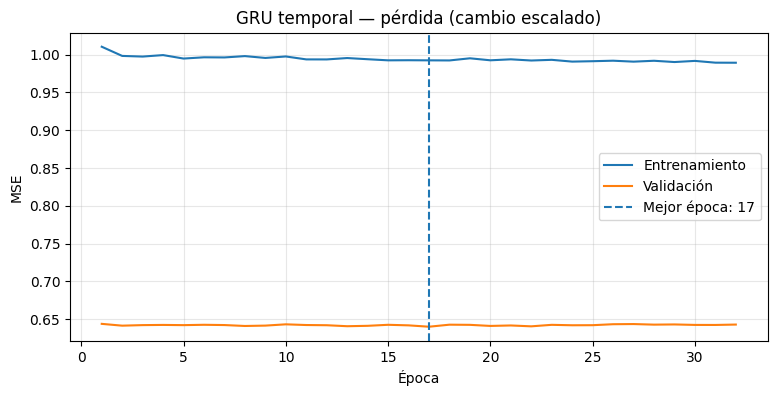

Fusión GRU + CNN SAR: mejor época 17 (de 42), MSE validación 0.4393


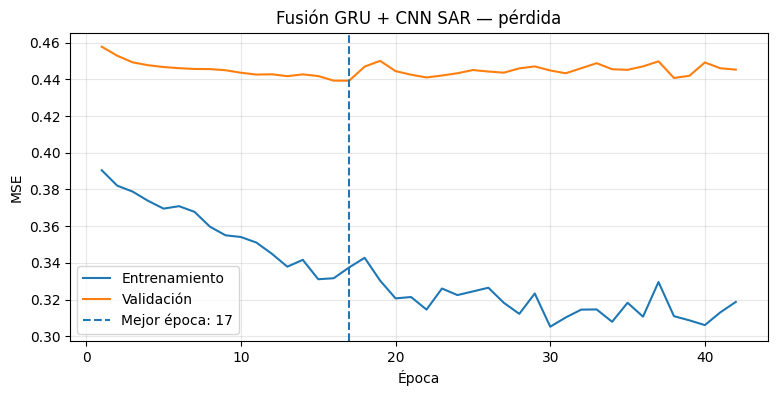

Fusión sin SAR (control): mejor época 12 (de 37), MSE validación 0.4457


In [22]:
# --- (a) MLP de la Fase 1 con los cortes de las escenas -----------------
escalador_mlp = StandardScaler()
escalador_mlp.fit(ser_ent[variables_predictoras])
escalador_mlp.scale_[escalador_mlp.scale_ < 1e-6] = 1.0
Xm_ent = escalador_mlp.transform(ser_ent[variables_predictoras])
Xm_val = escalador_mlp.transform(ser_val[variables_predictoras])
dl_mlp_ent = cargador(
    [t32(Xm_ent), t32(ser_ent[variable_objetivo].to_numpy()).reshape(-1, 1)],
    True, tamano_lote
)
dl_mlp_val = cargador(
    [t32(Xm_val), t32(ser_val[variable_objetivo].to_numpy()).reshape(-1, 1)],
    False, tamano_lote
)
torch.manual_seed(semilla)
mlp_escenas = CentinelaMLP(len(variables_predictoras))
hist_mlp, ep_mlp = entrenar_modelo(
    mlp_escenas, dl_mlp_ent, dl_mlp_val, nombre="MLP (cortes de escenas)"
)

# --- (b) GRU temporal sobre toda la serie --------------------------------
torch.manual_seed(semilla)
gru_temporal = CentinelaGRU()
hist_gru, ep_gru = entrenar_modelo(
    gru_temporal, dl_serie_ent, dl_serie_val, nombre="GRU temporal"
)
graficar_perdidas(hist_gru, ep_gru, "GRU temporal — pérdida (cambio escalado)")

# --- (c) Fusión GRU + CNN SAR (GRU congelado) ---------------------------
torch.manual_seed(semilla)
fusion_sar = CentinelaFusion(gru_temporal, usar_sar=True)
hist_fus, ep_fus = entrenar_modelo(
    fusion_sar, dl_esc_ent, dl_esc_val, tasa_aprendizaje=0.001,
    regularizacion=0.001, maximo_epocas=300, paciencia=25,
    nombre="Fusión GRU + CNN SAR"
)
graficar_perdidas(hist_fus, ep_fus, "Fusión GRU + CNN SAR — pérdida")

# --- (d) Control: misma cabeza sin rama SAR -----------------------------
torch.manual_seed(semilla)
fusion_sin_sar = CentinelaFusionSinSAR(gru_temporal)
hist_ctrl, ep_ctrl = entrenar_modelo(
    fusion_sin_sar, dl_esc_ent, dl_esc_val, tasa_aprendizaje=0.001,
    regularizacion=0.001, maximo_epocas=300, paciencia=25,
    nombre="Fusión sin SAR (control)"
)

### 2.13 Evaluación sobre las escenas (validación y prueba)
Todos los modelos se evalúan sobre **las mismas escenas**, con el nivel 12 h después del ancla como objetivo. La prueba se mira una sola vez. Con pocas escenas las diferencias pueden ser ruido: por eso se añade un intervalo bootstrap de la diferencia de MAE.

In [23]:
def predicciones_escenas(datos):
    sec, sar = tensor_secuencia(datos), tensor_sar(datos)
    mlp = predecir(
        mlp_escenas, t32(escalador_mlp.transform(datos[variables_predictoras]))
    )
    return {
        "Persistencia": datos["valorObservado"].to_numpy(),
        "MLP (Fase 1)": mlp,
        "GRU temporal": nivel_desde_cambio(datos, predecir(gru_temporal, sec)),
        "Fusión sin SAR (control)": nivel_desde_cambio(
            datos, predecir(fusion_sin_sar, sec, sar)),
        "Fusión GRU + CNN SAR": nivel_desde_cambio(
            datos, predecir(fusion_sar, sec, sar)),
    }

resultados = []
predicciones_guardadas = {}
for nombre_conjunto, datos in [("Validación", esc_val), ("Prueba", esc_pru)]:
    real = datos[variable_objetivo].to_numpy()
    predicciones = predicciones_escenas(datos)
    predicciones_guardadas[nombre_conjunto] = (datos, predicciones)
    for nombre_modelo, prediccion in predicciones.items():
        resultados.append({
            "conjunto": nombre_conjunto, "modelo": nombre_modelo,
            "escenas": len(datos), **calcular_metricas(real, prediccion)
        })

metricas_fase_2 = pd.DataFrame(resultados)
print(metricas_fase_2.round(3).to_string(index=False))

# --- Diferencia de MAE (fusión con SAR − control sin SAR), prueba -------
datos_p, pred_p = predicciones_guardadas["Prueba"]
real_p = datos_p[variable_objetivo].to_numpy()
err_sar = np.abs(pred_p["Fusión GRU + CNN SAR"] - real_p)
err_ctrl = np.abs(pred_p["Fusión sin SAR (control)"] - real_p)
generador_bs = np.random.default_rng(semilla)
diferencias = [
    (err_sar[i] - err_ctrl[i]).mean()
    for i in (generador_bs.integers(0, len(real_p), len(real_p))
              for _ in range(2000))
]
print("\nDiferencia de MAE en prueba (con SAR − sin SAR): "
      f"{np.mean(err_sar - err_ctrl):+.3f} cm | "
      f"IC95 % bootstrap [{np.percentile(diferencias, 2.5):+.3f}, "
      f"{np.percentile(diferencias, 97.5):+.3f}] cm | n = {len(real_p)}")
print("Un intervalo que contiene 0 significa que NO hay evidencia de que "
      "el radar mejore la predicción.")

metricas_fase_2.to_csv(
    os.path.join(CARPETA_FASE_2, "centinela_metricas_fase_2_escenas.csv"),
    index=False, encoding="utf-8-sig"
)

tabla_predicciones = pd.concat([
    pd.DataFrame({
        "conjunto": nombre_conjunto,
        "fechaObservacion": datos["fechaObservacion"].to_numpy(),
        "nivel_real_12h_cm": datos[variable_objetivo].to_numpy(),
        **{k: v for k, v in predicciones.items()}
    })
    for nombre_conjunto, (datos, predicciones) in predicciones_guardadas.items()
], ignore_index=True)
tabla_predicciones.to_csv(
    os.path.join(CARPETA_FASE_2, "centinela_predicciones_escenas.csv"),
    index=False, encoding="utf-8-sig"
)

  conjunto                   modelo  escenas  MAE_cm  RMSE_cm  sesgo_cm
Validación             Persistencia       41   7.098   12.996     1.732
Validación             MLP (Fase 1)       41  11.536   16.953     3.124
Validación             GRU temporal       41   7.648   13.118     2.212
Validación Fusión sin SAR (control)       41   6.703   12.873     0.158
Validación     Fusión GRU + CNN SAR       41   7.021   12.781    -0.163
    Prueba             Persistencia       41   8.683   13.263    -1.659
    Prueba             MLP (Fase 1)       41  11.994   17.250    -3.943
    Prueba             GRU temporal       41   8.633   13.147    -1.462
    Prueba Fusión sin SAR (control)       41   8.558   13.587    -3.205
    Prueba     Fusión GRU + CNN SAR       41   8.276   13.409    -4.070

Diferencia de MAE en prueba (con SAR − sin SAR): -0.282 cm | IC95 % bootstrap [-0.992, +0.432] cm | n = 41
Un intervalo que contiene 0 significa que NO hay evidencia de que el radar mejore la predicción.


### 2.14 — ROBUSTEZ: FUSIÓN CON SAR VS SIN SAR, 10 SEMILLAS

In [24]:
# ============================================================
# CELDA 2.14 — ROBUSTEZ: FUSIÓN CON SAR VS SIN SAR, 10 SEMILLAS
# Requiere haber ejecutado hasta la 2.13.
# ============================================================

semillas_robustez = list(range(10))

secuencia_val, sar_val_t = tensor_secuencia(esc_val), tensor_sar(esc_val)
secuencia_pru, sar_pru_t = tensor_secuencia(esc_pru), tensor_sar(esc_pru)

fabricas = {
    "con SAR": lambda: CentinelaFusion(gru_temporal, usar_sar=True),
    "sin SAR": lambda: CentinelaFusionSinSAR(gru_temporal),
}

filas_semillas = []
for semilla_i in semillas_robustez:
    cargador_i = cargador(
        [tensor_secuencia(esc_ent), tensor_sar(esc_ent),
         tensor_cambio(esc_ent)],
        True, 32, semilla_c=semilla_i
    )
    for nombre_variante, fabrica in fabricas.items():
        torch.manual_seed(semilla_i)
        modelo_i = fabrica()
        entrenar_modelo(
            modelo_i, cargador_i, dl_esc_val,
            tasa_aprendizaje=0.001, regularizacion=0.001,
            maximo_epocas=300, paciencia=25, silencioso=True
        )
        for nombre_conjunto, datos, sec, sar in [
            ("Validación", esc_val, secuencia_val, sar_val_t),
            ("Prueba", esc_pru, secuencia_pru, sar_pru_t),
        ]:
            prediccion = nivel_desde_cambio(
                datos, predecir(modelo_i, sec, sar)
            )
            filas_semillas.append({
                "semilla": semilla_i, "variante": nombre_variante,
                "conjunto": nombre_conjunto,
                **calcular_metricas(
                    datos[variable_objetivo].to_numpy(), prediccion
                )
            })
    print(f"Semilla {semilla_i} terminada")

df_semillas = pd.DataFrame(filas_semillas)

resumen_semillas = (
    df_semillas
    .groupby(["conjunto", "variante"])["MAE_cm"]
    .agg(media="mean", desviacion="std", minimo="min", maximo="max")
    .round(3)
)
print("\nMAE (cm) por variante, 10 semillas")
print(resumen_semillas.to_string())

pivote = df_semillas.pivot_table(
    index=["conjunto", "semilla"], columns="variante", values="MAE_cm"
)
pivote["diferencia_con_menos_sin"] = pivote["con SAR"] - pivote["sin SAR"]

print("\nDiferencia de MAE (con SAR − sin SAR), por conjunto")
for nombre_conjunto in ["Validación", "Prueba"]:
    d = pivote.loc[nombre_conjunto, "diferencia_con_menos_sin"]
    print(
        f"{nombre_conjunto}: media {d.mean():+.3f} cm | "
        f"desv. {d.std():.3f} | con SAR mejor en {(d < 0).sum()} de "
        f"{len(d)} semillas"
    )

# Referencias fijas (una sola evaluación, de la 2.13)
referencias = metricas_fase_2[
    metricas_fase_2["modelo"].isin(["Persistencia", "GRU temporal"])
][["conjunto", "modelo", "MAE_cm"]]
print("\nReferencias:")
print(referencias.round(3).to_string(index=False))

df_semillas.to_csv(
    os.path.join(CARPETA_FASE_2, "centinela_robustez_semillas.csv"),
    index=False, encoding="utf-8-sig"
)

Semilla 0 terminada
Semilla 1 terminada
Semilla 2 terminada
Semilla 3 terminada
Semilla 4 terminada
Semilla 5 terminada
Semilla 6 terminada
Semilla 7 terminada
Semilla 8 terminada
Semilla 9 terminada

MAE (cm) por variante, 10 semillas
                     media  desviacion  minimo  maximo
conjunto   variante                                   
Prueba     con SAR   8.313       0.102   8.163   8.464
           sin SAR   8.487       0.057   8.417   8.618
Validación con SAR   7.221       0.387   6.639   7.645
           sin SAR   6.741       0.058   6.681   6.853

Diferencia de MAE (con SAR − sin SAR), por conjunto
Validación: media +0.480 cm | desv. 0.403 | con SAR mejor en 3 de 10 semillas
Prueba: media -0.174 cm | desv. 0.100 | con SAR mejor en 10 de 10 semillas

Referencias:
  conjunto       modelo  MAE_cm
Validación Persistencia   7.098
Validación GRU temporal   7.648
    Prueba Persistencia   8.683
    Prueba GRU temporal   8.633


### 2.15 — ¿HAY SEÑAL EN OTRAS VARIABLES SAR? (MODELOS SIMPLES)

In [25]:
# ============================================================
# CELDA 2.15 — ¿HAY SEÑAL EN OTRAS VARIABLES SAR? (MODELOS SIMPLES)
# Requiere haber ejecutado hasta la 2.13. No usa torch ni reprocesa.
# Regla: los hiperparámetros se eligen SOLO con validación.
# ============================================================

from sklearn.linear_model import Ridge
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.preprocessing import StandardScaler

n_int = len(etiquetas)
ext = df_escenas.copy()          # ya ordenado cronológicamente por el ancla

nuevas = {}
for pol in ["VV", "VH"]:
    for i in range(n_int):
        # Cambio respecto a la escena anterior (solo información pasada)
        nuevas[f"cambio_{pol}_{i}"] = ext[f"{pol}_{i}"] - ext[f"{pol}_{i}"].shift(1)
for i in range(n_int):
    nuevas[f"razon_VH_VV_{i}"] = ext[f"VH_{i}"] - ext[f"VV_{i}"]      # en dB
for pol in ["VV", "VH"]:
    cerca = ext[[f"{pol}_0", f"{pol}_1"]].mean(axis=1)
    lejos = ext[[f"{pol}_{n_int - 2}", f"{pol}_{n_int - 1}"]].mean(axis=1)
    nuevas[f"cerca_menos_lejos_{pol}"] = cerca - lejos
ext = pd.concat([ext, pd.DataFrame(nuevas, index=ext.index)], axis=1)

columnas_sar_nuevas = list(nuevas.keys())
conjuntos_variables = {
    "Solo temporal": list(variables_predictoras),
    "+ SAR crudo (20)": list(variables_predictoras) + columnas_sar,
    "+ SAR nuevo (cambio, razón, cerca-lejos)":
        list(variables_predictoras) + columnas_sar_nuevas,
}

ent_x = ext.loc[esc_ent.index]
val_x = ext.loc[esc_val.index]
pru_x = ext.loc[esc_pru.index]

def cambio_real(d):
    return (d[variable_objetivo] - d["valorObservado"]).to_numpy()

def preparar(columnas, e=None, v=None, p=None):
    e = ent_x if e is None else e
    v = val_x if v is None else v
    p = pru_x if p is None else p
    mediana = e[columnas].median()
    escalador = StandardScaler().fit(e[columnas].fillna(mediana))
    escalador.scale_[escalador.scale_ < 1e-6] = 1.0   # evita explosiones
    f = lambda d: escalador.transform(d[columnas].fillna(mediana))
    return f(e), f(v), f(p)

def mae_nivel(d, cambio_predicho):
    pred = d["valorObservado"].to_numpy() + cambio_predicho
    return calcular_metricas(d[variable_objetivo].to_numpy(), pred)

filas = []
for nombre_conjunto_var, columnas in conjuntos_variables.items():
    X_e, X_v, X_p = preparar(columnas)
    y_e = cambio_real(ent_x)

    # --- Ridge: alpha elegido con validación ---------------------------
    candidatos = []
    for alfa in [0.1, 1, 10, 100, 1000]:
        m = Ridge(alpha=alfa).fit(X_e, y_e)
        candidatos.append((mae_nivel(val_x, m.predict(X_v))["MAE_cm"], alfa, m))
    _, alfa_elegido, m = min(candidatos, key=lambda c: c[0])
    for nombre_c, d, X in [("Validación", val_x, X_v), ("Prueba", pru_x, X_p)]:
        filas.append({
            "variables": nombre_conjunto_var,
            "modelo": f"Ridge (alpha={alfa_elegido})",
            "conjunto": nombre_c, "semilla": -1,
            **mae_nivel(d, m.predict(X))
        })

    # --- Árboles de gradiente: 10 semillas -----------------------------
    for s in range(10):
        g = GradientBoostingRegressor(
            n_estimators=150, max_depth=2, learning_rate=0.05,
            subsample=0.8, random_state=s
        ).fit(X_e, y_e)
        for nombre_c, d, X in [("Validación", val_x, X_v), ("Prueba", pru_x, X_p)]:
            filas.append({
                "variables": nombre_conjunto_var,
                "modelo": "Árboles de gradiente",
                "conjunto": nombre_c, "semilla": s,
                **mae_nivel(d, g.predict(X))
            })

df_simples = pd.DataFrame(filas)

# Referencia: persistencia sobre las mismas escenas
ref = {
    "Validación": mae_nivel(val_x, np.zeros(len(val_x)))["MAE_cm"],
    "Prueba": mae_nivel(pru_x, np.zeros(len(pru_x)))["MAE_cm"],
}

resumen = (
    df_simples.groupby(["modelo", "variables", "conjunto"])["MAE_cm"]
    .agg(MAE_medio="mean", desviacion="std")
    .round(3).reset_index()
)
resumen["modelo"] = resumen["modelo"].str.replace(r" \(alpha=.*\)", "", regex=True)
print("MAE (cm) en escenas | persistencia: validación "
      f"{ref['Validación']:.3f}, prueba {ref['Prueba']:.3f}\n")
print(resumen.pivot_table(
    index=["modelo", "variables"], columns="conjunto",
    values=["MAE_medio", "desviacion"]
).round(3).to_string())

# --- Diferencia frente a "Solo temporal" (mismo modelo) -----------------
print("\nDiferencia de MAE frente a 'Solo temporal' (negativo = el SAR ayuda)")
base = "Solo temporal"
for modelo_nombre, parte in df_simples.assign(
    modelo=df_simples["modelo"].str.replace(r" \(alpha=.*\)", "", regex=True)
).groupby("modelo"):
    for nombre_c in ["Validación", "Prueba"]:
        sub = parte[parte["conjunto"] == nombre_c]
        mae_base = sub[sub["variables"] == base].set_index("semilla")["MAE_cm"]
        for var in conjuntos_variables:
            if var == base:
                continue
            mae_var = sub[sub["variables"] == var].set_index("semilla")["MAE_cm"]
            d = (mae_var - mae_base).dropna()
            print(f"{modelo_nombre:22s} | {nombre_c:10s} | {var:42s} | "
                  f"media {d.mean():+.3f} cm | mejor en {(d < 0).sum()} de {len(d)}")

# --- CONTROL DE AZAR: mismas variables SAR pero barajadas entre escenas ---
# Si el SAR barajado (sin relación real con el nivel) "mejora" igual que el
# SAR verdadero, entonces la mejora observada es azar y no señal.
columnas_nuevas_set = conjuntos_variables["+ SAR nuevo (cambio, razón, cerca-lejos)"]
columnas_sar_total = columnas_sar + columnas_sar_nuevas
y_e = cambio_real(ent_x)
diferencias_reales = {"Validación": [], "Prueba": []}
diferencias_barajadas = {"Validación": [], "Prueba": []}

def gbr_mae(columnas, s, e, v, p):
    X_e, X_v, X_p = preparar(columnas, e, v, p)
    g = GradientBoostingRegressor(
        n_estimators=150, max_depth=2, learning_rate=0.05,
        subsample=0.8, random_state=s
    ).fit(X_e, y_e)
    return (mae_nivel(v, g.predict(X_v))["MAE_cm"],
            mae_nivel(p, g.predict(X_p))["MAE_cm"])

for s in range(10):
    base_v, base_p = gbr_mae(conjuntos_variables[base], s, ent_x, val_x, pru_x)
    real_v, real_p = gbr_mae(columnas_nuevas_set, s, ent_x, val_x, pru_x)
    azar = ext.copy()
    permutacion = np.random.default_rng(1000 + s).permutation(len(azar))
    azar[columnas_sar_total] = azar[columnas_sar_total].to_numpy()[permutacion]
    baraj_v, baraj_p = gbr_mae(
        columnas_nuevas_set, s,
        azar.loc[esc_ent.index], azar.loc[esc_val.index], azar.loc[esc_pru.index]
    )
    diferencias_reales["Validación"].append(real_v - base_v)
    diferencias_reales["Prueba"].append(real_p - base_p)
    diferencias_barajadas["Validación"].append(baraj_v - base_v)
    diferencias_barajadas["Prueba"].append(baraj_p - base_p)

print("\nCONTROL DE AZAR (árboles, '+ SAR nuevo' − 'Solo temporal', 10 repeticiones)")
for nombre_c in ["Validación", "Prueba"]:
    print(f"{nombre_c:10s} | SAR real: media {np.mean(diferencias_reales[nombre_c]):+.3f} cm"
          f" | SAR barajado (sin señal): media "
          f"{np.mean(diferencias_barajadas[nombre_c]):+.3f} cm")
print("Si el SAR barajado mejora tanto como el real, la mejora es azar.")

df_simples.to_csv(
    os.path.join(CARPETA_FASE_2, "centinela_modelos_simples_sar.csv"),
    index=False, encoding="utf-8-sig"
)

MAE (cm) en escenas | persistencia: validación 7.098, prueba 8.683

                                                              MAE_medio            desviacion           
conjunto                                                         Prueba Validación     Prueba Validación
modelo               variables                                                                          
Ridge                + SAR crudo (20)                             8.466      6.561        NaN        NaN
                     + SAR nuevo (cambio, razón, cerca-lejos)     8.515      6.538        NaN        NaN
                     Solo temporal                                8.470      6.633        NaN        NaN
Árboles de gradiente + SAR crudo (20)                             8.833      7.190      0.127      0.160
                     + SAR nuevo (cambio, razón, cerca-lejos)     8.652      6.679      0.148      0.202
                     Solo temporal                                8.913      6.722      0.13

### 2.16 (VERSIÓN INCREMENTAL) — FRACCIÓN DE AGUA POR DISTANCIA AL CAUCE

In [26]:
# ============================================================
# CELDA 2.16 (VERSIÓN INCREMENTAL) — FRACCIÓN DE AGUA POR DISTANCIA AL CAUCE
# Umbrales fijados ANTES de ver resultados (no se ajustan): agua = VV < -18 dB y VH < -24 dB
# Ya NO lee los GeoTIFF (se borran para ahorrar espacio). Une:
#   (a) el CSV guardado antes (escenas viejas) y
#   (b) los agua_<etiqueta>.csv que ahora calcula la celda 2.7 por escena.
# ============================================================
UMBRAL_AGUA_DB = {"VV": -18.0, "VH": -24.0}

ruta_agua = os.path.join(CARPETA_FASE_2, "centinela_fraccion_agua_escenas.csv")
partes = []
if os.path.exists(ruta_agua):
    partes.append(pd.read_csv(ruta_agua, dtype={"etiqueta": str}))
for r in sorted(glob.glob(os.path.join(CARPETA_ESCENAS, "agua_*.csv"))):
    partes.append(pd.read_csv(r, dtype={"etiqueta": str}))
if not partes:
    raise RuntimeError("No hay datos de agua: ni el CSV anterior ni agua_*.csv por escena.")

df_agua = (
    pd.concat(partes, ignore_index=True)
    .drop_duplicates(subset="etiqueta", keep="last")
)
df_agua = df_agua[df_agua["etiqueta"].isin(df_sar["etiqueta"])].reset_index(drop=True)
omitidas = sorted(set(df_sar["etiqueta"]) - set(df_agua["etiqueta"]))
columnas_agua = [c for c in df_agua.columns if c.startswith("agua_")]

print("Escenas con fracción de agua:", len(df_agua), "| omitidas:", len(omitidas))
if omitidas:
    print("  (primeras omitidas:", omitidas[:5], ")")
print(df_agua[["agua_VV_total", "agua_VH_total"]].describe().round(4).to_string())

df_agua.to_csv(ruta_agua, index=False, encoding="utf-8-sig")

Escenas con fracción de agua: 275 | omitidas: 0
       agua_VV_total  agua_VH_total
count       275.0000       275.0000
mean          0.0197         0.0300
std           0.0042         0.0066
min           0.0119         0.0169
25%           0.0165         0.0256
50%           0.0186         0.0292
75%           0.0230         0.0332
max           0.0302         0.0518


### 2.17 — NUEVAS PREGUNTAS, FIJADAS ANTES DE VER RESULTADOS

In [27]:
# ============================================================
# CELDA 2.17 — NUEVAS PREGUNTAS, FIJADAS ANTES DE VER RESULTADOS
#   A. Estimar el nivel del río en el momento de la imagen (regresión)
#   B. Distinguir nivel alto (> percentil 75 del entrenamiento) vs. no alto
#   C. Predecir el cambio de nivel entre dos escenas consecutivas
# Se reportan LAS TRES, salgan como salgan. Hiperparámetros solo con
# validación; prueba una sola vez; control de azar con el SAR barajado.
# Criterio de "el SAR aporta" (fijado antes): el modelo de árboles con SAR
# supera a la línea base Y al SAR barajado, en validación Y en prueba.
# ============================================================

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import roc_auc_score, r2_score

# --- Tabla: una fila por escena con nivel IDEAM a <= 1 h de la imagen ----
niveles_img = niveles_finales[["fecha_hora_ideam", "nivel_cm"]].rename(
    columns={"nivel_cm": "nivel_imagen_cm"}
).copy()
niveles_img["fecha_hora_ideam"] = niveles_img["fecha_hora_ideam"].astype("datetime64[ns]")

tabla = df_sar[["etiqueta", "hora_colombia"] + columnas_sar].merge(
    df_agua, on="etiqueta", how="inner"
)
tabla["hora_colombia"] = tabla["hora_colombia"].astype("datetime64[ns]")
tabla = pd.merge_asof(
    tabla.sort_values("hora_colombia"),
    niveles_img.sort_values("fecha_hora_ideam"),
    left_on="hora_colombia", right_on="fecha_hora_ideam",
    direction="nearest", tolerance=pd.Timedelta("1 hour")
).dropna(subset=["nivel_imagen_cm"]).reset_index(drop=True)

mes = tabla["hora_colombia"].dt.month
tabla["mes"] = mes
n_t = len(tabla)
print("Escenas con nivel a <= 1 h de la imagen:", n_t)
assert n_t >= 40, "Muy pocas escenas con nivel simultáneo."

i70, i85 = int(n_t * 0.70), int(n_t * 0.85)
part = {"ent": tabla.iloc[:i70], "val": tabla.iloc[i70:i85], "pru": tabla.iloc[i85:]}
print({k: len(v) for k, v in part.items()})

conjuntos_vars = {
    "Agua (fracciones)": columnas_agua,
    "SAR completo (dB + agua)": columnas_sar + columnas_agua,
}

def preparar_t(columnas, e, v, p):
    mediana = e[columnas].median().fillna(0.0)
    esc = StandardScaler().fit(e[columnas].fillna(mediana))
    esc.scale_[esc.scale_ < 1e-6] = 1.0
    f = lambda d: esc.transform(d[columnas].fillna(mediana))
    return f(e), f(v), f(p)

def baraja(df, columnas, semilla_b):
    out = df.copy()
    perm = np.random.default_rng(1000 + semilla_b).permutation(len(out))
    out[columnas] = out[columnas].to_numpy()[perm]
    return out

resultados = []   # filas: tarea, modelo, conjunto, metrica, valor

def anotar(tarea, modelo, conjunto, valor, metrica):
    resultados.append({"tarea": tarea, "modelo": modelo, "conjunto": conjunto,
                       "metrica": metrica, "valor": float(valor)})

def veredicto(tarea, menor_es_mejor):
    r = pd.DataFrame(resultados)
    r = r[r["tarea"] == tarea]
    ok = True
    detalle = []
    for c in ["val", "pru"]:
        b = r[(r.modelo == "Línea base") & (r.conjunto == c)]["valor"].mean()
        s = r[(r.modelo == "Árboles + SAR") & (r.conjunto == c)]["valor"].mean()
        z = r[(r.modelo == "Árboles + SAR barajado") & (r.conjunto == c)]["valor"].mean()
        mejor = (s < b and s < z) if menor_es_mejor else (s > b and s > z)
        ok &= bool(mejor)
        detalle.append(f"{c}: base {b:.3f} | SAR {s:.3f} | barajado {z:.3f}")
    return ok, detalle

# =====================  TAREA A: nivel en la imagen  =====================
tarea = "A. Estimar nivel"
y = {k: v["nivel_imagen_cm"].to_numpy() for k, v in part.items()}
clim = part["ent"].groupby("mes")["nivel_imagen_cm"].mean()
media_g = part["ent"]["nivel_imagen_cm"].mean()
for c in ["val", "pru"]:
    base = part[c]["mes"].map(clim).fillna(media_g).to_numpy()
    anotar(tarea, "Línea base", c, np.mean(np.abs(base - y[c])), "MAE_cm")

for nombre_v, cols in conjuntos_vars.items():
    X = dict(zip(["ent", "val", "pru"],
                 preparar_t(cols, part["ent"], part["val"], part["pru"])))
    mejores = min(
        ((np.mean(np.abs(Ridge(alpha=a).fit(X["ent"], y["ent"]).predict(X["val"]) - y["val"])), a)
         for a in [0.1, 1, 10, 100, 1000]), key=lambda t: t[0])
    m = Ridge(alpha=mejores[1]).fit(X["ent"], y["ent"])
    for c in ["val", "pru"]:
        anotar(tarea, f"Ridge {nombre_v}", c, np.mean(np.abs(m.predict(X[c]) - y[c])), "MAE_cm")

cols_a = conjuntos_vars["SAR completo (dB + agua)"]
for s in range(10):
    for nombre in ["Árboles + SAR", "Árboles + SAR barajado"]:
        # el barajado se aplica a todas las escenas para romper el vínculo SAR-nivel
        tbl = baraja(tabla, cols_a, s) if "barajado" in nombre else tabla
        datos = {"ent": tbl.iloc[:i70], "val": tbl.iloc[i70:i85], "pru": tbl.iloc[i85:]}
        X = dict(zip(["ent", "val", "pru"],
                     preparar_t(cols_a, datos["ent"], datos["val"], datos["pru"])))
        g = GradientBoostingRegressor(n_estimators=150, max_depth=2,
                                      learning_rate=0.05, subsample=0.8,
                                      random_state=s).fit(X["ent"], y["ent"])
        for c in ["val", "pru"]:
            anotar(tarea, nombre, c, np.mean(np.abs(g.predict(X[c]) - y[c])), "MAE_cm")

# =====================  TAREA B: nivel alto vs. no alto  =====================
tarea = "B. Nivel alto"
umbral_alto = part["ent"]["nivel_imagen_cm"].quantile(0.75)
etq = {k: (v["nivel_imagen_cm"] > umbral_alto).astype(int).to_numpy()
       for k, v in part.items()}
print(f"\nUmbral de nivel alto (P75 de entrenamiento): {umbral_alto:.1f} cm | "
      f"positivos val/prueba: {etq['val'].sum()}/{etq['pru'].sum()}")
b_ok = all(0 < etq[c].sum() < len(etq[c]) for c in ["val", "pru"])
if not b_ok:
    print("AVISO: validación o prueba no tienen ambas clases; se omite la tarea B.")
else:
    prior = part["ent"].assign(alto=etq["ent"]).groupby("mes")["alto"].mean()
    for c in ["val", "pru"]:
        base = part[c]["mes"].map(prior).fillna(etq["ent"].mean()).to_numpy()
        anotar(tarea, "Línea base", c, roc_auc_score(etq[c], base), "AUC")
    for nombre_v, cols in conjuntos_vars.items():
        X = dict(zip(["ent", "val", "pru"],
                     preparar_t(cols, part["ent"], part["val"], part["pru"])))
        mejor = max(
            ((roc_auc_score(etq["val"], LogisticRegression(C=cc, max_iter=2000)
                            .fit(X["ent"], etq["ent"]).decision_function(X["val"])), cc)
             for cc in [0.01, 0.1, 1, 10]), key=lambda t: t[0])
        m = LogisticRegression(C=mejor[1], max_iter=2000).fit(X["ent"], etq["ent"])
        for c in ["val", "pru"]:
            anotar(tarea, f"Logística {nombre_v}", c,
                   roc_auc_score(etq[c], m.decision_function(X[c])), "AUC")
    for s in range(10):
        for nombre in ["Árboles + SAR", "Árboles + SAR barajado"]:
            tbl = baraja(tabla, cols_a, s) if "barajado" in nombre else tabla
            datos = {"ent": tbl.iloc[:i70], "val": tbl.iloc[i70:i85], "pru": tbl.iloc[i85:]}
            X = dict(zip(["ent", "val", "pru"],
                         preparar_t(cols_a, datos["ent"], datos["val"], datos["pru"])))
            g = GradientBoostingClassifier(n_estimators=150, max_depth=2,
                                           learning_rate=0.05, subsample=0.8,
                                           random_state=s).fit(X["ent"], etq["ent"])
            for c in ["val", "pru"]:
                anotar(tarea, nombre, c,
                       roc_auc_score(etq[c], g.predict_proba(X[c])[:, 1]), "AUC")

# =====================  TAREA C: cambio entre escenas consecutivas  =====================
tarea = "C. Cambio de nivel"
cols_c = cols_a
delta = tabla[cols_c].diff()
delta["nivel"] = tabla["nivel_imagen_cm"].diff()
delta = delta.iloc[1:].reset_index(drop=True)
nc = len(delta)
j70, j85 = int(nc * 0.70), int(nc * 0.85)
parte_c = {"ent": delta.iloc[:j70], "val": delta.iloc[j70:j85], "pru": delta.iloc[j85:]}
yc = {k: v["nivel"].to_numpy() for k, v in parte_c.items()}
for c in ["val", "pru"]:
    anotar(tarea, "Línea base", c, np.mean(np.abs(yc[c])), "MAE_cm")  # predecir 0

X = dict(zip(["ent", "val", "pru"],
             preparar_t(cols_c, parte_c["ent"], parte_c["val"], parte_c["pru"])))
mejor = min(((np.mean(np.abs(Ridge(alpha=a).fit(X["ent"], yc["ent"]).predict(X["val"]) - yc["val"])), a)
             for a in [0.1, 1, 10, 100, 1000]), key=lambda t: t[0])
m = Ridge(alpha=mejor[1]).fit(X["ent"], yc["ent"])
for c in ["val", "pru"]:
    anotar(tarea, "Ridge SAR completo", c, np.mean(np.abs(m.predict(X[c]) - yc[c])), "MAE_cm")
for s in range(10):
    for nombre in ["Árboles + SAR", "Árboles + SAR barajado"]:
        d = baraja(delta, cols_c, s) if "barajado" in nombre else delta
        dp = {"ent": d.iloc[:j70], "val": d.iloc[j70:j85], "pru": d.iloc[j85:]}
        X = dict(zip(["ent", "val", "pru"],
                     preparar_t(cols_c, dp["ent"], dp["val"], dp["pru"])))
        g = GradientBoostingRegressor(n_estimators=150, max_depth=2,
                                      learning_rate=0.05, subsample=0.8,
                                      random_state=s).fit(X["ent"], yc["ent"])
        for c in ["val", "pru"]:
            anotar(tarea, nombre, c, np.mean(np.abs(g.predict(X[c]) - yc[c])), "MAE_cm")

# =====================  RESUMEN  =====================
df_res = pd.DataFrame(resultados)
resumen = (df_res.groupby(["tarea", "modelo", "conjunto", "metrica"])["valor"]
           .mean().round(3).unstack("conjunto").reset_index())
resumen.columns.name = None
print("\nRESULTADOS (media de las semillas cuando aplica; val = validación, pru = prueba)")
print(resumen.to_string(index=False))

print("\nVEREDICTO PRE-ESPECIFICADO (árboles con SAR vs. línea base y vs. SAR barajado)")
for tarea_v, menor in [("A. Estimar nivel", True), ("B. Nivel alto", False),
                       ("C. Cambio de nivel", True)]:
    if tarea_v not in df_res["tarea"].values:
        continue
    ok, detalle = veredicto(tarea_v, menor)
    print(f"{tarea_v:20s} -> {'EL SAR APORTA' if ok else 'NO hay evidencia de aporte'}")
    for linea in detalle:
        print("    ", linea)

df_res.to_csv(os.path.join(CARPETA_FASE_2, "centinela_nuevas_preguntas_sar.csv"),
              index=False, encoding="utf-8-sig")

Escenas con nivel a <= 1 h de la imagen: 275
{'ent': 192, 'val': 41, 'pru': 42}

Umbral de nivel alto (P75 de entrenamiento): 340.5 cm | positivos val/prueba: 4/7

RESULTADOS (media de las semillas cuando aplica; val = validación, pru = prueba)
             tarea                             modelo metrica     pru     val
  A. Estimar nivel                         Línea base  MAE_cm  94.691 111.865
  A. Estimar nivel            Ridge Agua (fracciones)  MAE_cm  91.784  89.833
  A. Estimar nivel     Ridge SAR completo (dB + agua)  MAE_cm  93.489  98.608
  A. Estimar nivel                      Árboles + SAR  MAE_cm  99.612 104.755
  A. Estimar nivel             Árboles + SAR barajado  MAE_cm 109.357 118.350
     B. Nivel alto        Logística Agua (fracciones)     AUC   0.629   0.703
     B. Nivel alto Logística SAR completo (dB + agua)     AUC   0.698   0.791
     B. Nivel alto                         Línea base     AUC   0.749   0.453
     B. Nivel alto                      Árboles + SAR

### 2.18 — HORIZONTES DE 12, 24 Y 36 HORAS (modelos simples, control de azar)

In [28]:
# ============================================================
# CELDA 2.18 — HORIZONTES DE 12, 24 Y 36 HORAS (modelos simples, control de azar)
# Se reportan LOS TRES horizontes, salgan como salgan.
# Regla fijada antes: "el SAR aporta" si los árboles con SAR superan a los
# árboles sin SAR Y al SAR barajado, en validación Y en prueba.
# Requiere las celdas hasta la 2.16 (usa df_escenas, df_agua, serie_modelado).
# ============================================================

from sklearn.linear_model import Ridge
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.preprocessing import StandardScaler

horizontes = [12, 24, 36]
n_int = len(etiquetas)

# --- Tabla base: escena + predictores temporales + SAR + agua -------------
base = df_escenas.merge(df_agua, on="etiqueta", how="left").sort_values(
    "fecha_hora_ideam"
).reset_index(drop=True)

nuevas = {}
for pol in ["VV", "VH"]:
    for i in range(n_int):
        nuevas[f"cambio_{pol}_{i}"] = base[f"{pol}_{i}"] - base[f"{pol}_{i}"].shift(1)
for i in range(n_int):
    nuevas[f"razon_VH_VV_{i}"] = base[f"VH_{i}"] - base[f"VV_{i}"]
for pol in ["VV", "VH"]:
    cerca = base[[f"{pol}_0", f"{pol}_1"]].mean(axis=1)
    lejos = base[[f"{pol}_{n_int - 2}", f"{pol}_{n_int - 1}"]].mean(axis=1)
    nuevas[f"cerca_menos_lejos_{pol}"] = cerca - lejos
base = pd.concat([base, pd.DataFrame(nuevas, index=base.index)], axis=1)

columnas_agua_h = [c for c in base.columns if c.startswith("agua_")]
columnas_sar_todo = columnas_sar + list(nuevas.keys()) + columnas_agua_h
columnas_temporales = list(variables_predictoras)

nivel_por_fecha = serie_modelado.set_index("fechaObservacion")["valorObservado"]

def preparar_h(columnas, e, v, p):
    mediana = e[columnas].median().fillna(0.0)
    esc = StandardScaler().fit(e[columnas].fillna(mediana))
    esc.scale_[esc.scale_ < 1e-6] = 1.0
    f = lambda d: esc.transform(d[columnas].fillna(mediana))
    return f(e), f(v), f(p)

def mae(real, pred):
    return float(np.mean(np.abs(np.asarray(real) - np.asarray(pred))))

filas_h = []
for h in horizontes:
    objetivo = nivel_por_fecha.reindex(
        base["fecha_hora_ideam"] + pd.Timedelta(hours=h)
    ).to_numpy()
    sub = base[~np.isnan(objetivo)].copy()
    sub["cambio_h"] = objetivo[~np.isnan(objetivo)] - sub["valorObservado"].to_numpy()
    sub = sub.reset_index(drop=True)
    n = len(sub)
    i70, i85 = int(n * 0.70), int(n * 0.85)
    partes = {"val": sub.iloc[i70:i85], "pru": sub.iloc[i85:]}
    ent = sub.iloc[:i70]
    y_ent = ent["cambio_h"].to_numpy()
    y = {k: v["cambio_h"].to_numpy() for k, v in partes.items()}

    def anotar(modelo, conjunto, valor, semilla=-1):
        filas_h.append({"horizonte_h": h, "modelo": modelo,
                        "conjunto": conjunto, "MAE_cm": valor,
                        "semilla": semilla, "escenas": n})

    for c in ["val", "pru"]:
        anotar("Persistencia", c, mae(y[c], np.zeros(len(y[c]))))

    for nombre, columnas in [("Solo temporal", columnas_temporales),
                             ("+ SAR todo", columnas_temporales + columnas_sar_todo)]:
        X_e, X_v, X_p = preparar_h(columnas, ent, partes["val"], partes["pru"])
        X = {"val": X_v, "pru": X_p}
        # Ridge: alpha elegido solo con validación
        mejor = min(((mae(y["val"], Ridge(alpha=a).fit(X_e, y_ent).predict(X_v)), a)
                     for a in [0.1, 1, 10, 100, 1000]), key=lambda t: t[0])
        r = Ridge(alpha=mejor[1]).fit(X_e, y_ent)
        for c in ["val", "pru"]:
            anotar(f"Ridge {nombre}", c, mae(y[c], r.predict(X[c])))
        for s in range(10):
            g = GradientBoostingRegressor(n_estimators=150, max_depth=2,
                                          learning_rate=0.05, subsample=0.8,
                                          random_state=s).fit(X_e, y_ent)
            for c in ["val", "pru"]:
                anotar(f"Árboles {nombre}", c, mae(y[c], g.predict(X[c])), s)

    # Control de azar: bloque SAR barajado entre escenas
    for s in range(10):
        barajada = sub.copy()
        perm = np.random.default_rng(1000 + s).permutation(n)
        barajada[columnas_sar_todo] = barajada[columnas_sar_todo].to_numpy()[perm]
        e_b = barajada.iloc[:i70]
        p_b = {"val": barajada.iloc[i70:i85], "pru": barajada.iloc[i85:]}
        cols = columnas_temporales + columnas_sar_todo
        X_e, X_v, X_p = preparar_h(cols, e_b, p_b["val"], p_b["pru"])
        g = GradientBoostingRegressor(n_estimators=150, max_depth=2,
                                      learning_rate=0.05, subsample=0.8,
                                      random_state=s).fit(X_e, y_ent)
        anotar("Árboles + SAR barajado", "val", mae(y["val"], g.predict(X_v)), s)
        anotar("Árboles + SAR barajado", "pru", mae(y["pru"], g.predict(X_p)), s)

df_h = pd.DataFrame(filas_h)
resumen_h = (df_h.groupby(["horizonte_h", "modelo", "conjunto"])["MAE_cm"]
             .mean().round(3).unstack("conjunto").reset_index())
resumen_h.columns.name = None
print("MAE (cm) por horizonte (media de semillas cuando aplica)")
print(resumen_h[["horizonte_h", "modelo", "val", "pru"]].to_string(index=False))

print("\nVEREDICTO PRE-ESPECIFICADO por horizonte")
for h in horizontes:
    d = df_h[df_h["horizonte_h"] == h]
    ok, detalle = True, []
    for c in ["val", "pru"]:
        sin = d[(d.modelo == "Árboles Solo temporal") & (d.conjunto == c)]["MAE_cm"].mean()
        con = d[(d.modelo == "Árboles + SAR todo") & (d.conjunto == c)]["MAE_cm"].mean()
        baj = d[(d.modelo == "Árboles + SAR barajado") & (d.conjunto == c)]["MAE_cm"].mean()
        ok &= bool(con < sin and con < baj)
        detalle.append(f"{c}: sin SAR {sin:.3f} | con SAR {con:.3f} | barajado {baj:.3f}")
    print(f"+{h} h -> {'EL SAR APORTA' if ok else 'NO hay evidencia de aporte'} "
          f"(escenas: {int(d['escenas'].iloc[0])})")
    for linea in detalle:
        print("    ", linea)

df_h.to_csv(os.path.join(CARPETA_FASE_2, "centinela_horizontes_12_24_36.csv"),
            index=False, encoding="utf-8-sig")

MAE (cm) por horizonte (media de semillas cuando aplica)
 horizonte_h                 modelo    val    pru
          12           Persistencia  7.098  8.683
          12       Ridge + SAR todo  7.170  8.813
          12    Ridge Solo temporal  6.633  8.470
          12 Árboles + SAR barajado  7.628  9.056
          12     Árboles + SAR todo  6.559  8.402
          12  Árboles Solo temporal  6.722  8.913
          24           Persistencia 11.561 11.683
          24       Ridge + SAR todo  9.784 11.435
          24    Ridge Solo temporal 10.917 11.162
          24 Árboles + SAR barajado 12.197 13.179
          24     Árboles + SAR todo  9.030 10.420
          24  Árboles Solo temporal 12.189 12.605
          36           Persistencia 17.732 13.854
          36       Ridge + SAR todo 16.064 13.813
          36    Ridge Solo temporal 17.529 13.520
          36 Árboles + SAR barajado 22.143 15.775
          36     Árboles + SAR todo 17.167 12.737
          36  Árboles Solo temporal 21.520 

### 2.19 Robustez del resultado a +24 h y +36 h
Los horizontes de 24 y 36 h se probaron **después** de que +12 h no mostrara aporte, así que el hallazgo es exploratorio. Esta celda lo pone a prueba: intervalo bootstrap por escenas, control de reloj (año decimal), SAR de la escena anterior (que no puede conocer el agua del momento), SAR barajado y qué grupo de variables SAR contribuye.

In [29]:

# ============================================================
# CELDA 2.19 — ROBUSTEZ DEL RESULTADO A +24 h Y +36 h
#   1) Intervalo bootstrap por escenas de la diferencia de MAE (con SAR − sin SAR)
#   2) Controles: reloj (año decimal), SAR de la escena ANTERIOR, SAR barajado
#   3) Qué grupo de variables SAR aporta (dB crudo / cambio-razón / agua)
# Requiere haber ejecutado hasta la 2.18 (usa base, columnas_* y funciones).
# ============================================================

horizontes_rob = [12, 24, 36]
semillas_rob = list(range(10))

# --- Variables adicionales (solo se calculan una vez) ---------------------
base_rob = base.copy()
base_rob["anio_decimal"] = (
    base_rob["fecha_hora_ideam"].dt.year
    + base_rob["fecha_hora_ideam"].dt.dayofyear / 366.0
)
columnas_rezago = []
for c in columnas_sar_todo:
    base_rob[f"escena_anterior_{c}"] = base_rob[c].shift(1)
    columnas_rezago.append(f"escena_anterior_{c}")

grupo_db = list(columnas_sar)
grupo_cambio = [c for c in nuevas.keys()]
grupo_agua = list(columnas_agua_h)

conjuntos_rob = {
    "Solo temporal": columnas_temporales,
    "+ reloj (año decimal)": columnas_temporales + ["anio_decimal"],
    "+ SAR todo": columnas_temporales + columnas_sar_todo,
    "+ reloj + SAR todo": columnas_temporales + ["anio_decimal"] + columnas_sar_todo,
    "+ SAR de la escena anterior": columnas_temporales + columnas_rezago,
    "+ solo dB crudo": columnas_temporales + grupo_db,
    "+ solo cambio/razón/cerca-lejos": columnas_temporales + grupo_cambio,
    "+ solo agua": columnas_temporales + grupo_agua,
}

def arboles(columnas, ent, partes, y_ent, semillas):
    """Devuelve, por conjunto, el MAE medio de las semillas y la predicción
    promediada entre semillas (para el bootstrap)."""
    X_e, X_v, X_p = preparar_h(columnas, ent, partes["val"], partes["pru"])
    X = {"val": X_v, "pru": X_p}
    preds = {"val": [], "pru": []}
    for s in semillas:
        g = GradientBoostingRegressor(
            n_estimators=150, max_depth=2, learning_rate=0.05,
            subsample=0.8, random_state=s
        ).fit(X_e, y_ent)
        for c in ["val", "pru"]:
            preds[c].append(g.predict(X[c]))
    return preds

def bootstrap_diferencia(err_a, err_b, repeticiones=5000, semilla_b=42):
    """IC95 % de media(err_a − err_b) remuestreando ESCENAS."""
    d = np.asarray(err_a) - np.asarray(err_b)
    g = np.random.default_rng(semilla_b)
    medias = [d[g.integers(0, len(d), len(d))].mean() for _ in range(repeticiones)]
    return d.mean(), np.percentile(medias, 2.5), np.percentile(medias, 97.5)

filas_rob, filas_ic = [], []
for h in horizontes_rob:
    objetivo = nivel_por_fecha.reindex(
        base_rob["fecha_hora_ideam"] + pd.Timedelta(hours=h)
    ).to_numpy()
    sub = base_rob[~np.isnan(objetivo)].copy()
    sub["cambio_h"] = objetivo[~np.isnan(objetivo)] - sub["valorObservado"].to_numpy()
    sub = sub.reset_index(drop=True)
    n = len(sub)
    i70, i85 = int(n * 0.70), int(n * 0.85)
    ent = sub.iloc[:i70]
    partes = {"val": sub.iloc[i70:i85], "pru": sub.iloc[i85:]}
    y_ent = ent["cambio_h"].to_numpy()
    y = {k: v["cambio_h"].to_numpy() for k, v in partes.items()}

    errores = {}
    for nombre, columnas in conjuntos_rob.items():
        preds = arboles(columnas, ent, partes, y_ent, semillas_rob)
        for c in ["val", "pru"]:
            mae_semillas = [mae(y[c], p) for p in preds[c]]
            filas_rob.append({
                "horizonte_h": h, "variables": nombre, "conjunto": c,
                "MAE_medio": np.mean(mae_semillas), "MAE_desv": np.std(mae_semillas),
                "escenas": n
            })
            errores[(nombre, c)] = np.abs(y[c] - np.mean(preds[c], axis=0))

    # SAR barajado (referencia de azar)
    for c in ["val", "pru"]:
        maes = []
        for s in semillas_rob:
            barajada = sub.copy()
            perm = np.random.default_rng(1000 + s).permutation(n)
            barajada[columnas_sar_todo] = barajada[columnas_sar_todo].to_numpy()[perm]
            p = arboles(columnas_temporales + columnas_sar_todo, barajada.iloc[:i70],
                        {"val": barajada.iloc[i70:i85], "pru": barajada.iloc[i85:]},
                        y_ent, [s])
            maes.append(mae(y[c], p[c][0]))
        filas_rob.append({"horizonte_h": h, "variables": "+ SAR barajado",
                          "conjunto": c, "MAE_medio": np.mean(maes),
                          "MAE_desv": np.std(maes), "escenas": n})

    # Bootstrap por escenas: (con SAR) − (sin SAR) y (reloj+SAR) − (reloj)
    for c in ["val", "pru"]:
        for etiqueta, a, b in [
            ("SAR todo − Solo temporal", "+ SAR todo", "Solo temporal"),
            ("(reloj + SAR) − reloj", "+ reloj + SAR todo", "+ reloj (año decimal)"),
        ]:
            media_d, lo, hi = bootstrap_diferencia(errores[(a, c)], errores[(b, c)])
            filas_ic.append({"horizonte_h": h, "conjunto": c,
                             "comparación": etiqueta, "dif_MAE_cm": media_d,
                             "IC95_inferior": lo, "IC95_superior": hi,
                             "IC_excluye_0": bool(hi < 0 or lo > 0)})

df_rob = pd.DataFrame(filas_rob)
df_ic = pd.DataFrame(filas_ic)

print("MAE (cm) de árboles, media de 10 semillas (desv. entre paréntesis)")
for h in horizontes_rob:
    d = df_rob[df_rob["horizonte_h"] == h]
    t = d.pivot_table(index="variables", columns="conjunto",
                      values=["MAE_medio", "MAE_desv"])
    out = pd.DataFrame({
        "validación": t[("MAE_medio", "val")].round(2).astype(str) + " (" +
                      t[("MAE_desv", "val")].round(2).astype(str) + ")",
        "prueba": t[("MAE_medio", "pru")].round(2).astype(str) + " (" +
                  t[("MAE_desv", "pru")].round(2).astype(str) + ")",
    })
    print(f"\n+{h} h  (escenas: {int(d['escenas'].iloc[0])})")
    print(out.to_string())

print("\nBOOTSTRAP POR ESCENAS: diferencia de MAE (negativo = el SAR ayuda)")
print(df_ic.round(3).to_string(index=False))
print("\nCómo leerlo: si el IC95 % incluye 0, la diferencia no es distinguible de "
      "cero con tan pocas escenas. Si 'SAR de la escena anterior' ayuda tanto como "
      "'SAR todo', el SAR actúa como un indicador de régimen/época y no como una "
      "medida del agua del momento. Si '+ reloj' iguala a '+ SAR todo', el radar "
      "era un reloj.")

df_rob.to_csv(os.path.join(CARPETA_FASE_2, "centinela_robustez_24_36_mae.csv"),
              index=False, encoding="utf-8-sig")
df_ic.to_csv(os.path.join(CARPETA_FASE_2, "centinela_robustez_24_36_bootstrap.csv"),
             index=False, encoding="utf-8-sig")

MAE (cm) de árboles, media de 10 semillas (desv. entre paréntesis)

+12 h  (escenas: 271)
                                  validación       prueba
variables                                                
+ SAR barajado                   7.63 (0.42)   9.06 (0.3)
+ SAR de la escena anterior       6.8 (0.08)  8.76 (0.13)
+ SAR todo                       6.56 (0.09)    8.4 (0.1)
+ reloj (año decimal)             6.7 (0.23)   8.85 (0.2)
+ reloj + SAR todo               6.54 (0.11)   8.39 (0.1)
+ solo agua                      7.01 (0.15)  8.54 (0.11)
+ solo cambio/razón/cerca-lejos  6.41 (0.06)  8.46 (0.11)
+ solo dB crudo                   7.13 (0.2)  8.74 (0.15)
Solo temporal                    6.72 (0.14)  8.91 (0.13)

+24 h  (escenas: 271)
                                   validación        prueba
variables                                                  
+ SAR barajado                    12.2 (0.93)  13.18 (0.83)
+ SAR de la escena anterior      11.25 (0.27)   11.83 (0.3)
+ SAR tod

### 2.20 Robustez a +48 h
Mismo análisis de la 2.19 para +48 h. Se reporta aunque no muestre aporte del SAR.

In [30]:
# ============================================================
# CELDA 2.20 — ROBUSTEZ A +48 h
#   1) Intervalo bootstrap por escenas de la diferencia de MAE (con SAR − sin SAR)
#   2) Controles: reloj (año decimal), SAR de la escena ANTERIOR, SAR barajado
#   3) Qué grupo de variables SAR aporta (dB crudo / cambio-razón / agua)
# Requiere haber ejecutado hasta la 2.18 (usa base, columnas_* y funciones).
# ============================================================

horizontes_rob = [48]
semillas_rob = list(range(10))

# --- Variables adicionales (solo se calculan una vez) ---------------------
base_rob = base.copy()
base_rob["anio_decimal"] = (
    base_rob["fecha_hora_ideam"].dt.year
    + base_rob["fecha_hora_ideam"].dt.dayofyear / 366.0
)
columnas_rezago = []
for c in columnas_sar_todo:
    base_rob[f"escena_anterior_{c}"] = base_rob[c].shift(1)
    columnas_rezago.append(f"escena_anterior_{c}")

grupo_db = list(columnas_sar)
grupo_cambio = [c for c in nuevas.keys()]
grupo_agua = list(columnas_agua_h)

conjuntos_rob = {
    "Solo temporal": columnas_temporales,
    "+ reloj (año decimal)": columnas_temporales + ["anio_decimal"],
    "+ SAR todo": columnas_temporales + columnas_sar_todo,
    "+ reloj + SAR todo": columnas_temporales + ["anio_decimal"] + columnas_sar_todo,
    "+ SAR de la escena anterior": columnas_temporales + columnas_rezago,
    "+ solo dB crudo": columnas_temporales + grupo_db,
    "+ solo cambio/razón/cerca-lejos": columnas_temporales + grupo_cambio,
    "+ solo agua": columnas_temporales + grupo_agua,
}

def arboles(columnas, ent, partes, y_ent, semillas):
    """Devuelve, por conjunto, el MAE medio de las semillas y la predicción
    promediada entre semillas (para el bootstrap)."""
    X_e, X_v, X_p = preparar_h(columnas, ent, partes["val"], partes["pru"])
    X = {"val": X_v, "pru": X_p}
    preds = {"val": [], "pru": []}
    for s in semillas:
        g = GradientBoostingRegressor(
            n_estimators=150, max_depth=2, learning_rate=0.05,
            subsample=0.8, random_state=s
        ).fit(X_e, y_ent)
        for c in ["val", "pru"]:
            preds[c].append(g.predict(X[c]))
    return preds

def bootstrap_diferencia(err_a, err_b, repeticiones=5000, semilla_b=42):
    """IC95 % de media(err_a − err_b) remuestreando ESCENAS."""
    d = np.asarray(err_a) - np.asarray(err_b)
    g = np.random.default_rng(semilla_b)
    medias = [d[g.integers(0, len(d), len(d))].mean() for _ in range(repeticiones)]
    return d.mean(), np.percentile(medias, 2.5), np.percentile(medias, 97.5)

filas_rob, filas_ic = [], []
for h in horizontes_rob:
    objetivo = nivel_por_fecha.reindex(
        base_rob["fecha_hora_ideam"] + pd.Timedelta(hours=h)
    ).to_numpy()
    sub = base_rob[~np.isnan(objetivo)].copy()
    sub["cambio_h"] = objetivo[~np.isnan(objetivo)] - sub["valorObservado"].to_numpy()
    sub = sub.reset_index(drop=True)
    n = len(sub)
    i70, i85 = int(n * 0.70), int(n * 0.85)
    ent = sub.iloc[:i70]
    partes = {"val": sub.iloc[i70:i85], "pru": sub.iloc[i85:]}
    y_ent = ent["cambio_h"].to_numpy()
    y = {k: v["cambio_h"].to_numpy() for k, v in partes.items()}

    errores = {}
    for nombre, columnas in conjuntos_rob.items():
        preds = arboles(columnas, ent, partes, y_ent, semillas_rob)
        for c in ["val", "pru"]:
            mae_semillas = [mae(y[c], p) for p in preds[c]]
            filas_rob.append({
                "horizonte_h": h, "variables": nombre, "conjunto": c,
                "MAE_medio": np.mean(mae_semillas), "MAE_desv": np.std(mae_semillas),
                "escenas": n
            })
            errores[(nombre, c)] = np.abs(y[c] - np.mean(preds[c], axis=0))

    # SAR barajado (referencia de azar)
    for c in ["val", "pru"]:
        maes = []
        for s in semillas_rob:
            barajada = sub.copy()
            perm = np.random.default_rng(1000 + s).permutation(n)
            barajada[columnas_sar_todo] = barajada[columnas_sar_todo].to_numpy()[perm]
            p = arboles(columnas_temporales + columnas_sar_todo, barajada.iloc[:i70],
                        {"val": barajada.iloc[i70:i85], "pru": barajada.iloc[i85:]},
                        y_ent, [s])
            maes.append(mae(y[c], p[c][0]))
        filas_rob.append({"horizonte_h": h, "variables": "+ SAR barajado",
                          "conjunto": c, "MAE_medio": np.mean(maes),
                          "MAE_desv": np.std(maes), "escenas": n})

    # Bootstrap por escenas: (con SAR) − (sin SAR) y (reloj+SAR) − (reloj)
    for c in ["val", "pru"]:
        for etiqueta, a, b in [
            ("SAR todo − Solo temporal", "+ SAR todo", "Solo temporal"),
            ("(reloj + SAR) − reloj", "+ reloj + SAR todo", "+ reloj (año decimal)"),
        ]:
            media_d, lo, hi = bootstrap_diferencia(errores[(a, c)], errores[(b, c)])
            filas_ic.append({"horizonte_h": h, "conjunto": c,
                             "comparación": etiqueta, "dif_MAE_cm": media_d,
                             "IC95_inferior": lo, "IC95_superior": hi,
                             "IC_excluye_0": bool(hi < 0 or lo > 0)})

df_rob = pd.DataFrame(filas_rob)
df_ic = pd.DataFrame(filas_ic)

print("MAE (cm) de árboles, media de 10 semillas (desv. entre paréntesis)")
for h in horizontes_rob:
    d = df_rob[df_rob["horizonte_h"] == h]
    t = d.pivot_table(index="variables", columns="conjunto",
                      values=["MAE_medio", "MAE_desv"])
    out = pd.DataFrame({
        "validación": t[("MAE_medio", "val")].round(2).astype(str) + " (" +
                      t[("MAE_desv", "val")].round(2).astype(str) + ")",
        "prueba": t[("MAE_medio", "pru")].round(2).astype(str) + " (" +
                  t[("MAE_desv", "pru")].round(2).astype(str) + ")",
    })
    print(f"\n+{h} h  (escenas: {int(d['escenas'].iloc[0])})")
    print(out.to_string())

print("\nBOOTSTRAP POR ESCENAS: diferencia de MAE (negativo = el SAR ayuda)")
print(df_ic.round(3).to_string(index=False))
print("\nCómo leerlo: si el IC95 % incluye 0, la diferencia no es distinguible de "
      "cero con tan pocas escenas. Si 'SAR de la escena anterior' ayuda tanto como "
      "'SAR todo', el SAR actúa como un indicador de régimen/época y no como una "
      "medida del agua del momento. Si '+ reloj' iguala a '+ SAR todo', el radar "
      "era un reloj.")

df_rob.to_csv(os.path.join(CARPETA_FASE_2, "centinela_robustez_48_mae.csv"),
              index=False, encoding="utf-8-sig")
df_ic.to_csv(os.path.join(CARPETA_FASE_2, "centinela_robustez_48_bootstrap.csv"),
             index=False, encoding="utf-8-sig")

MAE (cm) de árboles, media de 10 semillas (desv. entre paréntesis)

+48 h  (escenas: 268)
                                   validación        prueba
variables                                                  
+ SAR barajado                    22.1 (1.24)  21.65 (1.32)
+ SAR de la escena anterior      20.04 (0.56)   19.46 (0.3)
+ SAR todo                        19.65 (0.5)  17.34 (0.38)
+ reloj (año decimal)            34.29 (3.85)  28.18 (3.28)
+ reloj + SAR todo               23.59 (2.07)  20.17 (1.52)
+ solo agua                       18.7 (0.39)  18.02 (0.22)
+ solo cambio/razón/cerca-lejos  17.89 (0.38)  18.72 (0.39)
+ solo dB crudo                  20.19 (0.29)  17.06 (0.46)
Solo temporal                    23.16 (0.56)  20.36 (0.48)

BOOTSTRAP POR ESCENAS: diferencia de MAE (negativo = el SAR ayuda)
 horizonte_h conjunto              comparación  dif_MAE_cm  IC95_inferior  IC95_superior  IC_excluye_0
          48      val SAR todo − Solo temporal      -3.444         -7.595      

### 2.21 Pregunta principal: +24 h con validación por bloques de tiempo
Se entrena con el pasado y se prueba en 5 tramos sucesivos del futuro (136 escenas de prueba en total: 129 de la órbita 142 y 7 de la 48), con las mismas variables e hiperparámetros de la 2.18, sin ajustar nada con estos tramos. Se retiran del entrenamiento las escenas cuyo objetivo cae dentro del tramo de prueba. Controles: SAR barajado, reloj (año decimal) y SAR de la escena anterior. +36 h se incluye como confirmación.

In [31]:
# ============================================================
# CELDA 2.21 — VALIDACIÓN POR BLOQUES DE TIEMPO (pregunta principal: +24 h; +36 h confirma)
# Se entrena con el pasado y se prueba en tramos sucesivos del futuro.
# Así se usan unas 100-150 escenas de prueba en lugar de ~33.
# Sin ajustar nada con estos tramos: los hiperparámetros son los mismos de antes.
# Requiere haber ejecutado hasta la 2.18 (usa base, columnas_*, nivel_por_fecha, preparar_h, mae).
# ============================================================

horizontes_blq = [24, 36]
semillas_blq = list(range(5))
n_bloques = 5
fraccion_inicial = 0.50
longitud_bloque_boot = 5   # bootstrap por bloques de 5 escenas seguidas (respeta la dependencia en el tiempo)

base_blq = base.copy()
base_blq["anio_decimal"] = (
    base_blq["fecha_hora_ideam"].dt.year
    + base_blq["fecha_hora_ideam"].dt.dayofyear / 366.0
)
columnas_rez_blq = []
for c in columnas_sar_todo:
    base_blq[f"escena_anterior_{c}"] = base_blq[c].shift(1)
    columnas_rez_blq.append(f"escena_anterior_{c}")

conjuntos_blq = {
    "Solo temporal": columnas_temporales,
    "+ reloj (año decimal)": columnas_temporales + ["anio_decimal"],
    "+ SAR todo": columnas_temporales + columnas_sar_todo,
    "+ reloj + SAR todo": columnas_temporales + ["anio_decimal"] + columnas_sar_todo,
    "+ SAR de la escena anterior": columnas_temporales + columnas_rez_blq,
}

def predecir_arboles(columnas, ent, prb, semillas):
    X_e, X_p, _ = preparar_h(columnas, ent, prb, prb)
    y_e = ent["cambio_h"].to_numpy()
    preds = []
    for s in semillas:
        g = GradientBoostingRegressor(
            n_estimators=150, max_depth=2, learning_rate=0.05,
            subsample=0.8, random_state=s
        ).fit(X_e, y_e)
        preds.append(g.predict(X_p))
    return np.mean(preds, axis=0)

def bootstrap_por_bloques(err_a, err_b, largo=5, repeticiones=5000, semilla_b=42):
    d = np.asarray(err_a) - np.asarray(err_b)
    n = len(d)
    g = np.random.default_rng(semilla_b)
    k = int(np.ceil(n / largo))
    medias = []
    for _ in range(repeticiones):
        inicios = g.integers(0, max(n - largo + 1, 1), k)
        muestra = np.concatenate([d[i:i + largo] for i in inicios])[:n]
        medias.append(muestra.mean())
    return d.mean(), np.percentile(medias, 2.5), np.percentile(medias, 97.5)

filas_f, filas_g, filas_b = [], [], []
for h in horizontes_blq:
    objetivo = nivel_por_fecha.reindex(
        base_blq["fecha_hora_ideam"] + pd.Timedelta(hours=h)
    ).to_numpy()
    sub = base_blq[~np.isnan(objetivo)].copy()
    sub["cambio_h"] = objetivo[~np.isnan(objetivo)] - sub["valorObservado"].to_numpy()
    sub = sub.sort_values("fecha_hora_ideam").reset_index(drop=True)
    n = len(sub)
    inicio = int(n * fraccion_inicial)
    cortes = np.linspace(inicio, n, n_bloques + 1).astype(int)

    # SAR barajado: una permutación fija por semilla de control
    barajados = []
    for s in range(5):
        b = sub.copy()
        perm = np.random.default_rng(1000 + s).permutation(n)
        b[columnas_sar_todo] = b[columnas_sar_todo].to_numpy()[perm]
        barajados.append(b)

    errores = {nombre: [] for nombre in list(conjuntos_blq) + ["+ SAR barajado"]}
    for k in range(n_bloques):
        a, z = cortes[k], cortes[k + 1]
        prb = sub.iloc[a:z]
        fecha_ini = prb["fecha_hora_ideam"].iloc[0]
        # purga: se quitan escenas de entrenamiento cuyo objetivo cae en el tramo de prueba
        ent = sub.iloc[:a]
        ent = ent[ent["fecha_hora_ideam"] + pd.Timedelta(hours=h) < fecha_ini]
        y = prb["cambio_h"].to_numpy()
        for nombre, columnas in conjuntos_blq.items():
            p = predecir_arboles(columnas, ent, prb, semillas_blq)
            err = np.abs(y - p)
            errores[nombre].append(err)
            filas_f.append({"horizonte_h": h, "bloque": k + 1, "variables": nombre,
                            "escenas_prueba": len(prb), "MAE": err.mean()})
        errs_baj = []
        for s, b in enumerate(barajados):
            eb = b.iloc[:a]
            eb = eb[eb["fecha_hora_ideam"] + pd.Timedelta(hours=h) < fecha_ini]
            p = predecir_arboles(columnas_temporales + columnas_sar_todo,
                                 eb, b.iloc[a:z], [s])
            errs_baj.append(np.abs(y - p))
        err = np.mean(errs_baj, axis=0)
        errores["+ SAR barajado"].append(err)
        filas_f.append({"horizonte_h": h, "bloque": k + 1, "variables": "+ SAR barajado",
                        "escenas_prueba": len(prb), "MAE": err.mean()})

    todos = {nombre: np.concatenate(v) for nombre, v in errores.items()}
    for nombre, e in todos.items():
        filas_g.append({"horizonte_h": h, "variables": nombre,
                        "escenas_prueba": len(e), "MAE_global": e.mean()})
    for etiqueta, a_, b_ in [
        ("SAR todo − Solo temporal", "+ SAR todo", "Solo temporal"),
        ("SAR todo − SAR barajado", "+ SAR todo", "+ SAR barajado"),
        ("(reloj + SAR) − reloj", "+ reloj + SAR todo", "+ reloj (año decimal)"),
        ("SAR todo − SAR escena anterior", "+ SAR todo", "+ SAR de la escena anterior"),
    ]:
        d, lo, hi = bootstrap_por_bloques(todos[a_], todos[b_], longitud_bloque_boot)
        filas_b.append({"horizonte_h": h, "comparación": etiqueta,
                        "dif_MAE_cm": d, "IC95_inferior": lo, "IC95_superior": hi,
                        "IC_excluye_0": bool(hi < 0 or lo > 0)})
    # En cuántos bloques el SAR gana al modelo sin SAR
    gana = sum(
        np.mean(errores["+ SAR todo"][k]) < np.mean(errores["Solo temporal"][k])
        for k in range(n_bloques)
    )
    filas_g.append({"horizonte_h": h, "variables": f"bloques donde SAR todo < Solo temporal: {gana}/{n_bloques}",
                    "escenas_prueba": np.nan, "MAE_global": np.nan})

df_f = pd.DataFrame(filas_f)
df_g = pd.DataFrame(filas_g)
df_b = pd.DataFrame(filas_b)

print("MAE por bloque de tiempo (cm)")
for h in horizontes_blq:
    t = df_f[df_f["horizonte_h"] == h].pivot_table(
        index="variables", columns="bloque", values="MAE").round(2)
    print(f"\n+{h} h")
    print(t.to_string())

print("\nMAE GLOBAL (todas las escenas de prueba juntas)")
print(df_g.round(2).to_string(index=False))

print("\nBOOTSTRAP POR BLOQUES: diferencia de MAE (negativo = el primero es mejor)")
print(df_b.round(3).to_string(index=False))

df_f.to_csv(os.path.join(CARPETA_FASE_2, "centinela_bloques_mae_por_bloque.csv"),
            index=False, encoding="utf-8-sig")
df_g.to_csv(os.path.join(CARPETA_FASE_2, "centinela_bloques_mae_global.csv"),
            index=False, encoding="utf-8-sig")
df_b.to_csv(os.path.join(CARPETA_FASE_2, "centinela_bloques_bootstrap.csv"),
            index=False, encoding="utf-8-sig")

MAE por bloque de tiempo (cm)

+24 h
bloque                           1      2      3      4      5
variables                                                     
+ SAR barajado               17.54  15.95  11.67  10.96  12.45
+ SAR de la escena anterior  15.94  14.93   9.60  11.07  12.45
+ SAR todo                   15.13  13.84   8.24   9.15  11.35
+ reloj (año decimal)        16.46  15.72  10.83   9.97  13.11
+ reloj + SAR todo           14.85  14.03   8.17   9.16  11.68
Solo temporal                16.98  16.17  12.03  10.64  12.73

+36 h
bloque                           1      2      3      4      5
variables                                                     
+ SAR barajado               30.92  23.15  18.34  19.72  14.93
+ SAR de la escena anterior  29.63  20.43  16.59  20.12  13.95
+ SAR todo                   29.51  15.97  14.06  16.66  12.88
+ reloj (año decimal)        35.99  20.91  17.17  18.23  14.75
+ reloj + SAR todo           28.82  16.79  13.84  16.68  12.96
Solo tempor

### 2.22 Red profunda (GRU + CNN SAR) a +24 h con validación por bloques
La red se entrena desde cero en cada bloque, solo con escenas anteriores. Se comparan red solo con la serie, red con SAR y red con SAR barajado, con dos valores de regularización fijados de antemano (se reportan ambos).

In [32]:
# ============================================================
# CELDA 2.22 — RED PROFUNDA (GRU + CNN SAR) A +24 h CON VALIDACIÓN POR BLOQUES
# Se entrena DESDE CERO en cada bloque, solo con escenas anteriores al bloque
# (no se reutiliza el GRU preentrenado de la 2.12: habría visto el futuro de los bloques).
# Controles: red sin SAR y red con SAR barajado. Regularización (weight decay) probada
# con dos valores FIJADOS DE ANTEMANO; se reportan los dos, sin elegir el mejor.
# Requiere haber ejecutado hasta la 2.21 (usa base_blq, columnas_sar, columnas_secuencia,
# entrenar_modelo, bootstrap_por_bloques, nivel_por_fecha, etiquetas, dispositivo).
# ============================================================

h_prof = 24
decaimientos = [0.001, 0.01]
semillas_prof = list(range(5))
n_bloques_p = 5
fraccion_inicial_p = 0.50

class CentinelaDirecta(torch.nn.Module):
    """GRU entrenable sobre la secuencia + (opcional) CNN 1-D sobre la matriz SAR 2x10."""
    def __init__(self, usar_sar=True, oculto=16, p_drop=0.3):
        super(CentinelaDirecta, self).__init__()
        self.usar_sar = usar_sar
        self.gru = torch.nn.GRU(1, oculto, batch_first=True)
        entradas = oculto
        if usar_sar:
            self.cnn = torch.nn.Sequential(
                torch.nn.Conv1d(2, 8, kernel_size=3, padding=1),
                torch.nn.ReLU(),
                torch.nn.Conv1d(8, 8, kernel_size=3, padding=1),
                torch.nn.ReLU(),
                torch.nn.Flatten(),
                torch.nn.Linear(8 * len(etiquetas), 16),
                torch.nn.ReLU(),
            )
            entradas += 16
        self.cabeza = torch.nn.Sequential(
            torch.nn.Linear(entradas, 16),
            torch.nn.ReLU(),
            torch.nn.Dropout(p=p_drop),
            torch.nn.Linear(16, 1),
        )

    def forward(self, secuencia, sar):
        _, estado = self.gru(secuencia)
        car = estado[-1]
        if self.usar_sar:
            car = torch.cat([car, self.cnn(sar)], dim=1)
        return self.cabeza(car)

def _t32(a):
    return torch.tensor(np.asarray(a, dtype=np.float32))

def preparar_red(ent, otros, tabla_sar):
    """Escala con estadísticas SOLO de 'ent'. 'tabla_sar' es la tabla de la que se lee el SAR
    (la original o la barajada), alineada por índice con ent y otros."""
    med_n = float(ent[columnas_secuencia].to_numpy().mean())
    des_n = float(ent[columnas_secuencia].to_numpy().std()) or 1.0
    des_c = float(ent["cambio_h"].std()) or 1.0
    mediana = tabla_sar.loc[ent.index, columnas_sar].median().fillna(0.0)
    sar_e = tabla_sar.loc[ent.index, columnas_sar].fillna(mediana)
    med_s, des_s = sar_e.mean(), sar_e.std().replace(0, 1.0).fillna(1.0)

    def construir(d, con_objetivo=True):
        sec = ((d[columnas_secuencia].to_numpy() - med_n) / des_n)
        sar = ((tabla_sar.loc[d.index, columnas_sar].fillna(mediana) - med_s) / des_s).to_numpy()
        salida = [_t32(sec).unsqueeze(-1), _t32(sar).reshape(len(d), 2, len(etiquetas))]
        if con_objetivo:
            salida.append(_t32(d["cambio_h"].to_numpy() / des_c).reshape(-1, 1))
        return salida
    return construir, des_c

def entrenar_y_predecir(usar_sar, tabla_sar, ent, prb, decaimiento, semilla_r):
    n_in = int(len(ent) * 0.80)
    ent_in, val_in = ent.iloc[:n_in], ent.iloc[n_in:]
    construir, des_c = preparar_red(ent_in, None, tabla_sar)
    g = torch.Generator(); g.manual_seed(semilla_r)
    dl_e = DataLoader(TensorDataset(*construir(ent_in)), batch_size=16, shuffle=True, generator=g)
    dl_v = DataLoader(TensorDataset(*construir(val_in)), batch_size=32, shuffle=False)
    torch.manual_seed(semilla_r)
    red = CentinelaDirecta(usar_sar=usar_sar)
    entrenar_modelo(red, dl_e, dl_v, tasa_aprendizaje=0.001, regularizacion=decaimiento,
                    maximo_epocas=200, paciencia=20, nombre="red", silencioso=True)
    sec, sar = construir(prb, con_objetivo=False)
    return predecir(red, sec, sar) * des_c        # cambio predicho en cm

filas_p, filas_gp, filas_bp = [], [], []
objetivo = nivel_por_fecha.reindex(
    base_blq["fecha_hora_ideam"] + pd.Timedelta(hours=h_prof)
).to_numpy()
sub = base_blq[~np.isnan(objetivo)].copy()
sub["cambio_h"] = objetivo[~np.isnan(objetivo)] - sub["valorObservado"].to_numpy()
sub = sub.sort_values("fecha_hora_ideam").reset_index(drop=True)
n = len(sub)
cortes = np.linspace(int(n * fraccion_inicial_p), n, n_bloques_p + 1).astype(int)

barajadas = []
for s in semillas_prof:
    b = sub.copy()
    perm = np.random.default_rng(1000 + s).permutation(n)
    b[columnas_sar] = b[columnas_sar].to_numpy()[perm]
    barajadas.append(b)

nombres = ["Red solo serie", "Red + SAR", "Red + SAR barajado"]
for wd in decaimientos:
    errores = {nm: [] for nm in nombres}
    for k in range(n_bloques_p):
        a, z = cortes[k], cortes[k + 1]
        prb = sub.iloc[a:z]
        ini = prb["fecha_hora_ideam"].iloc[0]
        ent = sub.iloc[:a]
        ent = ent[ent["fecha_hora_ideam"] + pd.Timedelta(hours=h_prof) < ini]
        y = prb["cambio_h"].to_numpy()
        pr = {nm: [] for nm in nombres}
        for s in semillas_prof:
            pr["Red solo serie"].append(entrenar_y_predecir(False, sub, ent, prb, wd, s))
            pr["Red + SAR"].append(entrenar_y_predecir(True, sub, ent, prb, wd, s))
            pr["Red + SAR barajado"].append(
                entrenar_y_predecir(True, barajadas[s], ent, prb, wd, s))
        for nm in nombres:
            err = np.abs(y - np.mean(pr[nm], axis=0))
            errores[nm].append(err)
            filas_p.append({"decaimiento": wd, "bloque": k + 1, "modelo": nm,
                            "escenas_prueba": len(prb), "MAE": err.mean()})
        print(f"decaimiento {wd} | bloque {k + 1}/{n_bloques_p} listo")

    todos = {nm: np.concatenate(v) for nm, v in errores.items()}
    for nm, e in todos.items():
        filas_gp.append({"decaimiento": wd, "modelo": nm,
                         "escenas_prueba": len(e), "MAE_global": e.mean()})
    for etiqueta, a_, b_ in [("Red + SAR − Red solo serie", "Red + SAR", "Red solo serie"),
                             ("Red + SAR − Red + SAR barajado", "Red + SAR", "Red + SAR barajado")]:
        d, lo, hi = bootstrap_por_bloques(todos[a_], todos[b_], 5)
        filas_bp.append({"decaimiento": wd, "comparación": etiqueta, "dif_MAE_cm": d,
                         "IC95_inferior": lo, "IC95_superior": hi,
                         "IC_excluye_0": bool(hi < 0 or lo > 0)})
    gana = sum(np.mean(errores["Red + SAR"][k]) < np.mean(errores["Red solo serie"][k])
               for k in range(n_bloques_p))
    filas_gp.append({"decaimiento": wd, "modelo": f"bloques donde Red + SAR < Red solo serie: {gana}/{n_bloques_p}",
                     "escenas_prueba": np.nan, "MAE_global": np.nan})

df_pf = pd.DataFrame(filas_p)
df_pg = pd.DataFrame(filas_gp)
df_pb = pd.DataFrame(filas_bp)

print(f"\nRED PROFUNDA a +{h_prof} h — MAE por bloque (cm)")
for wd in decaimientos:
    t = df_pf[df_pf["decaimiento"] == wd].pivot_table(index="modelo", columns="bloque", values="MAE").round(2)
    print(f"\ndecaimiento (weight decay) = {wd}")
    print(t.to_string())
print("\nMAE GLOBAL")
print(df_pg.round(2).to_string(index=False))
print("\nBOOTSTRAP POR BLOQUES (negativo = el primero es mejor)")
print(df_pb.round(3).to_string(index=False))
if "df_g" in globals():
    ref = df_g[(df_g["horizonte_h"] == h_prof) & df_g["variables"].isin(["Solo temporal", "+ SAR todo"])]
    print("\nReferencia: árboles de la 2.21 a +%d h" % h_prof)
    print(ref[["variables", "MAE_global"]].round(2).to_string(index=False))

df_pf.to_csv(os.path.join(CARPETA_FASE_2, "centinela_red_bloques_por_bloque.csv"),
             index=False, encoding="utf-8-sig")
df_pg.to_csv(os.path.join(CARPETA_FASE_2, "centinela_red_bloques_global.csv"),
             index=False, encoding="utf-8-sig")
df_pb.to_csv(os.path.join(CARPETA_FASE_2, "centinela_red_bloques_bootstrap.csv"),
             index=False, encoding="utf-8-sig")

decaimiento 0.001 | bloque 1/5 listo
decaimiento 0.001 | bloque 2/5 listo
decaimiento 0.001 | bloque 3/5 listo
decaimiento 0.001 | bloque 4/5 listo
decaimiento 0.001 | bloque 5/5 listo
decaimiento 0.01 | bloque 1/5 listo
decaimiento 0.01 | bloque 2/5 listo
decaimiento 0.01 | bloque 3/5 listo
decaimiento 0.01 | bloque 4/5 listo
decaimiento 0.01 | bloque 5/5 listo

RED PROFUNDA a +24 h — MAE por bloque (cm)

decaimiento (weight decay) = 0.001
bloque                  1      2      3      4      5
modelo                                               
Red + SAR           15.16  13.32   8.39  11.43  10.97
Red + SAR barajado  15.28  14.51  10.12  10.83  12.07
Red solo serie      15.34  14.24  10.42  11.51  12.23

decaimiento (weight decay) = 0.01
bloque                  1      2      3      4      5
modelo                                               
Red + SAR           15.15  13.54   7.91  11.54  11.02
Red + SAR barajado  15.50  14.56  10.22  11.17  12.13
Red solo serie      15.39  14.35  

### 2.23 Control por órbita
¿La mejora con SAR podría deberse a que cada órbita pasa a una hora distinta del día (05:51 frente a 18:22 hora local)? Se compara solo temporal, + órbita, + SAR y + órbita + SAR con validación por bloques.

In [33]:
# ============================================================
# CELDA 2.23 — CONTROL POR ÓRBITA (142 descendente ~05:51 h local | 48 ascendente ~18:22 h local)
# Pregunta: ¿el SAR ayuda por sí mismo o solo porque delata de qué órbita (hora del día) es la escena?
# Misma validación por bloques de la 2.21 (+24 h y +36 h), mismos hiperparámetros, sin ajustar nada.
# Conjuntos: Solo temporal | + indicador de órbita | + SAR todo | + indicador de órbita + SAR todo
# Se reporta: MAE global, MAE por órbita de la escena de prueba y bootstrap por bloques.
# Requiere haber ejecutado la 2.21 (usa base_blq, predecir_arboles, bootstrap_por_bloques) y la celda 2.7.
# ============================================================

cat_o = df_productos_seleccionados[["Name", "relativeOrbitNumber"]].copy()
cat_o["etiqueta"] = cat_o["Name"].apply(etiqueta_escena)
orbita48_por_etiqueta = (
    cat_o.drop_duplicates("etiqueta").set_index("etiqueta")["relativeOrbitNumber"] == 48
).astype(float)

base_orb = base_blq.copy()
base_orb["orbita48"] = base_orb["etiqueta"].astype(str).map(orbita48_por_etiqueta)
assert base_orb["orbita48"].notna().all(), "Hay escenas sin órbita asignada: revisa el tipo de 'etiqueta'."
print("Escenas por órbita en la tabla de modelado:",
      base_orb["orbita48"].map({0.0: "142 desc.", 1.0: "48 asc."}).value_counts().to_dict())

conjuntos_orb = {
    "Solo temporal": columnas_temporales,
    "+ órbita": columnas_temporales + ["orbita48"],
    "+ SAR todo": columnas_temporales + columnas_sar_todo,
    "+ órbita + SAR todo": columnas_temporales + ["orbita48"] + columnas_sar_todo,
}

filas_o, filas_ob, filas_oc = [], [], []
for h in [24, 36]:
    objetivo = nivel_por_fecha.reindex(
        base_orb["fecha_hora_ideam"] + pd.Timedelta(hours=h)
    ).to_numpy()
    sub = base_orb[~np.isnan(objetivo)].copy()
    sub["cambio_h"] = objetivo[~np.isnan(objetivo)] - sub["valorObservado"].to_numpy()
    sub = sub.sort_values("fecha_hora_ideam").reset_index(drop=True)
    n = len(sub)
    inicio = int(n * fraccion_inicial)
    cortes = np.linspace(inicio, n, n_bloques + 1).astype(int)

    errores = {nombre: [] for nombre in conjuntos_orb}
    orbitas = []
    for k in range(n_bloques):
        a, z = cortes[k], cortes[k + 1]
        prb = sub.iloc[a:z]
        fecha_ini = prb["fecha_hora_ideam"].iloc[0]
        ent = sub.iloc[:a]
        ent = ent[ent["fecha_hora_ideam"] + pd.Timedelta(hours=h) < fecha_ini]
        y = prb["cambio_h"].to_numpy()
        orbitas.append(prb["orbita48"].to_numpy())
        for nombre, columnas in conjuntos_orb.items():
            p = predecir_arboles(columnas, ent, prb, semillas_blq)
            errores[nombre].append(np.abs(y - p))

    todos = {nombre: np.concatenate(v) for nombre, v in errores.items()}
    orb = np.concatenate(orbitas)
    for nombre, e in todos.items():
        filas_o.append({"horizonte_h": h, "variables": nombre, "escenas_prueba": len(e),
                        "MAE_global": e.mean(),
                        "MAE_órbita_142": e[orb == 0].mean() if (orb == 0).any() else np.nan,
                        "MAE_órbita_48": e[orb == 1].mean() if (orb == 1).any() else np.nan})
    print(f"+{h} h: escenas de prueba {len(orb)} (órbita 142: {int((orb == 0).sum())}, órbita 48: {int((orb == 1).sum())})")

    comparaciones = [
        ("SAR todo − Solo temporal", "+ SAR todo", "Solo temporal"),
        ("SAR todo − (solo órbita)", "+ SAR todo", "+ órbita"),
        ("(órbita + SAR) − órbita", "+ órbita + SAR todo", "+ órbita"),
        ("órbita − Solo temporal", "+ órbita", "Solo temporal"),
    ]
    for etiqueta_c, a_, b_ in comparaciones:
        d, lo, hi = bootstrap_por_bloques(todos[a_], todos[b_], longitud_bloque_boot)
        filas_ob.append({"horizonte_h": h, "subconjunto": "todas", "comparación": etiqueta_c,
                         "escenas": len(orb), "dif_MAE_cm": d, "IC95_inferior": lo,
                         "IC95_superior": hi, "IC_excluye_0": bool(hi < 0 or lo > 0)})
    # SAR todo vs Solo temporal, separado por órbita de la escena de prueba
    for valor, nombre_o in [(0.0, "solo órbita 142"), (1.0, "solo órbita 48")]:
        m = orb == valor
        if m.sum() >= 15:
            d, lo, hi = bootstrap_por_bloques(
                todos["+ SAR todo"][m], todos["Solo temporal"][m], longitud_bloque_boot)
            filas_ob.append({"horizonte_h": h, "subconjunto": nombre_o,
                             "comparación": "SAR todo − Solo temporal", "escenas": int(m.sum()),
                             "dif_MAE_cm": d, "IC95_inferior": lo, "IC95_superior": hi,
                             "IC_excluye_0": bool(hi < 0 or lo > 0)})
        else:
            filas_ob.append({"horizonte_h": h, "subconjunto": nombre_o,
                             "comparación": "SAR todo − Solo temporal", "escenas": int(m.sum()),
                             "dif_MAE_cm": np.nan, "IC95_inferior": np.nan,
                             "IC95_superior": np.nan, "IC_excluye_0": np.nan})

df_o = pd.DataFrame(filas_o)
df_ob = pd.DataFrame(filas_ob)
print("\nMAE (cm) — global y por órbita de la escena de prueba")
print(df_o.round(2).to_string(index=False))
print("\nBOOTSTRAP POR BLOQUES (negativo = el primero es mejor; con pocas escenas el IC es muy ancho)")
print(df_ob.round(3).to_string(index=False))
print("\nCómo leerlo: si '(órbita + SAR) − órbita' sigue siendo negativo con IC que excluye 0, el SAR aporta más allá"
      " de saber de qué órbita viene la escena. Si 'órbita − Solo temporal' ya iguala la mejora, el SAR era un indicador de órbita.")

df_o.to_csv(os.path.join(CARPETA_FASE_2, "centinela_control_orbita_mae.csv"), index=False, encoding="utf-8-sig")
df_ob.to_csv(os.path.join(CARPETA_FASE_2, "centinela_control_orbita_bootstrap.csv"), index=False, encoding="utf-8-sig")

Escenas por órbita en la tabla de modelado: {'142 desc.': 219, '48 asc.': 52}
+24 h: escenas de prueba 136 (órbita 142: 129, órbita 48: 7)
+36 h: escenas de prueba 136 (órbita 142: 129, órbita 48: 7)

MAE (cm) — global y por órbita de la escena de prueba
 horizonte_h           variables  escenas_prueba  MAE_global  MAE_órbita_142  MAE_órbita_48
          24       Solo temporal             136       13.70           13.64          14.94
          24            + órbita             136       13.56           13.48          15.14
          24          + SAR todo             136       11.54           11.57          11.07
          24 + órbita + SAR todo             136       11.60           11.61          11.35
          36       Solo temporal             136       21.02           20.80          25.02
          36            + órbita             136       21.06           20.83          25.23
          36          + SAR todo             136       17.78           17.58          21.47
         

---
# RAMAS A, B y C de la Fase 2 (rúbrica del Módulo 2)
Las tres ramas se evalúan con la **misma partición cronológica** y se reportan **todas**, incluso las que no mejoran la línea base.
* **Rama B — serie temporal (2.24):** RNN simple, LSTM y GRU sobre una ventana de 14 pasos de 12 h.
* **Rama A — imágenes (2.26):** CNN preentrenadas (ResNet-18 y EfficientNet-B0) con extracción de características y con ajuste fino, y Grad-CAM.
* **Rama C — fusión (2.27):** concatenación de los embeddings de la CNN y del GRU, con ablación (solo imagen, solo serie, fusión) y un control con imágenes barajadas.

**Limitaciones que se declaran:** (i) la guía pide 500 imágenes o más en 3 categorías; con datos validados solo hay **271 escenas** (263 con ventana completa de la serie); (ii) la Rama B usa 32 unidades ocultas (la guía sugiere 64 a 128) y se reporta tal cual; (iii) la prueba de las ramas A y C tiene solo 40 escenas, de modo que las diferencias pequeñas no son concluyentes; (iv) los pesos de las ramas A y C se guardan en `Fase_2/pesos`.

### 2.24 Rama B — redes recurrentes (RNN, LSTM, GRU) sobre la serie de nivel
Ventana de 14 pasos (7 días, cada 12 h), cambio de nivel a +12 h y +24 h, 3 semillas, parada temprana. Se compara con la persistencia.

+12 h | ejemplos: entrenamiento 7660, validación 1703, prueba 1644
  RNN +12 h listo
  LSTM +12 h listo
  GRU +12 h listo
+24 h | ejemplos: entrenamiento 7624, validación 1703, prueba 1633
  RNN +24 h listo
  LSTM +24 h listo
  GRU +24 h listo

RAMA B — métricas sobre el nivel (media y desviación entre 3 semillas; la persistencia no tiene semillas)

+12 h — VALIDACIÓN
             MAE_cm        RMSE_cm        MAPE_pct       
               mean    std    mean    std     mean    std
modelo                                                   
GRU           7.250  0.051  10.325  0.009    4.960  0.046
LSTM          7.140  0.095  10.225  0.070    4.872  0.062
Persistencia  7.119    NaN  10.299    NaN    4.853    NaN
RNN           7.223  0.050  10.259  0.051    4.944  0.042

+12 h — PRUEBA
              MAE_cm        RMSE_cm        MAPE_pct       
                mean    std    mean    std     mean    std
modelo                                                    
GRU           13.524  0.094  1

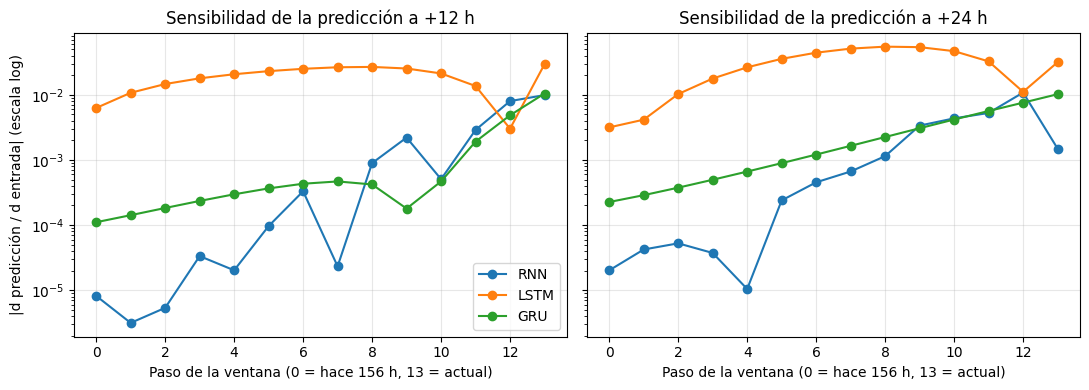


Sensibilidad a los pasos extremos de la ventana (cuanto menor la razón antiguo/actual, más se desvanece la información lejana):
 horizonte_h modelo  sens_paso_más_antiguo  sens_paso_actual  razón antiguo/actual
          12    RNN                0.00001           0.00988               0.00083
          12   LSTM                0.00627           0.02948               0.21281
          12    GRU                0.00011           0.01044               0.01059
          24    RNN                0.00002           0.00149               0.01350
          24   LSTM                0.00316           0.03158               0.10001
          24    GRU                0.00023           0.01020               0.02214


In [34]:
# ============================================================
# CELDA 2.24 — RAMA B: REDES RECURRENTES (RNN simple, LSTM, GRU) SOBRE LA SERIE, VENTANA DE 14 PASOS
# Entrada: los 14 últimos niveles tomados cada 12 h (7 días de historia), de más antiguo a más reciente.
# Salida: el CAMBIO de nivel a +12 h y a +24 h (nivel futuro = nivel actual + cambio), como en la Fase 2.
# Reglas fijadas ANTES de ver resultados: misma partición cronológica de la Fase 1 (cortes de la 1.3),
# mismo bucle de entrenamiento (MSE, Adam, parada temprana), 32 unidades, 3 semillas, se reportan los tres modelos
# y la persistencia. Métricas sobre el nivel en cm: MAE, RMSE y MAPE. La prueba se calcula una sola vez, al final.
# Además: evidencia del gradiente que se desvanece (sensibilidad de la predicción a cada paso de la ventana).
# Requiere las celdas hasta la 1.4 (usa serie_modelado, fecha_inicio_validacion, fecha_inicio_prueba,
# entrenar_modelo, predecir, dispositivo, semilla, CARPETA_FASE_2).
# ============================================================

VENTANA = 14
PASO_H = 12
horizontes_rnn = [12, 24]
semillas_rnn = [0, 1, 2]
tipos_rnn = ["RNN", "LSTM", "GRU"]

serie_nivel = serie_modelado.set_index("fechaObservacion")["valorObservado"]


def tabla_ventanas(h):
    # Cada fila: 14 niveles (lags de 12 h) + nivel a +h horas. Se descartan las filas con algún dato faltante.
    fechas = serie_nivel.index
    cols = []
    for j in range(VENTANA):                       # j = 0 es el más antiguo, j = 13 el actual
        retraso = (VENTANA - 1 - j) * PASO_H
        cols.append(serie_nivel.reindex(fechas - pd.Timedelta(hours=retraso)).to_numpy())
    X = np.column_stack(cols).astype("float64")
    y = serie_nivel.reindex(fechas + pd.Timedelta(hours=h)).to_numpy().astype("float64")
    ok = np.isfinite(X).all(axis=1) & np.isfinite(y)
    return (X[ok], y[ok], fechas[ok], fechas[ok] + pd.Timedelta(hours=h))


class ModeloRecurrente(torch.nn.Module):
    def __init__(self, tipo, oculto=32):
        super(ModeloRecurrente, self).__init__()
        capa = {"RNN": torch.nn.RNN, "LSTM": torch.nn.LSTM, "GRU": torch.nn.GRU}[tipo]
        self.recurrente = capa(1, oculto, batch_first=True)
        self.cabeza = torch.nn.Sequential(
            torch.nn.Linear(oculto, 16), torch.nn.ReLU(), torch.nn.Linear(16, 1)
        )

    def forward(self, x):
        salida, _ = self.recurrente(x)
        return self.cabeza(salida[:, -1, :])


def metricas_nivel(real, pred):
    e = np.asarray(pred) - np.asarray(real)
    real = np.asarray(real)
    no_cero = np.abs(real) > 1e-6
    return {"MAE_cm": float(np.mean(np.abs(e))),
            "RMSE_cm": float(np.sqrt(np.mean(e ** 2))),
            "MAPE_pct": float(np.mean(np.abs(e[no_cero]) / np.abs(real[no_cero])) * 100)}


def gradiente_por_paso(modelo, X, n=512):
    # |d salida / d entrada_t| promedio, para cada paso t de la ventana (t = 0 el más antiguo).
    modelo.eval()
    x = X[:n].clone().to(dispositivo).requires_grad_(True)
    with torch.backends.cudnn.flags(enabled=False):
        with torch.enable_grad():
            salida = modelo(x)
            salida.sum().backward()
    return x.grad.abs().mean(dim=0).squeeze(-1).cpu().numpy()


filas_rnn, grad_rnn, modelos_guardados = [], {}, {}
for h in horizontes_rnn:
    X, y, f_obs, f_obj = tabla_ventanas(h)
    m_ent = f_obj < fecha_inicio_validacion
    m_val = (f_obj >= fecha_inicio_validacion) & (f_obj < fecha_inicio_prueba)
    m_pru = f_obj >= fecha_inicio_prueba
    actual = X[:, -1]
    cambio = y - actual
    media_n, desv_n = X[m_ent].mean(), X[m_ent].std()
    desv_c = cambio[m_ent].std()
    print(f"+{h} h | ejemplos: entrenamiento {int(m_ent.sum())}, validación {int(m_val.sum())}, prueba {int(m_pru.sum())}")

    T = lambda a: torch.tensor(np.asarray(a, dtype=np.float32))
    seq = T((X - media_n) / desv_n).unsqueeze(-1)          # (n, 14, 1)
    obj = T(cambio / desv_c).reshape(-1, 1)
    idx = lambda m: torch.tensor(np.where(m)[0])

    for nombre_p, m in [("val", m_val), ("pru", m_pru)]:
        filas_rnn.append({"horizonte_h": h, "modelo": "Persistencia", "semilla": -1,
                          "conjunto": nombre_p, "mejor_época": np.nan,
                          **metricas_nivel(y[m], actual[m])})

    for tipo in tipos_rnn:
        for s in semillas_rnn:
            g = torch.Generator(); g.manual_seed(s)
            dl_e = DataLoader(TensorDataset(seq[idx(m_ent)], obj[idx(m_ent)]),
                              batch_size=64, shuffle=True, generator=g)
            dl_v = DataLoader(TensorDataset(seq[idx(m_val)], obj[idx(m_val)]),
                              batch_size=128, shuffle=False)
            torch.manual_seed(s)
            red = ModeloRecurrente(tipo)
            _, mejor_ep = entrenar_modelo(red, dl_e, dl_v, nombre=f"{tipo} +{h}h s{s}", silencioso=True)
            for nombre_p, m in [("val", m_val), ("pru", m_pru)]:
                p = actual[m] + predecir(red, seq[idx(m)]) * desv_c
                filas_rnn.append({"horizonte_h": h, "modelo": tipo, "semilla": s,
                                  "conjunto": nombre_p, "mejor_época": mejor_ep,
                                  **metricas_nivel(y[m], p)})
            if s == semillas_rnn[0]:
                modelos_guardados[(tipo, h)] = red
                grad_rnn[(tipo, h)] = gradiente_por_paso(red, seq[idx(m_val)])
        print(f"  {tipo} +{h} h listo")

df_rnn = pd.DataFrame(filas_rnn)
resumen_rnn = (
    df_rnn.groupby(["horizonte_h", "conjunto", "modelo"])[["MAE_cm", "RMSE_cm", "MAPE_pct"]]
    .agg(["mean", "std"]).round(3)
)
print("\nRAMA B — métricas sobre el nivel (media y desviación entre 3 semillas; la persistencia no tiene semillas)")
for h in horizontes_rnn:
    for c in ["val", "pru"]:
        print(f"\n+{h} h — {'VALIDACIÓN' if c == 'val' else 'PRUEBA'}")
        print(resumen_rnn.loc[(h, c)].to_string())
df_rnn.to_csv(os.path.join(CARPETA_FASE_2, "centinela_rama_b_recurrentes.csv"),
              index=False, encoding="utf-8-sig")

# --- Evidencia del gradiente que se desvanece --------------------------------
filas_g = []
fig, ejes = plt.subplots(1, len(horizontes_rnn), figsize=(11, 4), sharey=True)
for eje, h in zip(np.atleast_1d(ejes), horizontes_rnn):
    for tipo in tipos_rnn:
        gr = grad_rnn[(tipo, h)]
        eje.plot(range(VENTANA), gr, marker="o", label=tipo)
        filas_g.append({"horizonte_h": h, "modelo": tipo,
                        "sens_paso_más_antiguo": float(gr[0]),
                        "sens_paso_actual": float(gr[-1]),
                        "razón antiguo/actual": float(gr[0] / max(gr[-1], 1e-12))})
    eje.set_yscale("log"); eje.grid(alpha=0.3)
    eje.set_xlabel("Paso de la ventana (0 = hace 156 h, 13 = actual)")
    eje.set_title(f"Sensibilidad de la predicción a +{h} h")
np.atleast_1d(ejes)[0].set_ylabel("|d predicción / d entrada| (escala log)")
np.atleast_1d(ejes)[0].legend()
plt.tight_layout(); plt.show()
tabla_gradientes = pd.DataFrame(filas_g)
print("\nSensibilidad a los pasos extremos de la ventana (cuanto menor la razón antiguo/actual,"
      " más se desvanece la información lejana):")
print(tabla_gradientes.round(5).to_string(index=False))
tabla_gradientes.to_csv(os.path.join(CARPETA_FASE_2, "centinela_rama_b_gradientes.csv"),
                        index=False, encoding="utf-8-sig")

**Lectura de la Rama B.** A +12 h y a +24 h **ninguna red recurrente mejora a la persistencia**: en prueba a +12 h la persistencia tiene MAE 13.35 cm frente a 13.52 (GRU), 13.74 (LSTM) y 14.27 (RNN); a +24 h, 22.10 frente a 22.47 (GRU), 22.89 (LSTM) y 22.40 (RNN). En validación LSTM y persistencia son prácticamente iguales (11.22 y 11.12 cm a +24 h). El MAE de prueba es mayor que el de validación porque el periodo de prueba contiene crecidas más fuertes.
La sensibilidad de la predicción a cada paso de la ventana muestra el **gradiente que se desvanece**: la RNN simple casi no usa el paso más antiguo (razón antiguo/actual de 0.0008 a +12 h), la GRU lo atenúa mucho (0.011) y la LSTM conserva más memoria (0.21).

### 2.24a Recortes SAR de 224 × 224 y etiqueta de 3 clases (entrada de las ramas A y C)
Esta es la misma celda que la Fase 3 usa como 3.1: lee los recortes guardados por la 2.7 y construye el archivo `centinela_recortes_sar_224.npz`, con la etiqueta de tres clases (baja, estable, sube; umbral ±4 cm a +24 h).

Recortes cargados: (271, 3, 224, 224) (escenas, canales, alto, ancho)
Escenas sin recorte válido (excluidas): 0 []

Imágenes por clase y partición (umbral ±4 cm a +24 h):
         entrenamiento  validación  prueba  total
clase                                            
baja                92          21      18    131
estable             51          13      12     76
sube                46           7      11     64

Proporción de la clase mayoritaria en validación y prueba (referencia: responder siempre esa clase): {'validación': 0.512, 'prueba': 0.439}


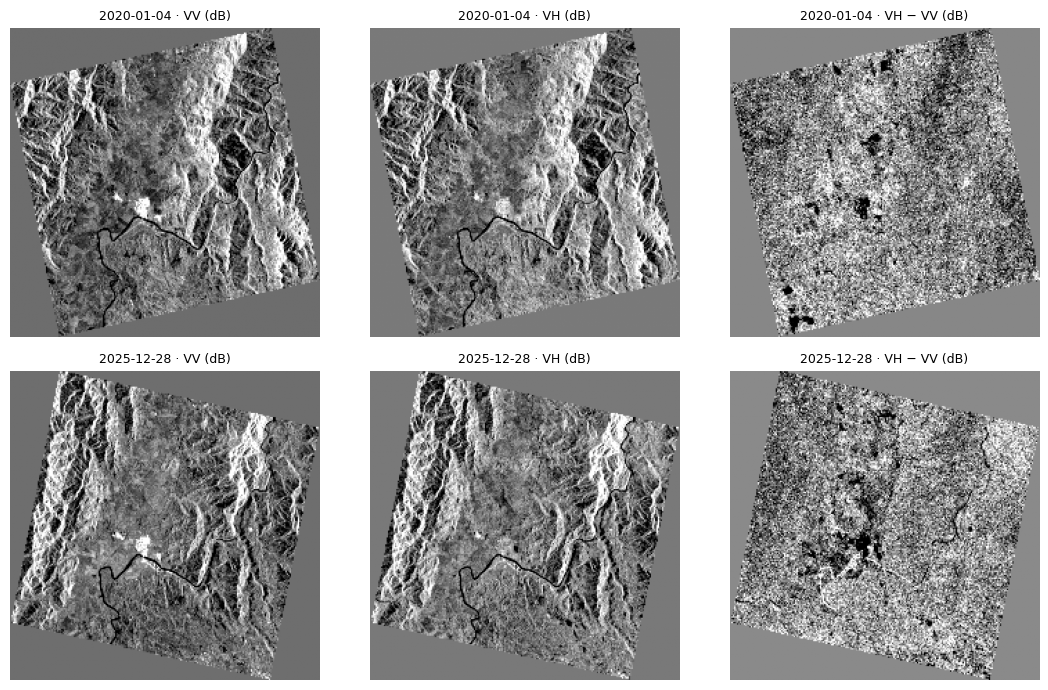

In [35]:
# ============================================================
# CELDA 3.1 (VERSIÓN NUEVA) — RECORTES SAR PARA LA RAMA VISUAL, ETIQUETA DE 3 CLASES — FASE 3
# YA NO lee los GeoTIFF (se borraron para liberar Drive): lee los recortes 224x224x3 que dejó la 2.7
# en Fase_3/chips/<etiqueta>.npy (canal 0 = VV dB, canal 1 = VH dB, canal 2 = VH - VV dB).
# Etiqueta (fijada de antemano, a +24 h respecto al nivel del ancla):
#   0 = BAJA    si el cambio < -4 cm
#   1 = ESTABLE si |cambio| <= 4 cm
#   2 = SUBE    si el cambio > +4 cm
# El umbral de 4 cm es el mismo de la Fase 1. Los conteos por clase se muestran ANTES de entrenar nada.
# Requiere haber ejecutado hasta la 2.18 (usa df_escenas, nivel_por_fecha). Sustituye a la 3.1 anterior.
# ============================================================
CARPETA_FASE_3 = os.path.join(CARPETA_BASE, "Fase_3")
CARPETA_CHIPS = os.path.join(CARPETA_FASE_3, "chips")
RUTA_RECORTES = os.path.join(CARPETA_FASE_3, "centinela_recortes_sar_224.npz")
RUTA_INDICE = os.path.join(CARPETA_FASE_3, "centinela_recortes_indice.csv")
TAM = 224
H_VISUAL = 24
UMBRAL_CM = 4.0
NOMBRES_CLASE = {0: "baja", 1: "estable", 2: "sube"}

objetivo_24 = nivel_por_fecha.reindex(
    df_escenas["fecha_hora_ideam"] + pd.Timedelta(hours=H_VISUAL)
).to_numpy()
tabla = df_escenas[["etiqueta", "fecha_hora_ideam", "valorObservado"]].copy()
tabla["nivel_objetivo_24h_cm"] = objetivo_24
tabla = tabla.dropna().sort_values("fecha_hora_ideam").reset_index(drop=True)
tabla["cambio_24h_cm"] = tabla["nivel_objetivo_24h_cm"] - tabla["valorObservado"]
tabla["clase"] = np.where(tabla["cambio_24h_cm"] < -UMBRAL_CM, 0,
                          np.where(tabla["cambio_24h_cm"] > UMBRAL_CM, 2, 1)).astype(int)

recortes, validas, faltan = [], [], []
for etiqueta_e in tabla["etiqueta"]:
    ruta = os.path.join(CARPETA_CHIPS, f"{etiqueta_e}.npy")
    try:
        c = np.load(ruta)
        if c.shape != (3, TAM, TAM) or not np.isfinite(c.astype("float32")).all():
            raise ValueError("forma o valores inválidos")
        recortes.append(c.astype("float16"))
        validas.append(etiqueta_e)
    except Exception:
        faltan.append(etiqueta_e)

if not recortes:
    raise RuntimeError(f"No se encontró ningún recorte en {CARPETA_CHIPS}. Revisa que la 2.7 los haya guardado.")

indice = tabla[tabla["etiqueta"].isin(validas)].reset_index(drop=True)
X = np.stack(recortes)
np.savez_compressed(
    RUTA_RECORTES, X=X, y=indice["clase"].to_numpy(),
    cambio_24h_cm=indice["cambio_24h_cm"].to_numpy(),
    etiqueta=indice["etiqueta"].to_numpy(),
    fecha=indice["fecha_hora_ideam"].astype(str).to_numpy(),
)
indice.to_csv(RUTA_INDICE, index=False, encoding="utf-8-sig")

print(f"Recortes cargados: {X.shape} (escenas, canales, alto, ancho)")
print(f"Escenas sin recorte válido (excluidas): {len(faltan)}", faltan[:5])

# --- Conteo por clase, total y por partición cronológica 70/15/15 (la misma de la 3.2) ---
n = len(indice)
i70, i85 = int(n * 0.70), int(n * 0.85)
partes = {"entrenamiento": indice.iloc[:i70], "validación": indice.iloc[i70:i85], "prueba": indice.iloc[i85:]}
conteo = pd.DataFrame({p: d["clase"].map(NOMBRES_CLASE).value_counts() for p, d in partes.items()}).reindex(
    list(NOMBRES_CLASE.values())).fillna(0).astype(int)
conteo["total"] = conteo.sum(axis=1)
print(f"\nImágenes por clase y partición (umbral ±{UMBRAL_CM:g} cm a +{H_VISUAL} h):")
print(conteo.to_string())
print("\nProporción de la clase mayoritaria en validación y prueba (referencia: responder siempre esa clase):",
      {p: round(float(d["clase"].value_counts(normalize=True).max()), 3) for p, d in list(partes.items())[1:]})
if (conteo.drop(columns="total").loc[:, ["validación", "prueba"]] < 3).any().any():
    print("\nAVISO: alguna clase tiene menos de 3 imágenes en validación o prueba. Las métricas por clase serán muy inestables;"
          " hay que declararlo en el informe (no se cambia el umbral para arreglarlo).")

fig, ejes = plt.subplots(2, 3, figsize=(11, 7))
for fila_i, i in enumerate([0, len(X) - 1]):
    for c, nombre in enumerate(["VV (dB)", "VH (dB)", "VH − VV (dB)"]):
        canal = X[i, c].astype("float32")
        ejes[fila_i, c].imshow(canal, cmap="gray",
                               vmin=np.percentile(canal, 2), vmax=np.percentile(canal, 98))
        ejes[fila_i, c].set_title(f"{indice['fecha_hora_ideam'][i]:%Y-%m-%d} · {nombre}", fontsize=9)
        ejes[fila_i, c].axis("off")
plt.tight_layout()
plt.show()

### 2.25 Datos comunes de las ramas A y C
Une, para cada escena, el recorte SAR y la ventana de 14 niveles que termina en el ancla IDEAM. Partición cronológica 70/15/15 (184 / 39 / 40 escenas). Objetivo: **cambio de nivel a +24 h (cm)**. La prueba se lee una sola vez, al final de cada rama.

In [36]:
# ============================================================
# CELDA 2.25 — DATOS COMUNES DE LAS RAMAS A Y C: IMÁGENES SAR + VENTANA DE LA SERIE, MISMA ESCENA
# Une, para cada escena Sentinel-1 con recorte válido, (a) el recorte 224x224x3 (VV, VH, VH-VV en dB, de la 3.1)
# y (b) la ventana de 14 niveles (cada 12 h, 7 días) que termina en la hora del ancla IDEAM (tabla_ventanas de la 2.24).
# Objetivo de las ramas A y C: el CAMBIO de nivel a +24 h en cm (regresión, como en la Fase 2).
# Partición cronológica 70/15/15 sobre las escenas (la misma lógica de la 3.2). La prueba se mira UNA sola vez, al final.
# Requiere: 3.1 ejecutada alguna vez (el .npz está en Drive) y la 2.24 (usa tabla_ventanas, VENTANA, dispositivo, CARPETA_BASE).
# ============================================================
import copy, gc, random
from torchvision import models
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler

RUTA_NPZ_AC = os.path.join(CARPETA_BASE, "Fase_3", "centinela_recortes_sar_224.npz")
datos_c = np.load(RUTA_NPZ_AC, allow_pickle=True)
fechas_c = pd.DatetimeIndex(pd.to_datetime(datos_c["fecha"]))

Xv, yv, f_obs_v, f_obj_v = tabla_ventanas(24)
f_obs_idx = pd.DatetimeIndex(f_obs_v)
if f_obs_idx.tz is None and fechas_c.tz is not None:
    fechas_c = fechas_c.tz_localize(None)
elif f_obs_idx.tz is not None and fechas_c.tz is None:
    fechas_c = fechas_c.tz_localize(f_obs_idx.tz)
pos_v = pd.Series(np.arange(len(f_obs_idx)), index=f_obs_idx)
pos_v = pos_v[~pos_v.index.duplicated()]
ubic = pos_v.reindex(fechas_c)
ok_v = ubic.notna().to_numpy()
print(f"Escenas con recorte: {len(fechas_c)} | con ventana completa de 14 pasos: {int(ok_v.sum())} | "
      f"excluidas por ventana incompleta: {int((~ok_v).sum())}")

orden = np.where(ok_v)[0]
chips_c = datos_c["X"][orden]
fechas_c = fechas_c[orden]
cambio_c = datos_c["cambio_24h_cm"][orden].astype("float32")
serie_c = Xv[ubic.to_numpy()[ok_v].astype(int)].astype("float32")
n_c = len(cambio_c)
clase_c = np.where(cambio_c < -4.0, 0, np.where(cambio_c > 4.0, 2, 1))

i70, i85 = int(n_c * 0.70), int(n_c * 0.85)
idx_ent, idx_val, idx_pru = np.arange(0, i70), np.arange(i70, i85), np.arange(i85, n_c)
desv_y = float(cambio_c[idx_ent].std())
print(f"Partición cronológica: entrenamiento {len(idx_ent)} | validación {len(idx_val)} | prueba {len(idx_pru)}")
print(f"Cambio a +24 h (cm): media entren. {cambio_c[idx_ent].mean():.2f}, desv. {desv_y:.2f}")
print("Clases (baja / estable / sube) por conjunto:",
      {nombre: np.bincount(clase_c[idx], minlength=3).tolist()
       for nombre, idx in [("ent", idx_ent), ("val", idx_val), ("pru", idx_pru)]})

# --- Escala a [0, 1] con límites de ENTRENAMIENTO y normalización ImageNet --------------------
limites_ac = []
for c in range(3):
    v = chips_c[idx_ent, c].astype("float32")
    limites_ac.append((float(np.percentile(v, 1)), float(np.percentile(v, 99))))
T01 = torch.empty((n_c, 3, 224, 224), dtype=torch.float32)
for c, (lo, hi) in enumerate(limites_ac):
    T01[:, c] = torch.from_numpy(np.clip((chips_c[:, c].astype("float32") - lo) / (hi - lo), 0, 1))
MEDIA_IMN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
DESV_IMN = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
T_img = (T01 - MEDIA_IMN) / DESV_IMN
print("Tensor de imágenes:", tuple(T_img.shape), "| límites dB por canal:",
      [(round(a, 1), round(b, 1)) for a, b in limites_ac])

dispositivo = torch.device("cuda" if torch.cuda.is_available() else "cpu")
usa_amp = (dispositivo.type == "cuda")
print("Dispositivo para las ramas A y C:", dispositivo, "| GPU:", torch.cuda.get_device_name(0) if usa_amp else "NO HAY GPU (será muy lento)")

def mae_np(a, b):
    return float(np.mean(np.abs(np.asarray(a) - np.asarray(b))))

def crear_backbone(nombre):
    if nombre == "ResNet-18":
        m = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
        d = m.fc.in_features
        m.fc = torch.nn.Identity()
    elif nombre == "EfficientNet-B0":
        m = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT)
        d = m.classifier[1].in_features
        m.classifier = torch.nn.Identity()
    else:
        raise ValueError(nombre)
    return m, d

cache_features = {}

def obtener_features(nombre):
    if nombre in cache_features:
        return cache_features[nombre]
    m, d = crear_backbone(nombre)
    m = m.to(dispositivo).eval()
    salidas = []
    with torch.no_grad():
        for i in range(0, n_c, 32):
            xb = T_img[i:i + 32].to(dispositivo)
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=usa_amp):
                salidas.append(m(xb).float().cpu().numpy())
    cache_features[nombre] = np.concatenate(salidas)
    del m
    gc.collect()
    if usa_amp:
        torch.cuda.empty_cache()
    return cache_features[nombre]

print("Listo. Siguen la 2.26 (Rama A) y la 2.27 (Rama C).")

Escenas con recorte: 271 | con ventana completa de 14 pasos: 263 | excluidas por ventana incompleta: 8
Partición cronológica: entrenamiento 184 | validación 39 | prueba 40
Cambio a +24 h (cm): media entren. -2.89, desv. 19.42
Clases (baja / estable / sube) por conjunto: {'ent': [89, 50, 45], 'val': [19, 13, 7], 'pru': [18, 12, 10]}
Tensor de imágenes: (263, 3, 224, 224) | límites dB por canal: [(-15.1, -3.5), (-21.2, -10.3), (-8.6, -4.2)]
Dispositivo para las ramas A y C: cuda | GPU: Tesla T4
Listo. Siguen la 2.26 (Rama A) y la 2.27 (Rama C).


### 2.26 Rama A — CNN preentrenadas sobre los recortes SAR
Extracción de características (red congelada + Ridge) frente a ajuste fino de toda la red, con ResNet-18 y EfficientNet-B0 (3 semillas), referencias "cambio = 0" y mediana de entrenamiento, exploración de las imágenes y Grad-CAM. Justificación: con pocas imágenes la extracción de características es más estable; el ajuste fino puede adaptar los filtros al radar (que difiere de las fotos de ImageNet) pero se sobreajusta con facilidad.

A.1 EXPLORACIÓN DE LAS IMÁGENES
  clase  escenas  VV_dB_medio  VH_dB_medio  VH-VV_dB_medio
   baja      126        -9.73       -15.93           -6.22
estable       75        -9.85       -16.05           -6.22
   sube       62        -9.66       -15.77           -6.13
Escenas por año: {2020: 79, 2021: 71, 2022: 31, 2023: 29, 2024: 27, 2025: 26}


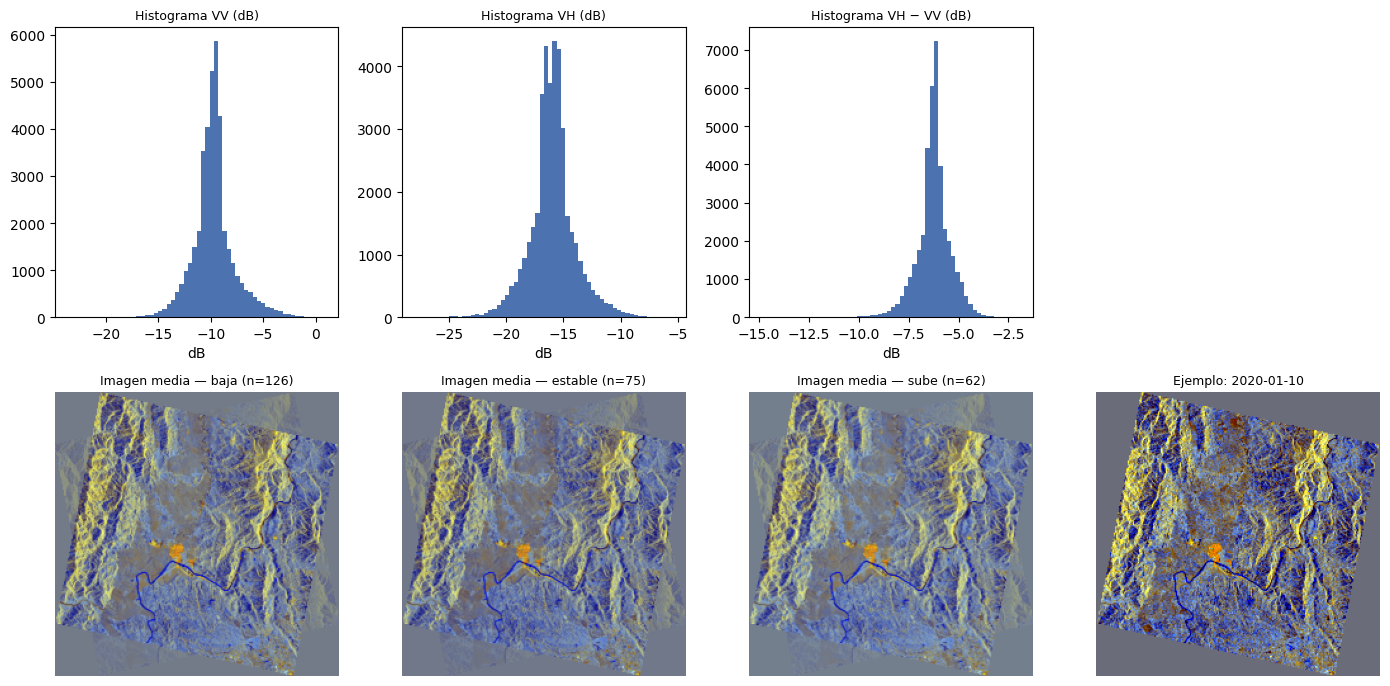

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 200MB/s]


Extracción ResNet-18: dimensión 512, alfa=10000, MAE val 9.684 cm
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 113MB/s]


Extracción EfficientNet-B0: dimensión 1280, alfa=10000, MAE val 10.595 cm
   ResNet-18 s0 época 1/25 | MAE val 10.19 cm | 18:21:30
   ResNet-18 s0 época 5/25 | MAE val 14.03 cm | 18:21:31
   ResNet-18 s0 época 10/25 | MAE val 9.68 cm | 18:21:33
   ResNet-18 s0 época 15/25 | MAE val 9.75 cm | 18:21:35
   ResNet-18 s0 época 20/25 | MAE val 10.03 cm | 18:21:37
   ResNet-18 s0 época 25/25 | MAE val 9.57 cm | 18:21:38
Ajuste fino ResNet-18 semilla 0: mejor época 16, MAE val 9.473 cm
   ResNet-18 s1 época 1/25 | MAE val 23.49 cm | 18:21:45
   ResNet-18 s1 época 5/25 | MAE val 12.73 cm | 18:21:47
   ResNet-18 s1 época 10/25 | MAE val 11.72 cm | 18:21:48
   ResNet-18 s1 época 15/25 | MAE val 10.85 cm | 18:21:50
   ResNet-18 s1 época 20/25 | MAE val 10.22 cm | 18:21:52
   ResNet-18 s1 época 25/25 | MAE val 9.89 cm | 18:21:54
Ajuste fino ResNet-18 semilla 1: mejor época 25, MAE val 9.887 cm
   ResNet-18 s2 época 1/25 | MAE val 11.84 cm | 18:21:59
   ResNet-18 s2 época 5/25 | MAE val 11.03 cm | 1

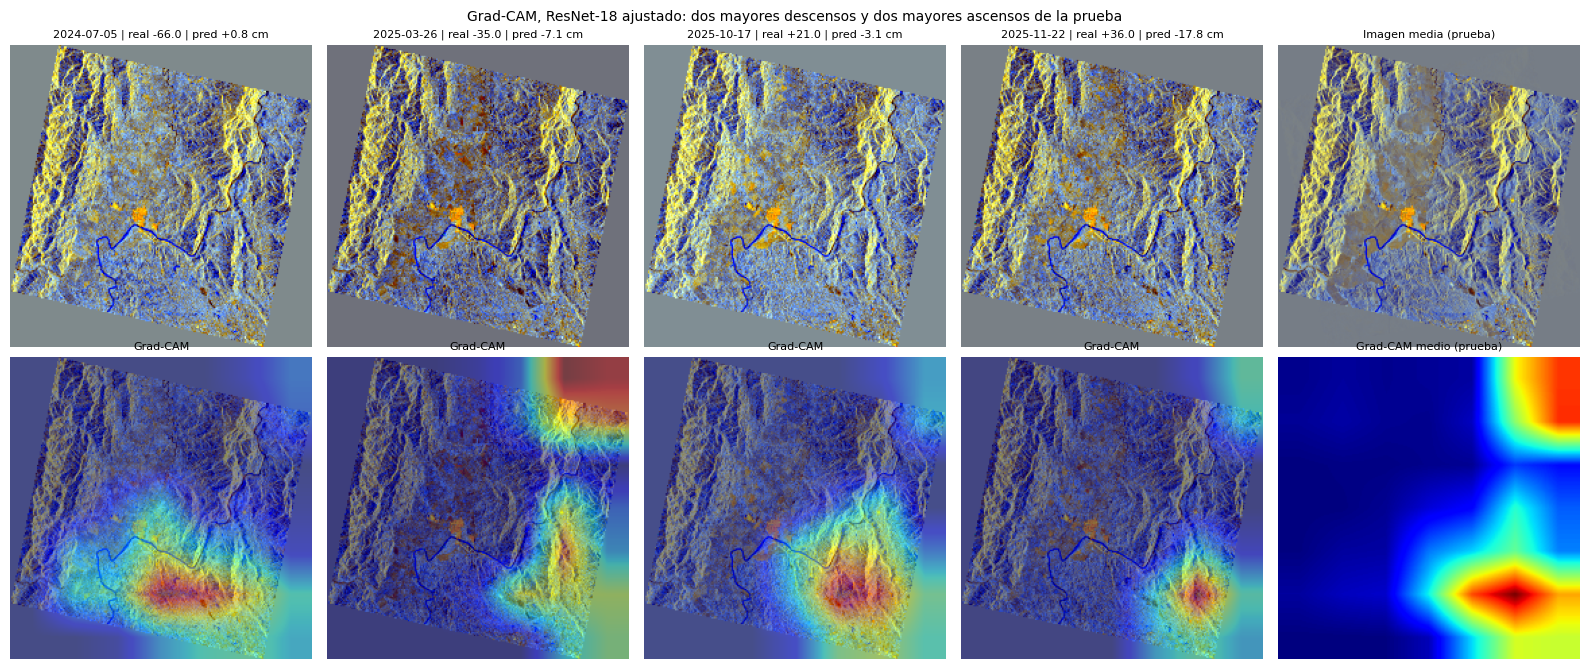

Lectura: Grad-CAM muestra dónde mira la red, no demuestra causalidad. Si el MAE no mejora la referencia, el mapa describe una red que no aprendió una señal útil.


In [37]:
# ============================================================
# CELDA 2.26 — RAMA A: CNN PREENTRENADAS SOBRE LOS RECORTES SAR (ResNet-18 y EfficientNet-B0)
# Tarea: predecir el CAMBIO de nivel a +24 h (cm) desde la imagen SAR de la escena.
# Estrategias, fijadas antes de ver resultados:
#   1) EXTRACCIÓN DE CARACTERÍSTICAS: red congelada + regresión Ridge (alfa elegido en validación).
#   2) AJUSTE FINO (fine-tuning): se entrena toda la red (AdamW, lr 1e-4, 25 épocas máx., MSE), 3 semillas;
#      se conserva la época de menor MAE de validación. Sin aumento de datos (la 3.4 no mostró beneficio).
# Referencias: "cambio = 0" (persistencia) y la mediana del cambio en entrenamiento.
# Incluye análisis exploratorio de las imágenes y Grad-CAM del ResNet-18 ajustado.
# Requiere la 2.25.
# ============================================================
import time
SEMILLAS_A = [0, 1, 2]
EPOCAS_A = 25
ALFAS_RIDGE = [1, 10, 100, 1000, 10000]
NOMBRES_BB = ["ResNet-18", "EfficientNet-B0"]
NOMBRE_CLASE_AC = {0: "baja", 1: "estable", 2: "sube"}
CARPETA_PESOS_A = os.path.join(CARPETA_FASE_2, "pesos")

# ---------------- A.1 Análisis exploratorio de las imágenes ----------------------------------
print("A.1 EXPLORACIÓN DE LAS IMÁGENES")
filas_eda = []
for c_id, c_nom in NOMBRE_CLASE_AC.items():
    sel = np.where(clase_c == c_id)[0]
    medias = [float(chips_c[sel, k].astype("float32").mean()) for k in range(3)]
    filas_eda.append({"clase": c_nom, "escenas": len(sel), "VV_dB_medio": medias[0],
                      "VH_dB_medio": medias[1], "VH-VV_dB_medio": medias[2]})
print(pd.DataFrame(filas_eda).round(2).to_string(index=False))
print("Escenas por año:", pd.Series(fechas_c.year).value_counts().sort_index().to_dict())

fig, ejes = plt.subplots(2, 4, figsize=(14, 7))
rng_eda = np.random.default_rng(0)
for k, (nom_c, eje) in enumerate(zip(["VV (dB)", "VH (dB)", "VH − VV (dB)"], ejes[0, :3])):
    muestra = chips_c[rng_eda.choice(n_c, size=min(40, n_c), replace=False), k].astype("float32").ravel()
    eje.hist(muestra[::50], bins=60, color="#4c72b0")
    eje.set_title("Histograma " + nom_c, fontsize=9); eje.set_xlabel("dB")
ejes[0, 3].axis("off")
for c_id, eje in zip(range(3), ejes[1, :3]):
    sel = np.where(clase_c == c_id)[0]
    eje.imshow(T01[sel].mean(0).permute(1, 2, 0).numpy())
    eje.set_title(f"Imagen media — {NOMBRE_CLASE_AC[c_id]} (n={len(sel)})", fontsize=9); eje.axis("off")
ejes[1, 3].imshow(T01[0].permute(1, 2, 0).numpy())
ejes[1, 3].set_title(f"Ejemplo: {fechas_c[0]:%Y-%m-%d}", fontsize=9); ejes[1, 3].axis("off")
plt.tight_layout(); plt.show()

# ---------------- A.2 Extracción de características + Ridge ---------------------------------
filas_a = []
for nombre in NOMBRES_BB:
    F = obtener_features(nombre)
    esc = StandardScaler().fit(F[idx_ent])
    Fs = esc.transform(F)
    mejor = None
    for alfa in ALFAS_RIDGE:
        r = Ridge(alpha=alfa).fit(Fs[idx_ent], cambio_c[idx_ent])
        mv = mae_np(r.predict(Fs[idx_val]), cambio_c[idx_val])
        if mejor is None or mv < mejor[0]:
            mejor = (mv, alfa, r)
    mv, alfa, r = mejor
    filas_a.append({"modelo": nombre, "estrategia": "Extracción (congelada + Ridge)", "semilla": -1,
                    "detalle": f"alfa={alfa}", "MAE_val_cm": mv,
                    "MAE_pru_cm": mae_np(r.predict(Fs[idx_pru]), cambio_c[idx_pru])})
    print(f"Extracción {nombre}: dimensión {F.shape[1]}, alfa={alfa}, MAE val {mv:.3f} cm")

# ---------------- A.3 Ajuste fino ------------------------------------------------------------
class RedRegresion(torch.nn.Module):
    def __init__(self, nombre):
        super(RedRegresion, self).__init__()
        self.backbone, d = crear_backbone(nombre)
        self.cabeza = torch.nn.Sequential(torch.nn.Dropout(0.2), torch.nn.Linear(d, 1))

    def forward(self, x):
        return self.cabeza(self.backbone(x))

def predecir_cm(red, idx):
    red.eval()
    salidas = []
    with torch.no_grad():
        for i in range(0, len(idx), 32):
            xb = T_img[idx[i:i + 32]].to(dispositivo)
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=usa_amp):
                salidas.append(red(xb).float().squeeze(1).cpu().numpy())
    return np.concatenate(salidas) * desv_y

def afinar(nombre, semilla_r):
    torch.manual_seed(semilla_r); np.random.seed(semilla_r); random.seed(semilla_r)
    g = torch.Generator(); g.manual_seed(semilla_r)
    red = RedRegresion(nombre).to(dispositivo)
    opt = torch.optim.AdamW(red.parameters(), lr=1e-4, weight_decay=1e-4)
    escalador = torch.amp.GradScaler("cuda", enabled=usa_amp)
    y_norm = torch.tensor(cambio_c / desv_y, dtype=torch.float32)
    mejor_v, mejor_estado, mejor_ep = float("inf"), None, 0
    for ep in range(1, EPOCAS_A + 1):
        red.train()
        perm = idx_ent[torch.randperm(len(idx_ent), generator=g).numpy()]
        for i in range(0, len(perm), 32):
            b = perm[i:i + 32]
            if len(b) < 2:
                continue
            xb, yb = T_img[b].to(dispositivo), y_norm[b].to(dispositivo)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=usa_amp):
                perdida = torch.nn.functional.mse_loss(red(xb).float().squeeze(1), yb)
            escalador.scale(perdida).backward()
            escalador.step(opt); escalador.update()
        mv = mae_np(predecir_cm(red, idx_val), cambio_c[idx_val])
        if ep == 1 or ep % 5 == 0:
            print(f"   {nombre} s{semilla_r} época {ep}/{EPOCAS_A} | MAE val {mv:.2f} cm | {time.strftime('%H:%M:%S')}", flush=True)
        if mv < mejor_v:
            mejor_v, mejor_ep, mejor_estado = mv, ep, copy.deepcopy(red.state_dict())
    red.load_state_dict(mejor_estado)
    os.makedirs(CARPETA_PESOS_A, exist_ok=True)
    torch.save(mejor_estado, os.path.join(CARPETA_PESOS_A, f"rama_a_{nombre}_semilla{semilla_r}.pth"))
    fila = {"modelo": nombre, "estrategia": "Ajuste fino (toda la red)", "semilla": semilla_r,
            "detalle": f"mejor época {mejor_ep}", "MAE_val_cm": mejor_v,
            "MAE_pru_cm": mae_np(predecir_cm(red, idx_pru), cambio_c[idx_pru])}
    return fila, red

red_gradcam = None
for nombre in NOMBRES_BB:
    for s in SEMILLAS_A:
        fila, red = afinar(nombre, s)
        filas_a.append(fila)
        print(f"Ajuste fino {nombre} semilla {s}: {fila['detalle']}, MAE val {fila['MAE_val_cm']:.3f} cm")
        if nombre == "ResNet-18" and s == SEMILLAS_A[0]:
            red_gradcam = red
        else:
            del red
        gc.collect()
        if usa_amp:
            torch.cuda.empty_cache()

# ---------------- A.4 Resultados (la prueba se lee aquí, una sola vez) -----------------------
for nombre_b, valor_b in [("Referencia: cambio = 0 (persistencia)", np.zeros(n_c)),
                          ("Referencia: mediana de entrenamiento", np.full(n_c, np.median(cambio_c[idx_ent])))]:
    filas_a.append({"modelo": nombre_b, "estrategia": "—", "semilla": -1, "detalle": "",
                    "MAE_val_cm": mae_np(valor_b[idx_val], cambio_c[idx_val]),
                    "MAE_pru_cm": mae_np(valor_b[idx_pru], cambio_c[idx_pru])})
df_a = pd.DataFrame(filas_a)
resumen_a = (df_a.groupby(["modelo", "estrategia"], sort=False)[["MAE_val_cm", "MAE_pru_cm"]]
             .agg(["mean", "std"]).round(3))
print("\nRAMA A — MAE del cambio a +24 h (cm); media y desviación entre semillas (extracción y referencias: un solo valor)")
print(resumen_a.to_string())
df_a.to_csv(os.path.join(CARPETA_FASE_2, "centinela_rama_a_cnn.csv"), index=False, encoding="utf-8-sig")

# ---------------- A.5 Grad-CAM del ResNet-18 ajustado (semilla 0) ----------------------------
def mapas_gradcam(red, idx):
    red.eval()
    mapas = []
    for i in range(0, len(idx), 8):
        acts, grads = [], []
        def hook_f(m, entrada, salida):
            acts.append(salida)
            salida.register_hook(lambda g: grads.append(g))
        h = red.backbone.layer4.register_forward_hook(hook_f)
        red.zero_grad()
        with torch.enable_grad():
            red(T_img[idx[i:i + 8]].to(dispositivo)).sum().backward()
        h.remove()
        a, gr = acts[0].detach(), grads[0].detach()
        w = gr.mean(dim=(2, 3), keepdim=True)
        cam = torch.relu((w * a).sum(1, keepdim=True))
        cam = torch.nn.functional.interpolate(cam, size=(224, 224), mode="bilinear", align_corners=False)
        cam = cam / (cam.amax(dim=(1, 2, 3), keepdim=True) + 1e-8)
        mapas.append(cam.squeeze(1).cpu().numpy())
    return np.concatenate(mapas)

cams = mapas_gradcam(red_gradcam, idx_pru)
pred_pru_g = predecir_cm(red_gradcam, idx_pru)
orden_c = np.argsort(cambio_c[idx_pru])
elegidas = [orden_c[0], orden_c[1], orden_c[-2], orden_c[-1]]
fig, ejes = plt.subplots(2, 5, figsize=(16, 6.8))
for col, k in enumerate(elegidas):
    i_glob = idx_pru[k]
    ejes[0, col].imshow(T01[i_glob].permute(1, 2, 0).numpy())
    ejes[0, col].set_title(f"{fechas_c[i_glob]:%Y-%m-%d} | real {cambio_c[i_glob]:+.1f} | pred {pred_pru_g[k]:+.1f} cm", fontsize=8)
    ejes[1, col].imshow(T01[i_glob].permute(1, 2, 0).numpy())
    ejes[1, col].imshow(cams[k], cmap="jet", alpha=0.45)
    ejes[1, col].set_title("Grad-CAM", fontsize=8)
ejes[0, 4].imshow(T01[idx_pru].mean(0).permute(1, 2, 0).numpy()); ejes[0, 4].set_title("Imagen media (prueba)", fontsize=8)
ejes[1, 4].imshow(cams.mean(0), cmap="jet"); ejes[1, 4].set_title("Grad-CAM medio (prueba)", fontsize=8)
for a in ejes.ravel():
    a.axis("off")
plt.suptitle("Grad-CAM, ResNet-18 ajustado: dos mayores descensos y dos mayores ascensos de la prueba", fontsize=10)
plt.tight_layout(); plt.show()
print("Lectura: Grad-CAM muestra dónde mira la red, no demuestra causalidad. Si el MAE no mejora la referencia, "
      "el mapa describe una red que no aprendió una señal útil.")

**Lectura de la Rama A.** MAE del cambio a +24 h en prueba (cm): extracción ResNet-18 11.75 y EfficientNet-B0 11.91; ajuste fino ResNet-18 12.25 y EfficientNet-B0 12.20; referencia "cambio = 0" 12.58 y mediana de entrenamiento 12.03. En validación el ajuste fino de EfficientNet-B0 parece mejor (8.87 frente a 9.90 y 10.31 de las referencias), pero esa época se eligió con la propia validación y en prueba la ventaja desaparece. Ridge eligió el alfa más alto de la rejilla, otra señal de que las características de imagen aportan poco por sí solas. **No hay evidencia de que la imagen sola prediga el cambio de nivel.** Grad-CAM describe dónde mira una red que no aprendió una señal útil; no se interpreta como evidencia física.

### 2.27 Rama C — fusión tardía (concatenación de embeddings) y ablación
Rama imagen: características de ResNet-18 congeladas → Linear(32). Rama serie: GRU de 32 unidades. Concatenación (64) → cabeza → cambio de nivel a +24 h. Ablación con 5 semillas: solo imagen, solo serie, fusión, y un control con imágenes barajadas entre escenas. Bootstrap por escenas sobre la prueba.

In [38]:
# ============================================================
# CELDA 2.27 — RAMA C: FUSIÓN TARDÍA (CONCATENACIÓN DE EMBEDDINGS) CNN + GRU, CON ABLACIÓN
# Rama imagen: características de ResNet-18 congelado (512) -> Dropout 0.3 -> Linear(32) -> ReLU.
# Rama serie: GRU de 32 unidades sobre la ventana de 14 niveles (hasta el ancla) -> último estado oculto.
# Fusión: concatenación (64) -> Linear(16) -> ReLU -> Linear(1) = cambio normalizado de nivel a +24 h.
# Ablación (reglas fijadas antes de ver resultados), 5 semillas cada una:
#   Solo imagen | Solo serie | Fusión | Control: fusión con imágenes barajadas entre escenas (rompe el emparejamiento).
# Entrenamiento: Adam lr 1e-3, weight decay 1e-3, lote 32, máx. 150 épocas, parada si 15 épocas sin mejorar el MAE
# de validación. Se reportan TODAS las variantes y las referencias; la prueba se lee una sola vez, al final.
# Requiere la 2.25 (y la 2.26 no es necesaria).
# ============================================================
SEMILLAS_C = [0, 1, 2, 3, 4]
MAX_EP_C, PACIENCIA_C = 150, 15

F_img = obtener_features("ResNet-18")
F_est = ((F_img - F_img[idx_ent].mean(0)) / (F_img[idx_ent].std(0) + 1e-6)).astype("float32")
m_s, d_s = float(serie_c[idx_ent].mean()), float(serie_c[idx_ent].std())
S_est = ((serie_c - m_s) / d_s).astype("float32")
perm_fija = np.random.default_rng(123).permutation(n_c)

F_t = torch.tensor(F_est).to(dispositivo)
S_t = torch.tensor(S_est).unsqueeze(-1).to(dispositivo)
Y_t = torch.tensor(cambio_c / desv_y, dtype=torch.float32).to(dispositivo)

class Fusion(torch.nn.Module):
    def __init__(self, d_img, usar_img, usar_ser, oculto=32, p=0.3):
        super(Fusion, self).__init__()
        self.rama_img = (torch.nn.Sequential(torch.nn.Dropout(p), torch.nn.Linear(d_img, oculto), torch.nn.ReLU())
                         if usar_img else None)
        self.gru = torch.nn.GRU(1, oculto, batch_first=True) if usar_ser else None
        n_in = oculto * (int(usar_img) + int(usar_ser))
        self.cabeza = torch.nn.Sequential(torch.nn.Linear(n_in, 16), torch.nn.ReLU(), torch.nn.Linear(16, 1))

    def forward(self, f, s):
        z = []
        if self.rama_img is not None:
            z.append(self.rama_img(f))
        if self.gru is not None:
            _, h = self.gru(s)
            z.append(h[-1])
        return self.cabeza(torch.cat(z, dim=1))

def pred_todas(red, Fm):
    red.eval()
    with torch.no_grad():
        return red(Fm, S_t).squeeze(1).cpu().numpy() * desv_y

def entrenar_fusion(usar_img, usar_ser, semilla_r, barajar=False):
    torch.manual_seed(semilla_r); np.random.seed(semilla_r)
    g = torch.Generator(); g.manual_seed(semilla_r)
    Fm = F_t[torch.tensor(perm_fija).to(dispositivo)] if barajar else F_t
    red = Fusion(F_t.shape[1], usar_img, usar_ser).to(dispositivo)
    opt = torch.optim.Adam(red.parameters(), lr=1e-3, weight_decay=1e-3)
    mejor_v, mejor_estado, mejor_ep, sin_mejora = float("inf"), None, 0, 0
    for ep in range(1, MAX_EP_C + 1):
        red.train()
        perm = idx_ent[torch.randperm(len(idx_ent), generator=g).numpy()]
        for i in range(0, len(perm), 32):
            b = torch.tensor(perm[i:i + 32]).to(dispositivo)
            opt.zero_grad()
            perdida = torch.nn.functional.mse_loss(red(Fm[b], S_t[b]).squeeze(1), Y_t[b])
            perdida.backward(); opt.step()
        mv = mae_np(pred_todas(red, Fm)[idx_val], cambio_c[idx_val])
        if mv < mejor_v - 1e-4:
            mejor_v, mejor_ep, sin_mejora = mv, ep, 0
            mejor_estado = copy.deepcopy(red.state_dict())
        else:
            sin_mejora += 1
            if sin_mejora >= PACIENCIA_C:
                break
    red.load_state_dict(mejor_estado)
    if semilla_r == SEMILLAS_C[0]:
        os.makedirs(os.path.join(CARPETA_FASE_2, "pesos"), exist_ok=True)
        nombre_arch = "rama_c_" + ("img" if usar_img else "") + ("ser" if usar_ser else "") + ("_barajada" if barajar else "") + ".pth"
        torch.save(mejor_estado, os.path.join(CARPETA_FASE_2, "pesos", nombre_arch))
    return pred_todas(red, Fm), mejor_ep

variantes_c = {
    "Solo imagen": (True, False, False),
    "Solo serie (GRU)": (False, True, False),
    "Fusión imagen + serie": (True, True, False),
    "Control: fusión con imágenes barajadas": (True, True, True),
}
filas_c, preds_c = [], {}
for nombre, (ui, us, bar) in variantes_c.items():
    preds_c[nombre] = []
    for s in SEMILLAS_C:
        p, ep = entrenar_fusion(ui, us, s, barajar=bar)
        preds_c[nombre].append(p)
        filas_c.append({"variante": nombre, "semilla": s, "mejor_época": ep,
                        "MAE_val_cm": mae_np(p[idx_val], cambio_c[idx_val]),
                        "MAE_pru_cm": mae_np(p[idx_pru], cambio_c[idx_pru])})
    print(f"{nombre}: listo (5 semillas)")

for nombre_b, valor_b in [("Referencia: cambio = 0 (persistencia)", np.zeros(n_c)),
                          ("Referencia: mediana de entrenamiento", np.full(n_c, np.median(cambio_c[idx_ent])))]:
    preds_c[nombre_b] = [valor_b]
    filas_c.append({"variante": nombre_b, "semilla": -1, "mejor_época": np.nan,
                    "MAE_val_cm": mae_np(valor_b[idx_val], cambio_c[idx_val]),
                    "MAE_pru_cm": mae_np(valor_b[idx_pru], cambio_c[idx_pru])})
df_c = pd.DataFrame(filas_c)
resumen_c = df_c.groupby("variante", sort=False)[["MAE_val_cm", "MAE_pru_cm"]].agg(["mean", "std"]).round(3)
print(f"\nRAMA C — MAE del cambio a +24 h (cm). Validación {len(idx_val)} y prueba {len(idx_pru)} escenas; media y desviación entre 5 semillas")
print(resumen_c.to_string())
df_c.to_csv(os.path.join(CARPETA_FASE_2, "centinela_rama_c_fusion.csv"), index=False, encoding="utf-8-sig")

# --- Bootstrap por escenas sobre la prueba (predicción promedio de las 5 semillas) ---------------
ens = {k: np.mean(v, axis=0) for k, v in preds_c.items()}
err = {k: np.abs(ens[k][idx_pru] - cambio_c[idx_pru]) for k in ens}
rng_b = np.random.default_rng(0)
indices_b = rng_b.integers(0, len(idx_pru), size=(2000, len(idx_pru)))
pares = [("Fusión imagen + serie", "Solo serie (GRU)"), ("Fusión imagen + serie", "Solo imagen"),
         ("Fusión imagen + serie", "Control: fusión con imágenes barajadas"),
         ("Fusión imagen + serie", "Referencia: cambio = 0 (persistencia)"),
         ("Solo serie (GRU)", "Referencia: cambio = 0 (persistencia)")]
filas_bt = []
for a, b in pares:
    d = err[a] - err[b]
    medias_b = d[indices_b].mean(axis=1)
    filas_bt.append({"A": a, "B": b, "MAE_A_menos_B_cm": float(d.mean()),
                     "IC95_inf": float(np.percentile(medias_b, 2.5)), "IC95_sup": float(np.percentile(medias_b, 97.5)),
                     "IC_excluye_0": bool(np.percentile(medias_b, 2.5) > 0 or np.percentile(medias_b, 97.5) < 0)})
tabla_bt = pd.DataFrame(filas_bt)
print("\nBootstrap por escenas en prueba (negativo = A mejor que B; 2000 remuestreos):")
print(tabla_bt.round(3).to_string(index=False))
tabla_bt.to_csv(os.path.join(CARPETA_FASE_2, "centinela_rama_c_bootstrap.csv"), index=False, encoding="utf-8-sig")
print("\nLectura: una mejora solo cuenta si el intervalo excluye 0 y la fusión supera a 'Solo serie' y al control barajado. "
      "Con pocas escenas de prueba y escenas de la órbita 48 casi solo en entrenamiento, un resultado negativo es esperable.")

Solo imagen: listo (5 semillas)
Solo serie (GRU): listo (5 semillas)
Fusión imagen + serie: listo (5 semillas)
Control: fusión con imágenes barajadas: listo (5 semillas)

RAMA C — MAE del cambio a +24 h (cm). Validación 39 y prueba 40 escenas; media y desviación entre 5 semillas
                                       MAE_val_cm        MAE_pru_cm       
                                             mean    std       mean    std
variante                                                                  
Solo imagen                                 9.585  0.192     11.975  0.563
Solo serie (GRU)                            9.734  0.232     11.829  0.126
Fusión imagen + serie                       9.112  0.106     11.400  0.383
Control: fusión con imágenes barajadas      9.950  0.161     12.031  0.247
Referencia: cambio = 0 (persistencia)      10.308    NaN     12.575    NaN
Referencia: mediana de entrenamiento        9.897    NaN     12.025    NaN

Bootstrap por escenas en prueba (negativo = 

**Lectura de la Rama C (resultado no concluyente).** MAE en prueba (cm): fusión 11.40; solo serie 11.83; solo imagen 11.98; fusión con imágenes barajadas 12.03; "cambio = 0" 12.58. La fusión es la mejor variante tanto en validación (9.11) como en prueba y el control barajado es el peor, es decir, la dirección es la esperada. Sin embargo, con 40 escenas de prueba el intervalo bootstrap de la diferencia incluye 0 frente a "solo serie" (−0.61 cm; IC95 −1.96 a 0.67), frente al control barajado y frente a "cambio = 0"; solo excluye 0 frente a "solo imagen". La mejora media de la fusión sobre la serie sola es de aproximadamente 3 a 4 %. **No se puede afirmar que la imagen aporte en esta rama**; la evidencia más fuerte del efecto del SAR es la de las celdas 2.21 a 2.23, con validación por bloques (136 escenas de prueba).

---
### Resumen e interpretación
**Pregunta principal:** ¿mejora el radar Sentinel-1 (a lo largo del cauce) la predicción del nivel del río a +24 h en La Virginia?

* **+12 h (pregunta original):** no hay evidencia de aporte del SAR.
* **+24 h y +36 h:** con validación por bloques (136 escenas de prueba) el modelo con SAR gana en los 5 bloques y su MAE global baja de 13.70 a 11.54 cm a +24 h y de 21.02 a 17.78 cm a +36 h. Supera al SAR barajado, al reloj y al SAR de la escena anterior; los intervalos bootstrap excluyen 0 (frente al SAR de la escena anterior a +24 h el intervalo roza 0). La red profunda GRU + CNN confirma la dirección (mejora de unos 0.9 cm).
* **Control por órbita (2.23):** saber de qué órbita viene la escena no explica la mejora (órbita sola: −0.14 cm a +24 h, IC que incluye 0); "órbita + SAR" frente a solo órbita mejora −1.97 cm con IC que excluye 0. La órbita 48 tiene solo 7 escenas en la prueba, por lo que no se puede evaluar por separado.
* **+48 h:** no concluyente.
* **Rama B:** las redes recurrentes no superan a la persistencia.
* **Rama A:** las CNN sobre imágenes solas no superan a las referencias en prueba.
* **Rama C:** la fusión es la mejor variante, pero la diferencia no es estadísticamente concluyente con 40 escenas de prueba.
* **Fase 1 (modelo binario):** el MLP binario (F1 0.486, AUC 0.653) apenas supera a la regla "siempre sube" (F1 0.476); la formulación binaria no es adecuada y la regresión original sigue como formulación principal.

**Limitaciones:** el horizonte principal (+24 h) se fijó después de explorar otros horizontes; hay 275 escenas procesadas (271 utilizables) y no 500; una sola estación; la órbita 48 está casi toda en entrenamiento; hay una escena excluida (2020-09-13) por un error de lectura; el resultado es una asociación estadística, no demuestra causalidad ni capacidad de alerta de inundación.